# FinReason: Explainable Graph and Rule-Based Financial Anomaly Detection

## Project sections

1. Setup and reproducibility
2. Data acquisition and caching
3. Validation, cleaning and harmonisation
4. Temporal transaction graph construction
5. BFS fan-out and fan-in detection
6. DFS layering and circular-flow detection
7. Knowledge representation models
8. Forward chaining and hybrid integration
9. Statistical baselines
10. Evaluation and trade-off analysis
11. Testing, performance

# Section 1 - Setup and reproducibility

### 1.1 Standard-library imports and project root

In [1]:
from __future__ import annotations

import importlib.metadata as importlib_metadata
import importlib.util
import json
import logging
import os
import platform
import random
import re
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

def find_project_root(start: Path) -> Path:
    candidates = [start.resolve(), *start.resolve().parents]
    for candidate in candidates:
        if (candidate / 'finreason_synthetic_dataset').exists():
            return candidate
    return start.resolve()

PROJECT_ROOT = find_project_root(Path.cwd())
REQUIREMENTS_FILE = PROJECT_ROOT / 'requirements.txt'
print(f'Project root: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

Project root: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason
Python: 3.10.5


### 1.2 Dependency audit

In [2]:
PACKAGE_IMPORTS = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'networkx': 'networkx',
    'matplotlib': 'matplotlib',
    'gdown': 'gdown',
    'psutil': 'psutil',
}

dependency_report = []
for package_name, import_name in PACKAGE_IMPORTS.items():
    installed = importlib.util.find_spec(import_name) is not None
    try:
        version = importlib_metadata.version(package_name) if installed else None
    except importlib_metadata.PackageNotFoundError:
        version = 'installed (version unavailable)' if installed else None
    dependency_report.append({
        'package': package_name,
        'import': import_name,
        'installed': installed,
        'version': version,
    })

missing_packages = [row['package'] for row in dependency_report if not row['installed']]
for row in dependency_report:
    status = f"OK ({row['version']})" if row['installed'] else 'MISSING'
    print(f"{row['package']:<16} {status}")

if missing_packages:
    print('\nInstall before Section 2 with:')
    print(f'  {sys.executable} -m pip install -r {REQUIREMENTS_FILE}')
else:
    print('\nAll runtime dependencies are available.')

numpy            OK (1.24.3)
pandas           OK (2.2.3)
networkx         OK (3.4.2)
matplotlib       OK (3.10.0)
gdown            OK (5.2.2)
psutil           OK (7.0.0)

All runtime dependencies are available.


### 1.3 Optional dependency installation

In [3]:
INSTALL_MISSING_PACKAGES = False

if INSTALL_MISSING_PACKAGES and missing_packages:
    if not REQUIREMENTS_FILE.exists():
        raise FileNotFoundError(f'Requirements file not found: {REQUIREMENTS_FILE}')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(REQUIREMENTS_FILE)])
    print('Dependencies installed. Restart the notebook kernel, then rerun Section 1.')
elif missing_packages:
    print(f'Installation skipped. Missing: {missing_packages}')
else:
    print('Nothing to install.')

Nothing to install.


### 1.4 Deterministic execution

In [4]:
RANDOM_SEED = 20250713
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)

if importlib.util.find_spec('numpy') is not None:
    import numpy as np
    np.random.seed(RANDOM_SEED)

print(f'Deterministic seed configured: {RANDOM_SEED}')

Deterministic seed configured: 20250713


### 1.5 Directory structure

In [5]:
WORKSPACE_DIR = PROJECT_ROOT / 'workspace'
DATA_DIR = Path(os.getenv('FINREASON_DATA_DIR', str(WORKSPACE_DIR / 'data'))).expanduser().resolve()
PATHS = {
    'raw': DATA_DIR / 'raw',
    'interim': DATA_DIR / 'interim',
    'processed': DATA_DIR / 'processed',
    'cache': WORKSPACE_DIR / 'cache',
    'figures': WORKSPACE_DIR / 'outputs' / 'figures',
    'tables': WORKSPACE_DIR / 'outputs' / 'tables',
    'audit_trails': WORKSPACE_DIR / 'outputs' / 'audit_trails',
    'logs': WORKSPACE_DIR / 'outputs' / 'logs',
}
for path in PATHS.values():
    path.mkdir(parents=True, exist_ok=True)

for name, path in PATHS.items():
    print(f'{name:<14} {path}')

raw            /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw
interim        /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/interim
processed      /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/processed
cache          /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/cache
figures        /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/figures
tables         /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/tables
audit_trails   /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails
logs           /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/logs


### 1.6 Data-source and experiment configuration

In [6]:
DATA_SOURCES = {
    'finreason': {
        'drive_file_id': '1BljEQOgTCk_LHcwC2j4jhVU7vT25aF2L',
        'archive_name': 'FinReason_Synthetic_Dataset_v1.0.0.zip',
        'expected_sha256': '546e8aa20942c7d9adf7533237fc497a711cc83a20b6e624d9d55c16b0168a2a',
    },
    'paysim': {
        'drive_file_id': '1Lh8djaX-RxSD7FHGqD_-QTc64BtErBn_',
        'download_name': 'paysim_drive_download',
        'sample_fraction': 0.10,
    },
    'ibm_aml': {
        'drive_file_id': '1AuOfEYvDDn2i6lblBPn9twjRDVWUSR1l',
        'download_name': 'IBM_AML_Dataset_drive_download',
        'transaction_file': 'HI-Small_Trans.csv',
        'transaction_expected_bytes': 475_664_283,
        'pattern_file': 'HI-Small_Patterns.txt',
        'minimum_free_gib': 0.70,
    },
}

EXPERIMENT_CONFIG = {
    'random_seed': RANDOM_SEED,
    'train_fraction': 0.60,
    'validation_fraction': 0.20,
    'test_fraction': 0.20,
    'graph_window_hours': 24,
    'rolling_frequency_window_hours': 48,
    'rolling_frequency_minimum_count': 4,
    'rolling_frequency_transaction_types': ('TRANSFER',),
    'stream_partition_hours': 168,
    'maximum_bfs_depth': 2,
    'maximum_dfs_depth': 6,
    'minimum_fan_counterparties': 4,
    'minimum_layering_edges': 4,
    'minimum_amount_retention': 0.95,
    'rapid_pass_through_minutes': 30,
    'ibm_chunk_rows': 250_000,
}

print(json.dumps({'data_sources': DATA_SOURCES, 'experiment': EXPERIMENT_CONFIG}, indent=2))

{
  "data_sources": {
    "finreason": {
      "drive_file_id": "1BljEQOgTCk_LHcwC2j4jhVU7vT25aF2L",
      "archive_name": "FinReason_Synthetic_Dataset_v1.0.0.zip",
      "expected_sha256": "546e8aa20942c7d9adf7533237fc497a711cc83a20b6e624d9d55c16b0168a2a"
    },
    "paysim": {
      "drive_file_id": "1Lh8djaX-RxSD7FHGqD_-QTc64BtErBn_",
      "download_name": "paysim_drive_download",
      "sample_fraction": 0.1
    },
    "ibm_aml": {
      "drive_file_id": "1AuOfEYvDDn2i6lblBPn9twjRDVWUSR1l",
      "download_name": "IBM_AML_Dataset_drive_download",
      "transaction_file": "HI-Small_Trans.csv",
      "transaction_expected_bytes": 475664283,
      "pattern_file": "HI-Small_Patterns.txt",
      "minimum_free_gib": 0.7
    }
  },
  "experiment": {
    "random_seed": 20250713,
    "train_fraction": 0.6,
    "validation_fraction": 0.2,
    "test_fraction": 0.2,
    "graph_window_hours": 24,
    "rolling_frequency_window_hours": 48,
    "rolling_frequency_minimum_count": 4,
    "rolling_

### 1.7 Logging and environment diagnostics

In [7]:
LOGGER = logging.getLogger('finreason')
LOGGER.setLevel(logging.INFO)
LOGGER.handlers.clear()
formatter = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s')
stream_handler = logging.StreamHandler(sys.stdout)
stream_handler.setFormatter(formatter)
file_handler = logging.FileHandler(PATHS['logs'] / 'finreason.log', encoding='utf-8')
file_handler.setFormatter(formatter)
LOGGER.addHandler(stream_handler)
LOGGER.addHandler(file_handler)
LOGGER.propagate = False

environment = {
    'timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'processor': platform.processor() or 'not reported',
    'cpu_count': os.cpu_count(),
    'project_root': str(PROJECT_ROOT),
}
if importlib.util.find_spec('psutil') is not None:
    import psutil
    environment['memory_gib'] = round(psutil.virtual_memory().total / (1024 ** 3), 2)

LOGGER.info('FinReason Section 1 environment configured')
print(json.dumps(environment, indent=2))

2026-08-07 21:12:10,158 | INFO | FinReason Section 1 environment configured


{
  "timestamp_utc": "2026-08-07T15:42:10.157860+00:00",
  "python": "3.10.5",
  "platform": "macOS-14.6.1-arm64-arm-64bit",
  "processor": "arm",
  "cpu_count": 8,
  "project_root": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason",
  "memory_gib": 8.0
}


### 1.8 Setup checks

In [8]:
drive_id_pattern = re.compile(r'^[A-Za-z0-9_-]{20,}$')
assert drive_id_pattern.fullmatch(DATA_SOURCES['finreason']['drive_file_id'])
assert drive_id_pattern.fullmatch(DATA_SOURCES['paysim']['drive_file_id'])
assert drive_id_pattern.fullmatch(DATA_SOURCES['ibm_aml']['drive_file_id'])
assert abs(
    EXPERIMENT_CONFIG['train_fraction']
    + EXPERIMENT_CONFIG['validation_fraction']
    + EXPERIMENT_CONFIG['test_fraction']
    - 1.0
) < 1e-12
assert all(path.exists() and path.is_dir() for path in PATHS.values())
assert EXPERIMENT_CONFIG['maximum_bfs_depth'] >= 1
assert EXPERIMENT_CONFIG['maximum_dfs_depth'] >= EXPERIMENT_CONFIG['minimum_layering_edges']

local_synthetic_manifest = PROJECT_ROOT / 'finreason_synthetic_dataset' / 'data' / 'metadata.json'
section_status = 'READY' if not missing_packages else 'CONFIGURED — INSTALL MISSING PACKAGES BEFORE SECTION 2'
setup_summary = {
    'section_1_status': section_status,
    'directories_created': len(PATHS),
    'missing_packages': missing_packages,
    'local_synthetic_copy_available': local_synthetic_manifest.exists(),
    'sources_configured': list(DATA_SOURCES),
}
print(json.dumps(setup_summary, indent=2))

{
  "section_1_status": "READY",
  "directories_created": 8,
  "missing_packages": [],
  "local_synthetic_copy_available": true,
  "sources_configured": [
    "finreason",
    "paysim",
    "ibm_aml"
  ]
}


# Section 2 - Data acquisition and caching


### 2.1 Load the acquisition helpers

In [9]:
SRC_DIR = PROJECT_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from finreason.acquisition import (
    AcquisitionError,
    acquire_finreason,
    acquire_ibm_aml,
    acquire_paysim,
    describe_file,
    write_acquisition_manifest,
)

print(f'Acquisition helpers loaded from: {SRC_DIR.relative_to(PROJECT_ROOT)}')

Acquisition helpers loaded from: src


### 2.2 Choose what to acquire

In [10]:
ACQUISITION_OPTIONS = {
    'acquire_finreason': True,
    'acquire_paysim': True,
    'acquire_ibm_aml': True,
    'force_download': False,
}

dataset_paths = {}
acquisition_records = []
print(json.dumps(ACQUISITION_OPTIONS, indent=2))

{
  "acquire_finreason": true,
  "acquire_paysim": true,
  "acquire_ibm_aml": true,
  "force_download": false
}


### 2.3 Check disk capacity

In [11]:
ibm_download_dir = PATHS['raw'] / 'ibm_aml'
ibm_download_dir.mkdir(parents=True, exist_ok=True)
free_disk_gib = shutil.disk_usage(ibm_download_dir).free / (1024 ** 3)
minimum_free_gib = DATA_SOURCES['ibm_aml']['minimum_free_gib']
ibm_cache_ready = (
    len(list(ibm_download_dir.rglob(DATA_SOURCES['ibm_aml']['transaction_file']))) == 1
    and len(list(ibm_download_dir.rglob(DATA_SOURCES['ibm_aml']['pattern_file']))) == 1
)
print(f'Free disk space: {free_disk_gib:.2f} GiB')
print(f'Configured IBM minimum: {minimum_free_gib:.2f} GiB')
if ibm_cache_ready:
    print('Disk preflight: NOT REQUIRED — IBM FILES ALREADY CACHED')
else:
    print('Disk preflight:', 'PASS' if free_disk_gib >= minimum_free_gib else 'INSUFFICIENT SPACE')

Free disk space: 4.24 GiB
Configured IBM minimum: 0.70 GiB
Disk preflight: NOT REQUIRED — IBM FILES ALREADY CACHED


### 2.4 Acquire FinReason synthetic data

In [12]:
if ACQUISITION_OPTIONS['acquire_finreason']:
    try:
        finreason_root, records = acquire_finreason(
            project_root=PROJECT_ROOT,
            raw_dir=PATHS['raw'],
            file_id=DATA_SOURCES['finreason']['drive_file_id'],
            archive_name=DATA_SOURCES['finreason']['archive_name'],
            expected_sha256=DATA_SOURCES['finreason']['expected_sha256'],
            force=ACQUISITION_OPTIONS['force_download'],
        )
        dataset_paths['finreason_root'] = finreason_root
        dataset_paths['finreason_transactions'] = finreason_root / 'data' / 'transactions.csv'
        acquisition_records.extend(records)
        LOGGER.info('FinReason acquisition ready: %s', finreason_root)
        print(f'FinReason ready: {finreason_root.relative_to(PROJECT_ROOT)}')
    except AcquisitionError as error:
        acquisition_records.append({'source': 'finreason', 'status': 'ERROR', 'error': str(error)})
        LOGGER.error('FinReason acquisition failed: %s', error)
        print(f'FinReason ERROR: {error}')
else:
    acquisition_records.append({'source': 'finreason', 'status': 'DISABLED'})

2026-08-07 21:12:10,440 | INFO | FinReason acquisition ready: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/finreason_synthetic_dataset


FinReason ready: finreason_synthetic_dataset


### 2.5 Acquire PaySim from Google Drive

In [13]:
if ACQUISITION_OPTIONS['acquire_paysim']:
    try:
        paysim_csv, records = acquire_paysim(
            raw_dir=PATHS['raw'],
            file_id=DATA_SOURCES['paysim']['drive_file_id'],
            download_name=DATA_SOURCES['paysim']['download_name'],
            force=ACQUISITION_OPTIONS['force_download'],
        )
        dataset_paths['paysim_transactions'] = paysim_csv
        acquisition_records.extend(records)
        LOGGER.info('PaySim acquisition ready: %s', paysim_csv)
        print(f'PaySim ready: {paysim_csv}')
    except AcquisitionError as error:
        acquisition_records.append({'source': 'paysim', 'status': 'ERROR', 'error': str(error)})
        LOGGER.error('PaySim acquisition failed: %s', error)
        print(f'PaySim ERROR: {error}')
else:
    acquisition_records.append({'source': 'paysim', 'status': 'DISABLED'})

2026-08-07 21:12:10,445 | INFO | PaySim acquisition ready: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/paysim/paysim dataset.csv


PaySim ready: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/paysim/paysim dataset.csv


### 2.6 Acquire IBM AML from Google Drive

In [14]:
from pathlib import Path
import gdown

payload = Path(PATHS["raw"]) / DATA_SOURCES["ibm_aml"]["download_name"]

# Create the parent directory if it does not exist
payload.parent.mkdir(parents=True, exist_ok=True)

if payload.exists():
    print(f"Using existing local file: {payload}")
else:
    print(f"Local file not found. Downloading to: {payload}")

    file_id = "1AuOfEYvDDn2i6lblBPn9twjRDVWUSR1l"

    downloaded_path = gdown.download(
        id=file_id,
        output=str(payload),
        quiet=False,
    )

    if downloaded_path is None or not payload.exists():
        raise RuntimeError(
            "Download failed. Ensure the Google Drive file is shared "
            "with 'Anyone with the link'."
        )

print(f"File size: {payload.stat().st_size:,} bytes")

with payload.open("rb") as f:
    print(f.read(100))

Using existing local file: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/IBM_AML_Dataset_drive_download
File size: 89,715,258 bytes
b'PK\x03\x04\x14\x00\x00\x00\x00\x00\xf6}\xfd\\\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x10\x00 \x00IBM_AML_Dataset/UT\r\x00\x07H\xd3ijH\xd3ijH\xd3ijux\x0b\x00\x01\x04\xf5\x01\x00\x00\x04\x14\x00\x00\x00PK\x03\x04\x14\x00\x08\x00\x08\x00\xd9}\xfd\\\x00\x00\x00\x00\x00\x00\x00\x00'


In [15]:
import zipfile

zip_path = "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/IBM_AML_Dataset_drive_download"

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    print("Corrupted entry:", bad_file)

Corrupted entry: None


In [16]:
def safe_extract_zip(archive, destination, overwrite=False):
    import zipfile
    import shutil
    from pathlib import Path

    destination = Path(destination)

    with zipfile.ZipFile(archive, "r") as bundle:
        for member in bundle.infolist():

            target = destination / member.filename

            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
                continue

            target.parent.mkdir(parents=True, exist_ok=True)

            if target.exists() and not overwrite:
                continue

            with bundle.open(member.filename) as source:
                with target.open("wb") as output:
                    shutil.copyfileobj(source, output)

In [17]:
if ACQUISITION_OPTIONS['acquire_ibm_aml']:
    try:
        ibm_paths, records = acquire_ibm_aml(
            raw_dir=PATHS['raw'],
            file_id=DATA_SOURCES['ibm_aml']['drive_file_id'],
            download_name=DATA_SOURCES['ibm_aml']['download_name'],
            transaction_file=DATA_SOURCES['ibm_aml']['transaction_file'],
            pattern_file=DATA_SOURCES['ibm_aml']['pattern_file'],
            transaction_expected_bytes=DATA_SOURCES['ibm_aml']['transaction_expected_bytes'],
            minimum_free_bytes=int(DATA_SOURCES['ibm_aml']['minimum_free_gib'] * 1024 ** 3),
            force=ACQUISITION_OPTIONS['force_download'],
        )
        dataset_paths['ibm_transactions'] = ibm_paths['transactions']
        dataset_paths['ibm_patterns'] = ibm_paths['patterns']
        acquisition_records.extend(records)
        LOGGER.info('IBM AML acquisition ready')
        print(f"IBM transactions ready: {ibm_paths['transactions']}")
        print(f"IBM patterns ready: {ibm_paths['patterns']}")
    except AcquisitionError as error:
        acquisition_records.append({'source': 'ibm_aml', 'status': 'ERROR', 'error': str(error)})
        LOGGER.error('IBM AML acquisition failed: %s', error)
        print(f'IBM AML ERROR: {error}')
else:
    acquisition_records.append({'source': 'ibm_aml', 'status': 'DISABLED'})

2026-08-07 21:12:10,996 | INFO | IBM AML acquisition ready


IBM transactions ready: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/ibm_aml/IBM_AML_Dataset/HI-Small_Trans.csv
IBM patterns ready: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/ibm_aml/IBM_AML_Dataset/HI-Small_Patterns.txt


### 2.7 Record acquisition provenance

In [18]:
manifest_path = write_acquisition_manifest(
    acquisition_records,
    PATHS['raw'] / 'acquisition_manifest.json',
    DATA_SOURCES,
)
print(f'Manifest written: {manifest_path}')
for record in acquisition_records:
    if 'bytes' in record:
        print({
            'source': record['source'],
            'status': record['status'],
            'size_mib': round(record['bytes'] / (1024 ** 2), 2),
            'hash_status': record['hash_status'],
        })
    else:
        print(record)

Manifest written: /Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/acquisition_manifest.json
{'source': 'finreason_bundled', 'status': 'REUSED_BUNDLED_DATASET', 'size_mib': 0.0, 'hash_status': 'COMPUTED'}
{'source': 'paysim_csv', 'status': 'REUSED_EXTRACTED_CACHE', 'size_mib': 470.67, 'hash_status': 'SKIPPED_LARGE_FILE'}
{'source': 'ibm_aml_transactions', 'status': 'REUSED_EXTRACTED_CACHE', 'size_mib': 453.63, 'hash_status': 'SKIPPED_LARGE_FILE'}
{'source': 'ibm_aml_patterns', 'status': 'REUSED_EXTRACTED_CACHE', 'size_mib': 0.31, 'hash_status': 'COMPUTED'}


### 2.8 Confirm readiness for preprocessing

In [19]:
finreason_ready = dataset_paths.get('finreason_transactions', Path('__missing__')).is_file()
paysim_ready = dataset_paths.get('paysim_transactions', Path('__missing__')).is_file()
ibm_ready = (
    dataset_paths.get('ibm_transactions', Path('__missing__')).is_file()
    and dataset_paths.get('ibm_patterns', Path('__missing__')).is_file()
)
assert finreason_ready, 'FinReason synthetic data is required before Section 3.'

section_2_summary = {
    'section_2_status': 'COMPLETE' if finreason_ready and paysim_ready and ibm_ready else 'PARTIAL — SEE SOURCE ERRORS',
    'finreason_ready': finreason_ready,
    'paysim_ready': paysim_ready,
    'ibm_aml_ready': ibm_ready,
    'manifest': str(manifest_path),
}
print(json.dumps(section_2_summary, indent=2))

{
  "section_2_status": "COMPLETE",
  "finreason_ready": true,
  "paysim_ready": true,
  "ibm_aml_ready": true,
  "manifest": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/data/raw/acquisition_manifest.json"
}


# Section 3 - Validation, cleaning and harmonisation

### 3.1 Load the tested preprocessing utilities

In [20]:
from finreason.preprocessing import (
    COMMON_COLUMNS, create_exact_paysim_sample, derive_temporal_cutoffs,
    iter_finreason, iter_paysim, iter_ibm, parse_ibm_patterns,
    profile_and_clean, schema_mapping_records,
)
import pandas as pd

CHUNK_ROWS = EXPERIMENT_CONFIG['ibm_chunk_rows']
schema_mapping = pd.DataFrame(schema_mapping_records())
print(f'Common transaction schema: {len(COMMON_COLUMNS)} columns')
display(schema_mapping)

Common transaction schema: 15 columns


,common_field,finreason,paysim,ibm_aml
0,transaction_id,transaction_id,derived from source row,derived from source row
1,timestamp,timestamp,step → relative UTC hour,Timestamp
2,from_account,from_account,nameOrig,From Bank + Account
3,to_account,to_account,nameDest,To Bank + Account.1
4,amount,amount,amount,Amount Paid
5,payment_currency,payment_currency,SIM (unit unspecified),Payment Currency → ISO
6,payment_format,payment_format,type,Payment Format
7,is_anomaly,is_anomaly,isFraud,Is Laundering
8,is_laundering,is_laundering,unknown (not inferred),Is Laundering
9,split,provided chronological split,derived from step,derived from timestamp


### 3.2 Build the exact deterministic PaySim sample

In [21]:
paysim_sample_path = PATHS['interim'] / 'paysim_sample_10pct.csv.gz'
paysim_sample_metadata_path = PATHS['interim'] / 'paysim_sample_10pct.metadata.json'
paysim_sample_info = create_exact_paysim_sample(
    dataset_paths['paysim_transactions'], paysim_sample_path, paysim_sample_metadata_path,
    fraction=DATA_SOURCES['paysim']['sample_fraction'], seed=RANDOM_SEED, chunksize=CHUNK_ROWS,
)
dataset_paths['paysim_sample'] = paysim_sample_path
print(json.dumps({
    'status': paysim_sample_info['status'],
    'population_rows': paysim_sample_info['population_rows'],
    'sample_rows': paysim_sample_info['sample_rows'],
    'sample_mib': round(paysim_sample_info['sample_bytes'] / 1024**2, 2),
}, indent=2))

{
  "status": "REUSED_CACHE",
  "population_rows": 6362620,
  "sample_rows": 636262,
  "sample_mib": 19.76
}


### 3.3 Derive leakage-safe chronological cutoffs

In [22]:
paysim_split_cutoffs = derive_temporal_cutoffs(
    paysim_sample_path, 'step', chunksize=CHUNK_ROWS
)
ibm_split_cutoffs = derive_temporal_cutoffs(
    dataset_paths['ibm_transactions'], 'Timestamp', chunksize=CHUNK_ROWS,
    datetime_format='%Y/%m/%d %H:%M',
)
split_cutoff_summary = {'paysim': paysim_split_cutoffs, 'ibm_aml': ibm_split_cutoffs}
print(json.dumps(split_cutoff_summary, indent=2, default=str))

{
  "paysim": {
    "train_cutoff": 281,
    "validation_cutoff": 355,
    "valid_rows": 636262,
    "invalid_rows": 0,
    "expected_split_rows": {
      "train": 382834,
      "validation": 128702,
      "test": 124726
    },
    "method": "chronological_count_balanced_keep_equal_times_together"
  },
  "ibm_aml": {
    "train_cutoff": "2022-09-06 13:36:00+00:00",
    "validation_cutoff": "2022-09-08 16:12:00+00:00",
    "valid_rows": 5078345,
    "invalid_rows": 0,
    "expected_split_rows": {
      "train": 3047216,
      "validation": 1015565,
      "test": 1015564
    },
    "method": "chronological_count_balanced_keep_equal_times_together"
  }
}


### 3.4 Preview the harmonised schema

In [23]:
finreason_preview = next(iter_finreason(dataset_paths['finreason_transactions'])).head(2)
paysim_preview = next(iter_paysim(
    paysim_sample_path, chunksize=CHUNK_ROWS,
    train_cutoff=paysim_split_cutoffs['train_cutoff'],
    validation_cutoff=paysim_split_cutoffs['validation_cutoff'],
)).head(2)
ibm_preview = next(iter_ibm(
    dataset_paths['ibm_transactions'], chunksize=CHUNK_ROWS,
    train_cutoff=ibm_split_cutoffs['train_cutoff'],
    validation_cutoff=ibm_split_cutoffs['validation_cutoff'],
)).head(2)
preview_columns = [
    'transaction_id', 'timestamp', 'from_account', 'to_account', 'amount',
    'payment_currency', 'payment_format', 'source', 'is_anomaly', 'is_laundering', 'split',
]
display(pd.concat([finreason_preview, paysim_preview, ibm_preview], ignore_index=True)[preview_columns])

,transaction_id,timestamp,from_account,to_account,amount,payment_currency,payment_format,source,is_anomaly,is_laundering,split
0,TX-00019609,2025-01-01 00:29:47+00:00,FR:ACC-003674,FR:ACC-002696,1071.31,GBP,BANK_TRANSFER,finreason,0,0,train
1,TX-00042566,2025-01-01 00:42:30+00:00,FR:ACC-004700,FR:ACC-001031,613.20,AED,DIRECT_DEBIT,finreason,0,0,train
2,PAYSIM:000000000,2017-01-01 00:00:00+00:00,PS:C1231006815,PS:M1979787155,9839.64,SIM,PAYMENT,paysim,0,<NA>,train
3,PAYSIM:000000003,2017-01-01 00:00:00+00:00,PS:C840083671,PS:C38997010,181.00,SIM,CASH_OUT,paysim,1,<NA>,train
4,IBM:000000000,2022-09-01 00:20:00+00:00,IBM:010:8000EBD30,IBM:010:8000EBD30,3697.34,USD,REINVESTMENT,ibm_aml,0,0,train
5,IBM:000000001,2022-09-01 00:20:00+00:00,IBM:03208:8000F4580,IBM:001:8000F5340,0.01,USD,CHEQUE,ibm_aml,0,0,train


### 3.5 Profile and clean every source

In [24]:
source_profiles = [
    profile_and_clean(iter_finreason(dataset_paths['finreason_transactions']), 'finreason'),
    profile_and_clean(iter_paysim(
        paysim_sample_path, chunksize=CHUNK_ROWS,
        train_cutoff=paysim_split_cutoffs['train_cutoff'],
        validation_cutoff=paysim_split_cutoffs['validation_cutoff'],
    ), 'paysim_10pct'),
    profile_and_clean(iter_ibm(
        dataset_paths['ibm_transactions'], chunksize=CHUNK_ROWS,
        train_cutoff=ibm_split_cutoffs['train_cutoff'],
        validation_cutoff=ibm_split_cutoffs['validation_cutoff'],
    ), 'ibm_aml'),
]
quality_columns = [
    'source', 'input_rows', 'clean_rows', 'dropped_rows', 'dropped_rate',
    'invalid_timestamp_rows', 'invalid_amount_rows', 'missing_endpoint_rows',
    'anomaly_positive_rows', 'anomaly_rate', 'laundering_known_rows',
    'laundering_positive_rows', 'laundering_rate', 'temporal_order_valid', 'quality_status',
]
quality_summary = pd.DataFrame(source_profiles)[quality_columns]
display(quality_summary)

,source,input_rows,clean_rows,dropped_rows,dropped_rate,invalid_timestamp_rows,invalid_amount_rows,missing_endpoint_rows,anomaly_positive_rows,anomaly_rate,laundering_known_rows,laundering_positive_rows,laundering_rate,temporal_order_valid,quality_status
0,finreason,67670,67670,0,0.000000,0,0,0,4944,0.073060,67670,4659,0.068849,True,PASS
1,paysim_10pct,636262,636261,1,0.000002,0,1,0,804,0.001264,0,0,NaN,True,PASS_WITH_CLEANING
2,ibm_aml,5078345,5078345,0,0.000000,0,0,0,5177,0.001019,5078345,5177,0.001019,True,PASS


### 3.6 Validate source integrity and IBM patterns

In [25]:
accounts_path = dataset_paths['finreason_root'] / 'data' / 'accounts.csv'
account_ids = set(pd.read_csv(accounts_path, usecols=['account_id'])['account_id'].astype(str))
endpoints = pd.read_csv(dataset_paths['finreason_transactions'], usecols=['from_account', 'to_account'])
referenced_accounts = set(endpoints['from_account'].astype(str)) | set(endpoints['to_account'].astype(str))
finreason_orphan_accounts = sorted(referenced_accounts - account_ids)

ibm_pattern_profile = parse_ibm_patterns(dataset_paths['ibm_patterns'])
ibm_profile = next(p for p in source_profiles if p['source'] == 'ibm_aml')
ibm_pattern_profile['labelled_laundering_rows'] = ibm_profile['laundering_positive_rows']
ibm_pattern_profile['pattern_to_labelled_row_ratio'] = (
    ibm_pattern_profile['transaction_rows'] / ibm_profile['laundering_positive_rows']
)
integrity_summary = {
    'finreason_accounts': len(account_ids),
    'finreason_orphan_accounts': len(finreason_orphan_accounts),
    'ibm_pattern_attempts': ibm_pattern_profile['attempt_count'],
    'ibm_pattern_rows': ibm_pattern_profile['transaction_rows'],
    'ibm_labelled_laundering_rows': ibm_profile['laundering_positive_rows'],
    'ibm_pattern_coverage': round(ibm_pattern_profile['pattern_to_labelled_row_ratio'], 4),
}
print(json.dumps(integrity_summary, indent=2))
display(pd.DataFrame(sorted(ibm_pattern_profile['attempts_by_typology'].items()), columns=['typology', 'attempts']))

{
  "finreason_accounts": 5000,
  "finreason_orphan_accounts": 0,
  "ibm_pattern_attempts": 370,
  "ibm_pattern_rows": 3209,
  "ibm_labelled_laundering_rows": 5177,
  "ibm_pattern_coverage": 0.6199
}


,typology,attempts
0,BIPARTITE,49
1,CYCLE,54
2,FAN-IN,40
3,FAN-OUT,48
4,GATHER-SCATTER,51
5,RANDOM,41
6,SCATTER-GATHER,44
7,STACK,43


### 3.7 Audit split and label coverage

In [26]:
split_rows = []
for profile in source_profiles:
    for split_name in ('train', 'validation', 'test'):
        labels = profile['split_label_counts'][split_name]
        time_range = profile['split_time_ranges'][split_name]
        row_count = profile['split_counts'].get(split_name, 0)
        split_rows.append({
            'source': profile['source'], 'split': split_name, 'rows': row_count,
            'share': row_count / profile['clean_rows'],
            'anomaly_positive': labels['anomaly_positive'],
            'laundering_known': labels['laundering_known'],
            'laundering_positive': labels['laundering_positive'],
            'timestamp_min': time_range['min'], 'timestamp_max': time_range['max'],
        })
split_summary = pd.DataFrame(split_rows)
display(split_summary)

,source,split,rows,share,anomaly_positive,laundering_known,laundering_positive,timestamp_min,timestamp_max
0,finreason,train,33830,0.499926,2513,33830,2371,2025-01-01T00:29:47+00:00,2025-06-30T23:56:14+00:00
1,finreason,validation,11531,0.170400,946,11531,901,2025-07-01T00:02:02+00:00,2025-08-31T23:43:15+00:00
2,finreason,test,22309,0.329673,1485,22309,1387,2025-09-01T00:10:29+00:00,2025-12-31T23:53:07+00:00
3,paysim_10pct,train,382833,0.601692,307,0,0,2017-01-01T00:00:00+00:00,2017-01-12T16:00:00+00:00
4,paysim_10pct,validation,128702,0.202279,74,0,0,2017-01-12T17:00:00+00:00,2017-01-15T18:00:00+00:00
5,paysim_10pct,test,124726,0.196030,423,0,0,2017-01-15T19:00:00+00:00,2017-01-31T22:00:00+00:00
6,ibm_aml,train,3047216,0.600041,2299,3047216,2299,2022-09-01T00:00:00+00:00,2022-09-06T13:36:00+00:00
7,ibm_aml,validation,1015565,0.199980,1081,1015565,1081,2022-09-06T13:37:00+00:00,2022-09-08T16:12:00+00:00
8,ibm_aml,test,1015564,0.199979,1797,1015564,1797,2022-09-08T16:13:00+00:00,2022-09-18T16:18:00+00:00


### 3.8 Enforce leakage and label safeguards

In [27]:
profile_by_source = {p['source']: p for p in source_profiles}
assert all(p['temporal_order_valid'] for p in source_profiles)
assert profile_by_source['paysim_10pct']['laundering_known_rows'] == 0
assert not finreason_orphan_accounts
assert ibm_pattern_profile['malformed_transaction_rows'] == 0
for source in ('paysim_10pct', 'ibm_aml'):
    profile = profile_by_source[source]
    assert abs(profile['split_counts']['train'] / profile['clean_rows'] - 0.60) < 0.02
    assert abs(profile['split_counts']['validation'] / profile['clean_rows'] - 0.20) < 0.02
    assert all(profile['split_label_counts'][s]['anomaly_positive'] > 0 for s in ('train', 'validation', 'test'))
print('Leakage, integrity and label-semantics checks: PASS')

Leakage, integrity and label-semantics checks: PASS


### 3.9 Save audit artefacts and confirm completion

In [28]:
schema_mapping_path = PATHS['tables'] / 'section3_schema_mapping.csv'
quality_summary_path = PATHS['tables'] / 'section3_data_quality.csv'
split_summary_path = PATHS['tables'] / 'section3_split_summary.csv'
section3_report_path = PATHS['audit_trails'] / 'section3_preprocessing_report.json'
schema_mapping.to_csv(schema_mapping_path, index=False)
quality_summary.to_csv(quality_summary_path, index=False)
split_summary.to_csv(split_summary_path, index=False)
section3_report = {
    'created_utc': datetime.now(timezone.utc).isoformat(), 'common_columns': COMMON_COLUMNS,
    'paysim_sample': paysim_sample_info, 'temporal_cutoffs': split_cutoff_summary,
    'source_profiles': source_profiles, 'integrity': integrity_summary,
    'ibm_patterns': ibm_pattern_profile,
    'limitations': [
        'PaySim fraud is not a money-laundering label.',
        'Random PaySim sampling does not preserve complete graph paths.',
        'IBM Patterns is not exhaustive relative to positive transaction labels.',
    ],
}
section3_report_path.write_text(json.dumps(section3_report, indent=2, default=str) + '\n', encoding='utf-8')
section_3_summary = {
    'section_3_status': 'COMPLETE', 'common_schema_columns': len(COMMON_COLUMNS),
    'paysim_sample_rows': paysim_sample_info['sample_rows'],
    'ibm_processing': 'chunked; no full duplicate written',
    'quality_status': {p['source']: p['quality_status'] for p in source_profiles},
    'audit_report': str(section3_report_path),
}
print(json.dumps(section_3_summary, indent=2))

{
  "section_3_status": "COMPLETE",
  "common_schema_columns": 15,
  "paysim_sample_rows": 636262,
  "ibm_processing": "chunked; no full duplicate written",
  "quality_status": {
    "finreason": "PASS",
    "paysim_10pct": "PASS_WITH_CLEANING",
    "ibm_aml": "PASS"
  },
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section3_preprocessing_report.json"
}


# Section 4 - Temporal transaction graph construction

### 4.1 Load the temporal graph implementation

In [29]:
import gc 
import time

import networkx as nx
import psutil

from finreason.temporal_graph import (
    EDGE_ATTRIBUTES, build_temporal_multidigraph, graph_summary,
    iter_outgoing_temporal_edges, parallel_edge_examples, validate_graph_traceability,
)

GRAPH_WINDOW_HOURS = EXPERIMENT_CONFIG['graph_window_hours']
print(f'Graph type: {nx.MultiDiGraph.__name__}')
print(f'Required edge attributes: {len(EDGE_ATTRIBUTES)}')
print(f'External graph window: {GRAPH_WINDOW_HOURS} hours, end-exclusive')

Graph type: MultiDiGraph
Required edge attributes: 12
External graph window: 24 hours, end-exclusive


### 4.2 Define a measured graph-build helper

In [30]:
PROCESS = psutil.Process(os.getpid())
graph_benchmarks = []

def measured_graph_build(name, chunks, *, start=None, end=None, split=None):
    gc.collect() #free unused memory
    rss_before = PROCESS.memory_info().rss
    started = time.perf_counter()
    graph, scan_stats = build_temporal_multidigraph(
        chunks, start=start, end=end, split=split, name=name
    )
    runtime_seconds = time.perf_counter() - started
    rss_after = PROCESS.memory_info().rss
    summary = graph_summary(graph)
    traceability = validate_graph_traceability(graph)
    record = {
        'graph_name': name,
        'requested_start': str(start) if start is not None else None,
        'requested_end': str(end) if end is not None else None,
        'requested_split': split,
        'runtime_seconds': runtime_seconds,
        'rss_before_mib': rss_before / 1024**2,
        'rss_after_mib': rss_after / 1024**2,
        'rss_delta_mib': (rss_after - rss_before) / 1024**2,
        **scan_stats, **summary,
        'traceability_valid': traceability['traceability_valid'],
    }
    graph_benchmarks.append(record)
    return graph, record, traceability

### 4.3 Build the primary FinReason training graph

In [31]:
finreason_train_graph, finreason_graph_record, finreason_traceability = measured_graph_build(
    'finreason_train', iter_finreason(dataset_paths['finreason_transactions']), split='train',
)
print(json.dumps({
    key: finreason_graph_record[key]
    for key in ('nodes', 'edges', 'parallel_account_pairs', 'anomaly_positive_edges',
                'laundering_positive_edges', 'runtime_seconds', 'rss_delta_mib',
                'traceability_valid')
}, indent=2))

{
  "nodes": 5000,
  "edges": 33830,
  "parallel_account_pairs": 283,
  "anomaly_positive_edges": 2513,
  "laundering_positive_edges": 2371,
  "runtime_seconds": 0.6732658750006522,
  "rss_delta_mib": 27.109375,
  "traceability_valid": true
}


### 4.4 Prove direction, parallel-edge preservation and traceability

In [32]:
parallel_examples = parallel_edge_examples(finreason_train_graph, pair_limit=2, edge_limit=4)
display(parallel_examples)
active_sender = max(finreason_train_graph.out_degree, key=lambda item: item[1])[0]
ordered_edges = list(iter_outgoing_temporal_edges(finreason_train_graph, active_sender))[:5]
ordered_edge_preview = pd.DataFrame([
    {'from_account': source, 'to_account': target, 'transaction_id': transaction_id,
     'timestamp': data['timestamp'], 'amount': data['amount']}
    for source, target, transaction_id, data in ordered_edges
])
display(ordered_edge_preview)
print(json.dumps(finreason_traceability, indent=2))

,from_account,to_account,transaction_id,timestamp,amount
0,FR:ACC-003480,FR:ACC-001635,TX-00063432,2025-01-28 12:30:58+00:00,844.78
1,FR:ACC-003480,FR:ACC-001635,TX-00063440,2025-01-28 16:30:58+00:00,246.08
2,FR:ACC-003480,FR:ACC-001635,TX-00063448,2025-01-28 20:30:58+00:00,793.84
3,FR:ACC-003480,FR:ACC-001792,TX-00063433,2025-01-28 13:00:58+00:00,353.50
4,FR:ACC-003480,FR:ACC-001792,TX-00063441,2025-01-28 17:00:58+00:00,238.83


,from_account,to_account,transaction_id,timestamp,amount
0,FR:ACC-000001,FR:ACC-001653,TX-00067644,2025-01-10 19:12:31+00:00,60000.00
1,FR:ACC-000001,FR:ACC-000523,TX-00017927,2025-01-11 08:04:24+00:00,3196.50
2,FR:ACC-000001,FR:ACC-003951,TX-00067666,2025-01-11 13:11:47+00:00,60000.00
3,FR:ACC-000001,FR:ACC-002884,TX-00001932,2025-01-16 19:40:14+00:00,6824.73
4,FR:ACC-000001,FR:ACC-004916,TX-00064753,2025-01-19 14:11:34+00:00,3308.93


{
  "edge_count": 33830,
  "unique_transaction_ids": 33830,
  "missing_attribute_edges": 0,
  "edge_key_mismatches": 0,
  "invalid_timestamp_edges": 0,
  "duplicate_transaction_ids": 0,
  "traceability_valid": true
}


### 4.5 Benchmark one bounded PaySim graph partition

In [33]:
paysim_window_start = pd.Timestamp('2017-01-11T00:00:00Z')
paysim_window_end = paysim_window_start + pd.Timedelta(hours=GRAPH_WINDOW_HOURS)
paysim_window_graph, paysim_graph_record, paysim_traceability = measured_graph_build(
    'paysim_24h',
    iter_paysim(
        paysim_sample_path, chunksize=CHUNK_ROWS,
        train_cutoff=paysim_split_cutoffs['train_cutoff'],
        validation_cutoff=paysim_split_cutoffs['validation_cutoff'],
    ), start=paysim_window_start, end=paysim_window_end,
)
print(json.dumps({
    key: paysim_graph_record[key]
    for key in ('nodes', 'edges', 'parallel_account_pairs', 'runtime_seconds',
                'rss_delta_mib', 'traceability_valid')
}, indent=2))
del paysim_window_graph
gc.collect()

{
  "nodes": 82423,
  "edges": 41814,
  "parallel_account_pairs": 0,
  "runtime_seconds": 2.63726329200108,
  "rss_delta_mib": 3.578125,
  "traceability_valid": true
}


208008

### 4.6 Benchmark one bounded IBM AML graph partition

In [34]:
ibm_window_start = pd.Timestamp('2022-09-10T00:00:00Z')
ibm_window_end = ibm_window_start + pd.Timedelta(hours=GRAPH_WINDOW_HOURS)
ibm_window_graph, ibm_graph_record, ibm_traceability = measured_graph_build(
    'ibm_aml_24h',
    iter_ibm(
        dataset_paths['ibm_transactions'], chunksize=CHUNK_ROWS,
        train_cutoff=ibm_split_cutoffs['train_cutoff'],
        validation_cutoff=ibm_split_cutoffs['validation_cutoff'],
    ), start=ibm_window_start, end=ibm_window_end,
)
print(json.dumps({
    key: ibm_graph_record[key]
    for key in ('chunks_scanned', 'input_rows', 'nodes', 'edges',
                'parallel_account_pairs', 'runtime_seconds', 'rss_delta_mib',
                'traceability_valid')
}, indent=2))
del ibm_window_graph
gc.collect()

{
  "chunks_scanned": 21,
  "input_rows": 5078345,
  "nodes": 148023,
  "edges": 208325,
  "parallel_account_pairs": 70764,
  "runtime_seconds": 22.55464741600008,
  "rss_delta_mib": 149.171875,
  "traceability_valid": true
}


701025

### 4.7 Compare cost and save the graph audit report

In [35]:
graph_benchmark_table = pd.DataFrame(graph_benchmarks)[[
    'graph_name', 'chunks_scanned', 'input_rows', 'selected_rows', 'nodes', 'edges',
    'parallel_account_pairs', 'maximum_parallel_edges', 'runtime_seconds',
    'rss_before_mib', 'rss_after_mib', 'rss_delta_mib', 'traceability_valid',
]]
display(graph_benchmark_table)
section4_table_path = PATHS['tables'] / 'section4_graph_benchmarks.csv'
section4_report_path = PATHS['audit_trails'] / 'section4_temporal_graph_report.json'
graph_benchmark_table.to_csv(section4_table_path, index=False)
section4_report = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'graph_model': 'networkx.MultiDiGraph', 'edge_key': 'source transaction_id',
    'window_semantics': '[start, end) in UTC', 'edge_attributes': EDGE_ATTRIBUTES,
    'benchmarks': graph_benchmarks, 'finreason_traceability': finreason_traceability,
    'external_graphs_retained': False, 'primary_graph_retained': 'finreason_train_graph',
}
section4_report_path.write_text(json.dumps(section4_report, indent=2, default=str) + '\n', encoding='utf-8')
print(section4_table_path.relative_to(PROJECT_ROOT))
print(section4_report_path.relative_to(PROJECT_ROOT))

,graph_name,chunks_scanned,input_rows,selected_rows,nodes,edges,parallel_account_pairs,maximum_parallel_edges,runtime_seconds,rss_before_mib,rss_after_mib,rss_delta_mib,traceability_valid
0,finreason_train,1,67670,33830,5000,33830,283,13,0.673266,630.109375,657.218750,27.109375,True
1,paysim_24h,3,636262,41814,82423,41814,0,1,2.637263,657.531250,661.109375,3.578125,True
2,ibm_aml_24h,21,5078345,208325,148023,208325,70764,6,22.554647,606.218750,755.390625,149.171875,True


workspace/outputs/tables/section4_graph_benchmarks.csv
workspace/outputs/audit_trails/section4_temporal_graph_report.json


### 4.8 Confirm readiness for graph search

In [36]:
expected_finreason_train_edges = profile_by_source['finreason']['split_counts']['train']
assert isinstance(finreason_train_graph, nx.MultiDiGraph)
assert finreason_train_graph.is_directed() and finreason_train_graph.is_multigraph()
assert finreason_train_graph.number_of_edges() == expected_finreason_train_edges
assert finreason_traceability['traceability_valid']
assert not parallel_examples.empty
assert all(record['traceability_valid'] for record in graph_benchmarks)
assert paysim_graph_record['edges'] > 0 and ibm_graph_record['edges'] > 0
assert section4_report_path.is_file() and section4_table_path.is_file()
section_4_summary = {
    'section_4_status': 'COMPLETE',
    'primary_graph_nodes': finreason_train_graph.number_of_nodes(),
    'primary_graph_edges': finreason_train_graph.number_of_edges(),
    'parallel_edges_preserved': True, 'all_graphs_traceable': True,
    'external_strategy': 'streamed 24-hour windows; released after measurement',
    'audit_report': str(section4_report_path),
}
print(json.dumps(section_4_summary, indent=2))

{
  "section_4_status": "COMPLETE",
  "primary_graph_nodes": 5000,
  "primary_graph_edges": 33830,
  "parallel_edges_preserved": true,
  "all_graphs_traceable": true,
  "external_strategy": "streamed 24-hour windows; released after measurement",
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section4_temporal_graph_report.json"
}


# Section 5 - BFS fan-out and fan-in detection

### 5.1 Load BFS detectors and evaluation truth

In [37]:
from finreason.bfs_detection import (
    bounded_temporal_bfs, detect_fan_in, detect_fan_out, evaluate_scenario_alerts,
)
from finreason.evaluation import evaluate_scenario_ids, evaluate_transaction_ids

BFS_WINDOW_HOURS = EXPERIMENT_CONFIG['graph_window_hours']
BFS_MAXIMUM_DEPTH = EXPERIMENT_CONFIG['maximum_bfs_depth']
BFS_MINIMUM_COUNTERPARTIES = EXPERIMENT_CONFIG['minimum_fan_counterparties']
finreason_data_root = dataset_paths['finreason_root'] / 'data'
expected_alerts_df = pd.read_csv(finreason_data_root / 'expected_alerts.csv')
expected_rule_firings_df = pd.read_csv(
    finreason_data_root / 'expected_rule_firings.csv'
)
scenarios_df = pd.read_csv(finreason_data_root / 'scenarios.csv')
section5_scenario_membership_df = pd.read_csv(
    finreason_data_root / 'scenario_transactions.csv',
    usecols=['scenario_id', 'transaction_id'],
)
print(json.dumps({
    'motif_window_hours': BFS_WINDOW_HOURS,
    'maximum_bfs_depth': BFS_MAXIMUM_DEPTH,
    'minimum_distinct_counterparties': BFS_MINIMUM_COUNTERPARTIES,
    'evaluation_split': 'train',
    'catalogue_semantics': 'minimum expected positives; absence is not a negative label',
}, indent=2))

{
  "motif_window_hours": 24,
  "maximum_bfs_depth": 2,
  "minimum_distinct_counterparties": 4,
  "evaluation_split": "train",
  "catalogue_semantics": "minimum expected positives; absence is not a negative label"
}


### 5.2 Demonstrate bounded forward and reverse BFS

In [38]:
forward_example = expected_alerts_df.loc[
    expected_alerts_df['expected_detector'].eq('BFS')
].merge(scenarios_df[['scenario_id', 'split', 'start_timestamp', 'end_timestamp']], on='scenario_id')
forward_example = forward_example.loc[forward_example['split'].eq('train')].iloc[0]
forward_bfs_example = bounded_temporal_bfs(
    finreason_train_graph, 'FR:' + forward_example['root_account'],
    direction='forward', maximum_depth=BFS_MAXIMUM_DEPTH,
    start=forward_example['start_timestamp'],
    end=pd.Timestamp(forward_example['end_timestamp']) + pd.Timedelta(seconds=1),
)

reverse_example = expected_alerts_df.loc[
    expected_alerts_df['expected_detector'].eq('BFS_REVERSE')
].merge(scenarios_df[['scenario_id', 'split', 'start_timestamp', 'end_timestamp']], on='scenario_id')
reverse_example = reverse_example.loc[reverse_example['split'].eq('train')].iloc[0]
reverse_bfs_example = bounded_temporal_bfs(
    finreason_train_graph, 'FR:' + reverse_example['target_account'],
    direction='reverse', maximum_depth=BFS_MAXIMUM_DEPTH,
    start=reverse_example['start_timestamp'],
    end=pd.Timestamp(reverse_example['end_timestamp']) + pd.Timedelta(seconds=1),
)
print('Forward BFS:', forward_bfs_example)
print('Reverse BFS:', reverse_bfs_example)

Forward BFS: {'root_account': 'FR:ACC-003963', 'direction': 'forward', 'maximum_depth': 2, 'visited_by_depth': {0: ['FR:ACC-003963'], 1: ['FR:ACC-000726', 'FR:ACC-001091', 'FR:ACC-001398', 'FR:ACC-001759', 'FR:ACC-002748', 'FR:ACC-004791']}, 'visited_account_count': 7, 'transaction_ids': ('TX-00060626', 'TX-00060627', 'TX-00060628', 'TX-00060629', 'TX-00060630', 'TX-00060631')}
Reverse BFS: {'root_account': 'FR:ACC-003521', 'direction': 'reverse', 'maximum_depth': 2, 'visited_by_depth': {0: ['FR:ACC-003521'], 1: ['FR:ACC-000462', 'FR:ACC-001114', 'FR:ACC-002172', 'FR:ACC-004348']}, 'visited_account_count': 5, 'transaction_ids': ('TX-00061084', 'TX-00061083', 'TX-00061082', 'TX-00061081')}


### 5.3 Run naive and context-aware star detection

In [39]:
bfs_started = time.perf_counter()
naive_fan_out_alerts = detect_fan_out(
    finreason_train_graph, window_hours=BFS_WINDOW_HOURS,
    minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES, exclude_payroll=False,
)
naive_fan_in_alerts = detect_fan_in(
    finreason_train_graph, window_hours=BFS_WINDOW_HOURS,
    minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES, exclude_merchant_purchases=False,
)
fan_out_alerts = detect_fan_out(
    finreason_train_graph, window_hours=BFS_WINDOW_HOURS,
    minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES, exclude_payroll=True,
)
fan_in_alerts = detect_fan_in(
    finreason_train_graph, window_hours=BFS_WINDOW_HOURS,
    minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES, exclude_merchant_purchases=True,
)
bfs_runtime_seconds = time.perf_counter() - bfs_started
bfs_alerts = fan_out_alerts + fan_in_alerts
print(json.dumps({
    'naive_fan_out_alerts': len(naive_fan_out_alerts),
    'contextual_fan_out_alerts': len(fan_out_alerts),
    'naive_fan_in_alerts': len(naive_fan_in_alerts),
    'contextual_fan_in_alerts': len(fan_in_alerts),
    'four_detector_runs_seconds': bfs_runtime_seconds,
}, indent=2))

{
  "naive_fan_out_alerts": 156,
  "contextual_fan_out_alerts": 133,
  "naive_fan_in_alerts": 118,
  "contextual_fan_in_alerts": 100,
  "four_detector_runs_seconds": 0.5208393329994578
}


### 5.4 Evaluate catalogue coverage and actual classification quality

In [40]:
fan_out_metrics = evaluate_scenario_alerts(
    fan_out_alerts, expected_alerts_df, scenarios_df, detector='BFS', split='train'
)
fan_in_metrics = evaluate_scenario_alerts(
    fan_in_alerts, expected_alerts_df, scenarios_df,
    detector='BFS_REVERSE', split='train'
)
catalogue_columns = [
    'detector', 'split', 'expected_scenarios', 'predicted_alerts',
    'matched_alerts', 'unmatched_top_level_catalog_alerts', 'missed_scenarios',
    'catalogue_match_precision', 'catalogue_match_recall', 'catalogue_match_f1',
]
bfs_catalogue_metrics_df = pd.DataFrame([
    fan_out_metrics, fan_in_metrics
])[catalogue_columns]

membership_by_transaction = section5_scenario_membership_df.groupby(
    'transaction_id'
)['scenario_id'].agg(lambda values: set(map(str, values))).to_dict()

def component_rule_coverage(alerts, rule_id):
    expected_scenarios = set(expected_rule_firings_df.loc[
        expected_rule_firings_df['rule_id'].eq(rule_id)
        & expected_rule_firings_df['expected_fire'].eq(1), 'scenario_id'
    ].astype(str)) & set(scenarios_df.loc[
        scenarios_df['split'].eq('train'), 'scenario_id'
    ].astype(str))
    matched_alert_ids = set()
    matched_scenarios = set()
    for alert in alerts:
        alert_scenarios = set().union(*[
            membership_by_transaction.get(transaction_id, set())
            for transaction_id in alert.transaction_ids
        ]) if alert.transaction_ids else set()
        relevant = alert_scenarios & expected_scenarios
        if relevant:
            matched_alert_ids.add(alert.alert_id)
            matched_scenarios.update(relevant)
    precision = len(matched_alert_ids) / len(alerts) if alerts else 0.0
    recall = len(matched_scenarios) / len(expected_scenarios) if expected_scenarios else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        'rule_id': rule_id, 'split': 'train',
        'expected_component_scenarios': len(expected_scenarios),
        'predicted_component_alerts': len(alerts),
        'matched_component_alerts': len(matched_alert_ids),
        'matched_component_scenarios': len(matched_scenarios),
        'unmatched_component_alerts': len(alerts) - len(matched_alert_ids),
        'precision': precision, 'recall': recall, 'f1': f1,
    }

bfs_component_metrics_df = pd.DataFrame([
    component_rule_coverage(fan_out_alerts, 'R014'),
    component_rule_coverage(fan_in_alerts, 'R015'),
])

bfs_evidence_transaction_ids = {
    transaction_id for alert in bfs_alerts
    for transaction_id in alert.transaction_ids
}
section5_truth_df = pd.read_csv(
    finreason_data_root / 'transactions.csv',
    usecols=['transaction_id', 'split', 'is_anomaly', 'is_laundering'],
)
bfs_label_metric_records = []
for label_column in ('is_anomaly', 'is_laundering'):
    bfs_label_metric_records.append({
        'view': 'BFS_UNION',
        **evaluate_transaction_ids(
            bfs_evidence_transaction_ids, section5_truth_df,
            split='train', label_column=label_column,
        ),
    })
    bfs_label_metric_records.append({
        'view': 'BFS_UNION',
        **evaluate_scenario_ids(
            bfs_evidence_transaction_ids, section5_scenario_membership_df,
            scenarios_df, split='train', label_column=label_column,
        ),
    })
bfs_training_metrics = pd.DataFrame(bfs_label_metric_records)

print('Top-level minimum-catalogue assignment (unmatched is not a false positive):')
display(bfs_catalogue_metrics_df.round(4))
print('Required component-rule coverage:')
display(bfs_component_metrics_df.round(4))
print('Label-aligned classification metrics:')
display(bfs_training_metrics[[
    'view', 'evaluation_unit', 'label_column', 'split', 'population',
    'predicted_positives', 'true_positives', 'false_positives',
    'false_negatives', 'precision', 'recall', 'f1', 'false_positive_rate',
]].round(4))

Top-level minimum-catalogue assignment (unmatched is not a false positive):


,detector,split,expected_scenarios,predicted_alerts,matched_alerts,unmatched_top_level_catalog_alerts,missed_scenarios,catalogue_match_precision,catalogue_match_recall,catalogue_match_f1
0,BFS,train,46,133,46,87,0,0.3459,1.0,0.5140
1,BFS_REVERSE,train,41,100,41,59,0,0.4100,1.0,0.5816


Required component-rule coverage:


,rule_id,split,expected_component_scenarios,predicted_component_alerts,matched_component_alerts,matched_component_scenarios,unmatched_component_alerts,precision,recall,f1
0,R014,train,105,133,105,105,28,0.7895,1.0,0.8824
1,R015,train,100,100,100,100,0,1.0000,1.0,1.0000


Label-aligned classification metrics:


,view,evaluation_unit,label_column,split,population,predicted_positives,true_positives,false_positives,false_negatives,precision,recall,f1,false_positive_rate
0,BFS_UNION,transaction,is_anomaly,train,33830,1363,1353,10,1160,0.9927,0.5384,0.6981,0.0003
1,BFS_UNION,scenario,is_anomaly,train,701,176,175,1,388,0.9943,0.3108,0.4736,0.0072
2,BFS_UNION,transaction,is_laundering,train,33830,1363,1352,11,1019,0.9919,0.5702,0.7242,0.0003
3,BFS_UNION,scenario,is_laundering,train,701,176,174,2,259,0.9886,0.4018,0.5714,0.0075


### 5.5 Test legitimate hard negatives

In [41]:
scenario_edges = pd.read_csv(
    dataset_paths['finreason_transactions'],
    usecols=['scenario_id', 'timestamp', 'from_account', 'to_account'],
)
scenario_edges['timestamp'] = pd.to_datetime(scenario_edges['timestamp'], utc=True)

def hard_negative_hits(alerts, scenario_type, root_column):
    scenario_ids = set(scenarios_df.loc[
        scenarios_df['scenario_type'].eq(scenario_type) & scenarios_df['split'].eq('train'),
        'scenario_id',
    ])
    relevant = scenario_edges.loc[scenario_edges['scenario_id'].isin(scenario_ids)]
    windows = relevant.groupby('scenario_id').agg(
        root=(root_column, 'first'), start=('timestamp', 'min'), end=('timestamp', 'max')
    ).reset_index()
    hit_scenarios = {
        row.scenario_id
        for row in windows.itertuples(index=False)
        for alert in alerts
        if alert.root_account == 'FR:' + row.root
        and alert.window_start <= row.end and alert.window_end >= row.start
    }
    return {'scenario_count': len(windows), 'hit_count': len(hit_scenarios)}

payroll_naive = hard_negative_hits(naive_fan_out_alerts, 'LEGIT_PAYROLL_FANOUT', 'from_account')
payroll_contextual = hard_negative_hits(fan_out_alerts, 'LEGIT_PAYROLL_FANOUT', 'from_account')
merchant_naive = hard_negative_hits(naive_fan_in_alerts, 'LEGIT_MERCHANT_FANIN', 'to_account')
merchant_contextual = hard_negative_hits(fan_in_alerts, 'LEGIT_MERCHANT_FANIN', 'to_account')
hard_negative_summary = pd.DataFrame([
    {'pattern': 'payroll fan-out', 'variant': 'naive', **payroll_naive},
    {'pattern': 'payroll fan-out', 'variant': 'contextual', **payroll_contextual},
    {'pattern': 'merchant fan-in', 'variant': 'naive', **merchant_naive},
    {'pattern': 'merchant fan-in', 'variant': 'contextual', **merchant_contextual},
])
hard_negative_summary['hit_rate'] = (
    hard_negative_summary['hit_count'] / hard_negative_summary['scenario_count']
)
display(hard_negative_summary)

,pattern,variant,scenario_count,hit_count,hit_rate
0,payroll fan-out,naive,28,28,1.0
1,payroll fan-out,contextual,28,0,0.0
2,merchant fan-in,naive,20,20,1.0
3,merchant fan-in,contextual,20,0,0.0


### 5.6 Inspect bounded explanations and provenance

In [42]:
bfs_alert_records = pd.DataFrame([alert.to_record() for alert in bfs_alerts])
explanation_columns = [
    'alert_id', 'detector', 'pattern_type', 'root_account', 'window_start', 'window_end',
    'distinct_counterparties', 'transaction_count', 'total_amount', 'explanation',
]
display(bfs_alert_records[explanation_columns].head(6))

graph_transaction_ids = {str(key) for *_endpoints, key in finreason_train_graph.edges(keys=True)}
evidence_ids = {transaction_id for alert in bfs_alerts for transaction_id in alert.transaction_ids}
missing_evidence_ids = sorted(evidence_ids - graph_transaction_ids)
print(json.dumps({
    'alerts': len(bfs_alerts),
    'unique_evidence_transactions': len(evidence_ids),
    'missing_graph_transaction_ids': len(missing_evidence_ids),
}, indent=2))

,alert_id,detector,pattern_type,root_account,window_start,window_end,distinct_counterparties,transaction_count,total_amount,explanation
0,BFS-000001,BFS,FAN_OUT,FR:ACC-002467,2025-01-10T13:22:07+00:00,2025-01-10T19:52:07+00:00,8,14,6989.56,fan-out detected: FR:ACC-002467 connected to 8...
1,BFS-000002,BFS,FAN_OUT,FR:ACC-001217,2025-01-11T07:31:26+00:00,2025-01-11T08:07:26+00:00,4,4,118051.72,fan-out detected: FR:ACC-001217 connected to 4...
2,BFS-000003,BFS,FAN_OUT,FR:ACC-004223,2025-01-11T21:03:29+00:00,2025-01-11T22:33:29+00:00,7,7,30563.42,fan-out detected: FR:ACC-004223 connected to 7...
3,BFS-000004,BFS,FAN_OUT,FR:ACC-003056,2025-01-12T11:15:10+00:00,2025-01-12T12:00:10+00:00,4,4,13254.91,fan-out detected: FR:ACC-003056 connected to 4...
4,BFS-000005,BFS,FAN_OUT,FR:ACC-002313,2025-01-12T11:56:55+00:00,2025-01-12T20:26:55+00:00,8,18,8484.24,fan-out detected: FR:ACC-002313 connected to 8...
5,BFS-000006,BFS,FAN_OUT,FR:ACC-003894,2025-01-13T17:37:30+00:00,2025-01-14T00:37:30+00:00,8,15,7324.09,fan-out detected: FR:ACC-003894 connected to 8...


{
  "alerts": 233,
  "unique_evidence_transactions": 1363,
  "missing_graph_transaction_ids": 0
}


### 5.7 Save the three evaluation views and confirm completion

In [43]:
section5_alerts_path = PATHS['audit_trails'] / 'section5_bfs_alerts_train.csv'
section5_metrics_path = PATHS['tables'] / 'section5_bfs_training_metrics.csv'
section5_catalogue_path = PATHS['tables'] / 'section5_bfs_catalogue_coverage.csv'
section5_components_path = PATHS['tables'] / 'section5_bfs_component_coverage.csv'
section5_hard_negatives_path = PATHS['tables'] / 'section5_bfs_hard_negatives.csv'
section5_report_path = PATHS['audit_trails'] / 'section5_bfs_report.json'
bfs_alert_records.to_csv(section5_alerts_path, index=False)
bfs_training_metrics.to_csv(section5_metrics_path, index=False)
bfs_catalogue_metrics_df.to_csv(section5_catalogue_path, index=False)
bfs_component_metrics_df.to_csv(section5_components_path, index=False)
hard_negative_summary.to_csv(section5_hard_negatives_path, index=False)

laundering_transaction_metrics = bfs_training_metrics.loc[
    bfs_training_metrics['evaluation_unit'].eq('transaction')
    & bfs_training_metrics['label_column'].eq('is_laundering')
].iloc[0]
section5_report = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'evaluation_scope': 'training diagnostics only',
    'catalogue_semantics': 'minimum expected positives; unmatched alerts are not negatives',
    'parameters': {
        'window_hours': BFS_WINDOW_HOURS, 'maximum_depth': BFS_MAXIMUM_DEPTH,
        'minimum_distinct_counterparties': BFS_MINIMUM_COUNTERPARTIES,
        'fan_out_exclusion': 'PAYROLL', 'fan_in_exclusion': 'PURCHASE',
    },
    'runtime_seconds_four_runs': bfs_runtime_seconds,
    'top_level_catalogue_metrics': bfs_catalogue_metrics_df.to_dict(orient='records'),
    'component_rule_metrics': bfs_component_metrics_df.to_dict(orient='records'),
    'label_aligned_metrics': bfs_training_metrics.to_dict(orient='records'),
    'hard_negative_results': hard_negative_summary.to_dict(orient='records'),
    'alert_count': len(bfs_alerts),
    'missing_evidence_transaction_ids': missing_evidence_ids,
}
section5_report_path.write_text(
    json.dumps(section5_report, indent=2, default=str) + '\n', encoding='utf-8'
)

assert fan_out_metrics['catalogue_match_recall'] == 1.0
assert fan_in_metrics['catalogue_match_recall'] == 1.0
assert bfs_component_metrics_df['recall'].eq(1.0).all()
assert laundering_transaction_metrics['precision'] > 0.98
assert payroll_contextual['hit_count'] == 0 and merchant_contextual['hit_count'] == 0
assert not missing_evidence_ids
assert bfs_alert_records['explanation'].str.contains('fan-out|fan-in', regex=True).all()
assert section5_report_path.is_file()
section_5_summary = {
    'section_5_status': 'COMPLETE',
    'fan_out_alerts_train': len(fan_out_alerts),
    'fan_in_alerts_train': len(fan_in_alerts),
    'component_rule_recall_minimum': float(bfs_component_metrics_df['recall'].min()),
    'laundering_transaction_precision': float(laundering_transaction_metrics['precision']),
    'laundering_transaction_recall': float(laundering_transaction_metrics['recall']),
    'laundering_transaction_f1': float(laundering_transaction_metrics['f1']),
    'contextual_hard_negative_hits': 0,
    'audit_report': str(section5_report_path),
}
print(json.dumps(section_5_summary, indent=2))

{
  "section_5_status": "COMPLETE",
  "fan_out_alerts_train": 133,
  "fan_in_alerts_train": 100,
  "component_rule_recall_minimum": 1.0,
  "laundering_transaction_precision": 0.991929567131328,
  "laundering_transaction_recall": 0.570223534373682,
  "laundering_transaction_f1": 0.7241564006427423,
  "contextual_hard_negative_hits": 0,
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section5_bfs_report.json"
}


# Section 6 - DFS layering and circular-flow detection

### 6.1 Load DFS detectors and parameters

In [44]:
from finreason.dfs_detection import (
    detect_circular_flows, detect_layering_paths, evaluate_dfs_scenarios,
)

DFS_WINDOW_HOURS = EXPERIMENT_CONFIG['graph_window_hours']
DFS_MINIMUM_LAYERING_DEPTH = EXPERIMENT_CONFIG['minimum_layering_edges']
DFS_MINIMUM_CYCLE_DEPTH = 3
DFS_MAXIMUM_DEPTH = EXPERIMENT_CONFIG['maximum_dfs_depth']
DFS_MINIMUM_RETENTION = EXPERIMENT_CONFIG['minimum_amount_retention']
DFS_MAXIMUM_GROWTH = 1.05
dfs_parameters = {
    'window_hours': DFS_WINDOW_HOURS,
    'minimum_layering_depth': DFS_MINIMUM_LAYERING_DEPTH,
    'minimum_cycle_depth': DFS_MINIMUM_CYCLE_DEPTH,
    'maximum_depth': DFS_MAXIMUM_DEPTH,
    'minimum_step_retention': DFS_MINIMUM_RETENTION,
    'maximum_step_growth': DFS_MAXIMUM_GROWTH,
    'excluded_context': 'INVOICE_PAYMENT',
}
print(json.dumps(dfs_parameters, indent=2))

{
  "window_hours": 24,
  "minimum_layering_depth": 4,
  "minimum_cycle_depth": 3,
  "maximum_depth": 6,
  "minimum_step_retention": 0.95,
  "maximum_step_growth": 1.05,
  "excluded_context": "INVOICE_PAYMENT"
}


### 6.2 Run bounded layering and cycle DFS

In [45]:
dfs_started = time.perf_counter()
layering_alerts = detect_layering_paths(
    finreason_train_graph,
    minimum_depth=DFS_MINIMUM_LAYERING_DEPTH, maximum_depth=DFS_MAXIMUM_DEPTH,
    window_hours=DFS_WINDOW_HOURS,
    minimum_amount_retention=DFS_MINIMUM_RETENTION,
    maximum_amount_growth=DFS_MAXIMUM_GROWTH,
    exclude_invoice_payments=True,
)
layering_runtime_seconds = time.perf_counter() - dfs_started

cycle_started = time.perf_counter()
circular_flow_alerts = detect_circular_flows(
    finreason_train_graph,
    minimum_depth=DFS_MINIMUM_CYCLE_DEPTH, maximum_depth=DFS_MAXIMUM_DEPTH,
    window_hours=DFS_WINDOW_HOURS,
    minimum_amount_retention=DFS_MINIMUM_RETENTION,
    maximum_amount_growth=DFS_MAXIMUM_GROWTH,
    exclude_invoice_payments=True,
)
cycle_runtime_seconds = time.perf_counter() - cycle_started
dfs_alerts = layering_alerts + circular_flow_alerts
print(json.dumps({
    'layering_alerts': len(layering_alerts),
    'circular_flow_alerts': len(circular_flow_alerts),
    'layering_runtime_seconds': layering_runtime_seconds,
    'cycle_runtime_seconds': cycle_runtime_seconds,
}, indent=2))

{
  "layering_alerts": 64,
  "circular_flow_alerts": 32,
  "layering_runtime_seconds": 0.2270965409989003,
  "cycle_runtime_seconds": 0.16961950000040815
}


### 6.3 Verify temporal, depth and amount invariants

In [46]:
graph_edges_by_transaction = {
    str(key): {'from': source, 'to': target, **data}
    for source, target, key, data in finreason_train_graph.edges(keys=True, data=True)
}
dfs_invariant_failures = []
for alert in dfs_alerts:
    evidence = [graph_edges_by_transaction[transaction_id] for transaction_id in alert.transaction_ids]
    timestamps = [pd.Timestamp(edge['timestamp']) for edge in evidence]
    amounts = [float(edge['amount']) for edge in evidence]
    step_retention = [current / previous for previous, current in zip(amounts, amounts[1:])]
    checks = {
        'timestamps_strictly_increase': all(a < b for a, b in zip(timestamps, timestamps[1:])),
        'inside_time_window': timestamps[-1] - timestamps[0] <= pd.Timedelta(hours=DFS_WINDOW_HOURS),
        'depth_matches_evidence': alert.depth == len(evidence),
        'depth_within_limit': alert.depth <= DFS_MAXIMUM_DEPTH,
        'step_retention_valid': all(DFS_MINIMUM_RETENTION <= value <= DFS_MAXIMUM_GROWTH for value in step_retention),
        'path_shape_valid': (
            alert.accounts[0] == alert.accounts[-1]
            if alert.pattern_type == 'CIRCULAR_FLOW'
            else len(alert.accounts) == len(set(alert.accounts))
        ),
    }
    if not all(checks.values()):
        dfs_invariant_failures.append({'alert_id': alert.alert_id, **checks})
print(json.dumps({
    'alerts_checked': len(dfs_alerts),
    'invariant_failures': len(dfs_invariant_failures),
}, indent=2))

{
  "alerts_checked": 96,
  "invariant_failures": 0
}


### 6.4 Measure minimum-catalogue coverage

In [47]:
layering_metrics = evaluate_dfs_scenarios(
    layering_alerts, expected_alerts_df, scenarios_df,
    alert_type='LAYERING_CHAIN', split='train',
)
circular_flow_metrics = evaluate_dfs_scenarios(
    circular_flow_alerts, expected_alerts_df, scenarios_df,
    alert_type='CIRCULAR_FLOW', split='train',
)
dfs_metric_columns = [
    'detector', 'alert_type', 'split', 'expected_scenarios', 'predicted_alerts',
    'matched_alerts', 'unmatched_top_level_catalog_alerts', 'missed_scenarios',
    'catalogue_match_precision', 'catalogue_match_recall', 'catalogue_match_f1',
]
dfs_training_metrics = pd.DataFrame([
    layering_metrics, circular_flow_metrics
])[dfs_metric_columns]
display(dfs_training_metrics)

,detector,alert_type,split,expected_scenarios,predicted_alerts,matched_alerts,unmatched_top_level_catalog_alerts,missed_scenarios,catalogue_match_precision,catalogue_match_recall,catalogue_match_f1
0,DFS,LAYERING_CHAIN,train,57,64,57,7,0,0.890625,1.0,0.942149
1,DFS,CIRCULAR_FLOW,train,32,32,32,0,0,1.000000,1.0,1.000000


### 6.5 Test legitimate supply-chain hard negatives

In [48]:
supply_chain_ids = set(scenarios_df.loc[
    scenarios_df['scenario_type'].eq('LEGIT_SUPPLY_CHAIN')
    & scenarios_df['split'].eq('train'),
    'scenario_id',
])
supply_edges = scenario_edges.loc[scenario_edges['scenario_id'].isin(supply_chain_ids)].sort_values(
    ['scenario_id', 'timestamp']
)
supply_windows = supply_edges.groupby('scenario_id').agg(
    root=('from_account', 'first'), target=('to_account', 'last'),
    start=('timestamp', 'min'), end=('timestamp', 'max'),
).reset_index()
supply_chain_hits = {
    row.scenario_id
    for row in supply_windows.itertuples(index=False)
    for alert in layering_alerts
    if alert.root_account == 'FR:' + row.root
    and alert.window_start <= row.end and alert.window_end >= row.start
}
dfs_hard_negative_summary = {
    'legitimate_supply_chain_scenarios': len(supply_windows),
    'detected_as_layering': len(supply_chain_hits),
    'hard_negative_hit_rate': len(supply_chain_hits) / len(supply_windows),
}
print(json.dumps(dfs_hard_negative_summary, indent=2))

{
  "legitimate_supply_chain_scenarios": 32,
  "detected_as_layering": 0,
  "hard_negative_hit_rate": 0.0
}


### 6.6 Inspect explanations and duplicate suppression

In [49]:
dfs_alert_records = pd.DataFrame([alert.to_record() for alert in dfs_alerts])
dfs_preview_columns = [
    'alert_id', 'pattern_type', 'root_account', 'target_account', 'depth',
    'window_start', 'window_end', 'duration_minutes',
    'minimum_step_retention', 'end_to_start_retention', 'explanation',
]
display(dfs_alert_records[dfs_preview_columns].head(6))
duplicate_evidence_sequences = int(dfs_alert_records['transaction_ids'].duplicated().sum())
dfs_evidence_ids = {
    transaction_id for alert in dfs_alerts for transaction_id in alert.transaction_ids
}
missing_dfs_evidence_ids = sorted(dfs_evidence_ids - set(graph_edges_by_transaction))
print(json.dumps({
    'duplicate_evidence_sequences': duplicate_evidence_sequences,
    'unique_evidence_transactions': len(dfs_evidence_ids),
    'missing_graph_transactions': len(missing_dfs_evidence_ids),
}, indent=2))

,alert_id,pattern_type,root_account,target_account,depth,window_start,window_end,duration_minutes,minimum_step_retention,end_to_start_retention,explanation
0,DFS-000001,LAYERING_CHAIN,FR:ACC-002205,FR:ACC-000577,4,2025-01-13T20:48:14+00:00,2025-01-13T22:48:14+00:00,120.0,0.981297,0.957145,layering chain detected from FR:ACC-002205 to ...
1,DFS-000002,LAYERING_CHAIN,FR:ACC-000205,FR:ACC-004535,6,2025-01-21T05:18:51+00:00,2025-01-21T08:38:51+00:00,200.0,0.975829,0.921823,layering chain detected from FR:ACC-000205 to ...
2,DFS-000003,LAYERING_CHAIN,FR:ACC-000002,FR:ACC-002029,5,2025-01-26T03:15:20+00:00,2025-01-26T05:55:20+00:00,160.0,0.974897,0.912254,layering chain detected from FR:ACC-000002 to ...
3,DFS-000004,LAYERING_CHAIN,FR:ACC-000134,FR:ACC-000484,6,2025-01-26T05:26:18+00:00,2025-01-26T08:46:18+00:00,200.0,0.970755,0.896834,layering chain detected from FR:ACC-000134 to ...
4,DFS-000005,LAYERING_CHAIN,FR:ACC-000855,FR:ACC-002293,4,2025-01-29T21:25:21+00:00,2025-01-29T23:25:21+00:00,120.0,0.971502,0.931979,layering chain detected from FR:ACC-000855 to ...
5,DFS-000006,LAYERING_CHAIN,FR:ACC-000598,FR:ACC-003723,5,2025-02-05T00:31:16+00:00,2025-02-05T03:11:16+00:00,160.0,0.986506,0.959558,layering chain detected from FR:ACC-000598 to ...


{
  "duplicate_evidence_sequences": 0,
  "unique_evidence_transactions": 431,
  "missing_graph_transactions": 0
}


### 6.7 Save DFS evidence and confirm completion

In [50]:
section6_alerts_path = PATHS['audit_trails'] / 'section6_dfs_alerts_train.csv'
section6_metrics_path = PATHS['tables'] / 'section6_dfs_training_metrics.csv'
section6_report_path = PATHS['audit_trails'] / 'section6_dfs_report.json'
dfs_alert_records.to_csv(section6_alerts_path, index=False)
dfs_training_metrics.to_csv(section6_metrics_path, index=False)
section6_report = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'evaluation_scope': 'training diagnostics only',
    'parameters': dfs_parameters,
    'runtime_seconds': {
        'layering': layering_runtime_seconds, 'circular_flow': cycle_runtime_seconds,
    },
    'training_metrics': [layering_metrics, circular_flow_metrics],
    'hard_negative_results': dfs_hard_negative_summary,
    'alert_count': len(dfs_alerts),
    'invariant_failures': dfs_invariant_failures,
    'duplicate_evidence_sequences': duplicate_evidence_sequences,
    'missing_evidence_transaction_ids': missing_dfs_evidence_ids,
}
section6_report_path.write_text(json.dumps(section6_report, indent=2, default=str) + '\n', encoding='utf-8')

assert not dfs_invariant_failures
assert layering_metrics['catalogue_match_recall'] == 1.0 and circular_flow_metrics['catalogue_match_recall'] == 1.0
assert dfs_hard_negative_summary['detected_as_layering'] == 0
assert duplicate_evidence_sequences == 0 and not missing_dfs_evidence_ids
assert all(alert.depth <= DFS_MAXIMUM_DEPTH for alert in dfs_alerts)
assert section6_report_path.is_file()
section_6_summary = {
    'section_6_status': 'COMPLETE',
    'layering_alerts_train': len(layering_alerts),
    'circular_flow_alerts_train': len(circular_flow_alerts),
    'layering_scenario_recall_train': layering_metrics['catalogue_match_recall'],
    'circular_flow_scenario_recall_train': circular_flow_metrics['catalogue_match_recall'],
    'hard_negative_hits': 0,
    'audit_report': str(section6_report_path),
}
print(json.dumps(section_6_summary, indent=2))

{
  "section_6_status": "COMPLETE",
  "layering_alerts_train": 64,
  "circular_flow_alerts_train": 32,
  "layering_scenario_recall_train": 1.0,
  "circular_flow_scenario_recall_train": 1.0,
  "hard_negative_hits": 0,
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section6_dfs_report.json"
}


# Section 7 - Knowledge representation models

### 7.1 Load the typed knowledge model and reviewed catalogue

In [51]:
# Reload the project module so Run All cannot reuse stale class definitions
# from an earlier execution of this kernel.
import importlib
import finreason.knowledge as knowledge_module
knowledge_module = importlib.reload(knowledge_module)

from finreason.knowledge import (
    CONDITION_EVALUATORS, REFERENCE_SNAPSHOT_DATE, RULE_GOVERNANCE,
    Explanation, Fact, KnowledgeAlert, KnowledgeBase, Rule, SourceReference,
    build_rule_test_contexts, load_reference_catalogue, load_rules,
)

rule_catalogue_path = finreason_data_root / 'rule_catalog.csv'
abstract_fixture_path = finreason_data_root / 'rule_test_cases.csv'
knowledge_references = load_reference_catalogue()
knowledge_rules = load_rules(rule_catalogue_path)
knowledge_base = KnowledgeBase(knowledge_rules, knowledge_references)

assert len(knowledge_rules) == 33
assert len(knowledge_references) == 13
assert {rule.rule_id for rule in knowledge_rules} == set(CONDITION_EVALUATORS) == set(RULE_GOVERNANCE)
print(json.dumps({
    'reference_snapshot_date': REFERENCE_SNAPSHOT_DATE,
    'typed_rules_loaded': len(knowledge_rules),
    'reference_sources_loaded': len(knowledge_references),
    'unsafe_dynamic_expressions': 0,
}, indent=2))

{
  "reference_snapshot_date": "2026-07-29",
  "typed_rules_loaded": 33,
  "reference_sources_loaded": 13,
  "unsafe_dynamic_expressions": 0
}


### 7.2 Evidence hierarchy

In [52]:
reference_audit_df = pd.DataFrame([reference.to_dict() for reference in knowledge_references.values()])
reference_audit_df = reference_audit_df.sort_values('source_id').reset_index(drop=True)
assert reference_audit_df['source_id'].is_unique
assert reference_audit_df[['title', 'publisher', 'url_or_path', 'relevance']].notna().all().all()
assert (reference_audit_df['accessed_on'] == REFERENCE_SNAPSHOT_DATE).all()
with pd.option_context('display.max_colwidth', 110, 'display.max_rows', 20):
    display(reference_audit_df[['source_id', 'publisher', 'source_type', 'published_or_updated', 'url_or_path', 'relevance']])

,source_id,publisher,source_type,published_or_updated,url_or_path,relevance
0,FATF_PEP,FATF,OFFICIAL_GUIDANCE,2013-06,https://www.fatf-gafi.org/en/publications/Fatfrecommendations/Peps-r12-r22.html,PEP measures are preventive and risk-based; PEP status alone does not imply criminality.
1,FATF_REC_2025,FATF,INTERNATIONAL_STANDARD,2025-10,https://www.fatf-gafi.org/en/publications/Fatfrecommendations/Fatf-recommendations.html,"Risk-based CDD, ongoing monitoring, PEP and suspicious-transaction framework."
2,FATF_TBML,FATF and Egmont Group,OFFICIAL_TYPOLOGY_GUIDANCE,2021-03-11,https://www.fatf-gafi.org/en/publications/Methodsandtrends/Trade-based-money-laundering-indicators.html,"Trade-document, invoice, business-structure and transaction risk indicators."
3,FCA_FCG3,Financial Conduct Authority,REGULATOR_GUIDANCE,2024-11-29,https://www.handbook.fca.org.uk/handbook/FCG/3/?view=chapter,"Risk-sensitive transaction monitoring, customer context and network-aware review."
4,FINCEN_FUNNEL,FinCEN,REGULATOR_ADVISORY,2014-05-28,https://www.fincen.gov/resources/advisories/fincen-advisory-fin-2014-a005,"Multiple inflows, consolidation and rapid onward movement; indicators should be assessed with customer con..."
5,FINCEN_STRUCTURING,FinCEN,REGULATOR_RULING,2005-07-15,https://www.fincen.gov/resources/statutes-regulations/administrative-rulings/suspicious-activity-reporting...,Structuring means breaking up transactions to evade applicable reporting/recordkeeping requirements; monit...
6,FINREASON_METHOD,FinReason coursework,PROJECT_SPECIFICATION,v1.0.0,finreason_synthetic_dataset/METHODOLOGY.md,"Defines synthetic scenarios, experimental parameters, labels and known limitations."
7,GOVUK_VAT,UK Government,GOVERNMENT_REFERENCE,accessed current page,https://www.gov.uk/vat-rates,"UK headline VAT rates are 20%, 5% and 0%; applicability depends on goods/services and exemptions."
8,HMRC_AML_INDICATORS,HM Revenue & Customs,GOVERNMENT_GUIDANCE,2026,https://www.gov.uk/hmrc-internal-manuals/anti-money-laundering-guidance-for-supervised-businesses/amlg11100,"Size/frequency deviations, unusually large cash/FX activity and unexpected fund movements as contextual in..."
9,IFRS9_ECL,IFRS Foundation,ACCOUNTING_STANDARD,2021 issued edition,https://www.ifrs.org/content/dam/ifrs/publications/pdf-standards/english/2021/issued/part-a/ifrs-9-financi...,Rebuttable 30-day significant-credit-risk and 90-day default presumptions; not AML determinations.


### 7.3 Audit all 33 rules

In [53]:
rule_audit_records = []
for rule in knowledge_rules:
    record = rule.to_dict()
    record['source_ids'] = '|'.join(rule.source_ids)
    record['source_titles'] = ' | '.join(knowledge_references[source_id].title for source_id in rule.source_ids)
    record['parameters'] = json.dumps(dict(rule.parameters), sort_keys=True)
    rule_audit_records.append(record)
rule_reference_audit_df = pd.DataFrame(rule_audit_records).sort_values('rule_id').reset_index(drop=True)

assert len(rule_reference_audit_df) == 33
assert rule_reference_audit_df['rule_id'].is_unique
assert rule_reference_audit_df['source_ids'].str.len().gt(0).all()
assert rule_reference_audit_df['rationale'].str.len().gt(20).all()
assert rule_reference_audit_df['limitation'].str.len().gt(20).all()
assert 'fictional' in rule_reference_audit_df.loc[rule_reference_audit_df.rule_id == 'R003', 'limitation'].iloc[0].lower()
assert 'not a universal' in rule_reference_audit_df.loc[rule_reference_audit_df.rule_id == 'R001', 'limitation'].iloc[0].lower()
assert 'not an aml' in rule_reference_audit_df.loc[rule_reference_audit_df.rule_id == 'R026', 'limitation'].iloc[0].lower()

display(rule_reference_audit_df.groupby(['basis_type', 'parameter_origin'], dropna=False).size().rename('rule_count').reset_index())
with pd.option_context('display.max_colwidth', 90, 'display.max_rows', 40):
    display(rule_reference_audit_df[['rule_id', 'rule_name', 'condition_summary', 'basis_type', 'parameter_origin', 'source_ids', 'rationale', 'limitation']])

,basis_type,parameter_origin,rule_count
0,ACCOUNTING_CONTROL_HEURISTIC,DIRECT_DATA_RELATION,1
1,ACCOUNTING_CONTROL_HEURISTIC,DIRECT_RECONCILIATION,3
2,ACCOUNTING_CONTROL_HEURISTIC,IFRS_REBUTTABLE_PRESUMPTION,2
3,ACCOUNTING_CONTROL_HEURISTIC,PROJECT_CONFIGURATION,1
4,ACCOUNTING_CONTROL_HEURISTIC,UK_VAT_REFERENCE_WITH_CONTEXT,1
5,DERIVED_ESCALATION,COMPOSITE_REASONING,4
6,DERIVED_ESCALATION,PROJECT_CONFIGURATION,3
7,GUIDANCE_ALIGNED_INDICATOR,DIRECT_DATA_RELATION,2
8,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,12
9,PROJECT_OPERATIONAL_RULE,PROJECT_CONFIGURATION,2


,rule_id,rule_name,condition_summary,basis_type,parameter_origin,source_ids,rationale,limitation
0,R001,High-value transaction,amount >= 100000 GBP-equivalent,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,UK_MLR_R33|FCA_FCG3|FINREASON_METHOD,"Unusually large transactions warrant contextual review; £100,000 makes 'large' reprodu...","£100,000 is not a universal reporting threshold and value alone is not suspicious."
1,R002,Cross-border transfer,from_country != to_country,GUIDANCE_ALIGNED_INDICATOR,DIRECT_DATA_RELATION,FATF_REC_2025|FCA_FCG3|FINREASON_METHOD,"Geographic context is relevant to risk assessment, so differing endpoint countries cre...",Cross-border activity is common and is not suspicious without additional context.
2,R003,Elevated-risk test route,country in fictional XZ/XY test list,PROJECT_OPERATIONAL_RULE,SYNTHETIC_TEST_CONFIGURATION,FATF_REC_2025|FINREASON_METHOD,Higher-risk geography is a recognised contextual factor; XZ and XY provide determinist...,XZ and XY are fictional and must never be presented as real high-risk jurisdictions.
3,R004,High-value cash,amount >= 100000 and payment_format = CASH,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,HMRC_AML_INDICATORS|UK_MLR_R33|FINREASON_METHOD,Guidance identifies unusually large cash activity as a potential indicator; the amount...,"The amount is experimental; the rule creates review evidence, not a reporting duty."
4,R005,Near-threshold payment,9000 <= amount < 10000,PROJECT_OPERATIONAL_RULE,SYNTHETIC_TEST_CONFIGURATION,FINCEN_STRUCTURING|FINREASON_METHOD,Near-threshold values are retained as ingredients for detecting repeated splitting beh...,The £9k–£10k band borrows a typology shape but is not a UK legal threshold; one paymen...
5,R006,Seven-day structuring,>=4 near-threshold payments in 7 days,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,FINCEN_STRUCTURING|FINREASON_METHOD,Repeated sub-threshold transactions can indicate deliberate evasion; aggregation disti...,Intent and applicable jurisdictional obligations require human investigation; four in ...
6,R007,High transaction frequency,>=12 outgoing payments in 24 hours,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,HMRC_AML_INDICATORS|FCA_FCG3|FINREASON_METHOD,Transaction frequency that departs from expected behaviour is a monitoring signal.,Twelve payments in 24 hours is a coursework parameter and may be normal for many busin...
7,R008,Unusual-hour transaction,timestamp hour between 00:00 and 04:00 UTC,PROJECT_OPERATIONAL_RULE,PROJECT_CONFIGURATION,FCA_FCG3|FINREASON_METHOD,Time-of-day can help characterise activity when compared with a customer's normal beha...,00:00–03:59 UTC is not inherently suspicious and ignores local time unless contextuali...
8,R009,New-account high value,account age < 180 days and high value,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,FCA_FCG3|FINREASON_METHOD,A large transaction soon after onboarding can merit closer comparison with the known c...,The 180-day and £100k limits are experimental and do not establish wrongdoing.
9,R010,PEP high value,is_pep and high value,GUIDANCE_ALIGNED_INDICATOR,PROJECT_CONFIGURATION,FATF_PEP|FINREASON_METHOD,"FATF calls for additional risk-based measures for PEP relationships, particularly arou...",PEP measures are preventive; PEP status and value do not imply criminal conduct.


### 7.4 Test every executable condition at a meaningful boundary

In [54]:
abstract_rule_fixtures_df = pd.read_csv(abstract_fixture_path)
semantic_contexts = build_rule_test_contexts()
rule_by_id = {rule.rule_id: rule for rule in knowledge_rules}
semantic_test_records = []
for rule_id, (positive_context, negative_context) in sorted(semantic_contexts.items()):
    rule = rule_by_id[rule_id]
    for case_name, expected, context in (
        ('positive', True, positive_context),
        ('negative', False, negative_context),
    ):
        observed = rule.evaluate(context)
        semantic_test_records.append({
            'rule_id': rule_id,
            'case': case_name,
            'expected_fire': expected,
            'observed_fire': observed,
            'passed': observed == expected,
            'input_context_json': json.dumps(context, sort_keys=True),
        })
semantic_rule_tests_df = pd.DataFrame(semantic_test_records)

assert len(abstract_rule_fixtures_df) == 66
assert abstract_rule_fixtures_df.groupby('rule_id')['expected_fire'].nunique().eq(2).all()
assert len(semantic_rule_tests_df) == 66
assert semantic_rule_tests_df.groupby('rule_id')['case'].nunique().eq(2).all()
assert semantic_rule_tests_df['passed'].all()
assert all(not rule.evaluate({}) for rule in knowledge_rules)

display(semantic_rule_tests_df.groupby('case').agg(tests=('passed', 'size'), passed=('passed', 'sum')).reset_index())
with pd.option_context('display.max_colwidth', 100, 'display.max_rows', 70):
    display(semantic_rule_tests_df)

,case,tests,passed
0,negative,33,33
1,positive,33,33


,rule_id,case,expected_fire,observed_fire,passed,input_context_json
0,R001,positive,True,True,True,"{""amount_gbp"": 100000}"
1,R001,negative,False,False,True,"{""amount_gbp"": 99999.99}"
2,R002,positive,True,True,True,"{""from_country"": ""GB"", ""to_country"": ""US""}"
3,R002,negative,False,False,True,"{""from_country"": ""GB"", ""to_country"": ""GB""}"
4,R003,positive,True,True,True,"{""from_country"": ""GB"", ""to_country"": ""XZ""}"
5,R003,negative,False,False,True,"{""from_country"": ""GB"", ""to_country"": ""US""}"
6,R004,positive,True,True,True,"{""amount_gbp"": 120000, ""payment_format"": ""CASH""}"
7,R004,negative,False,False,True,"{""amount_gbp"": 120000, ""payment_format"": ""BANK_TRANSFER""}"
8,R005,positive,True,True,True,"{""amount_gbp"": 9500}"
9,R005,negative,False,False,True,"{""amount_gbp"": 10000}"


### 7.5 Demonstrate immutable facts and end-to-end provenance

In [55]:
provenance_demo_kb = KnowledgeBase(knowledge_rules, knowledge_references)
observed_transaction_fact = provenance_demo_kb.add_fact(Fact(
    fact_id='FACT-S7-OBSERVED-TX',
    fact_type='TRANSACTION_CONTEXT',
    subject_id='TX-S7-DEMO',
    observed_at='2025-06-30T12:00:00Z',
    attributes={'amount_gbp': 125_000.0, 'payment_format': 'BANK_TRANSFER'},
    source_dataset='finreason',
    source_record_ids=('TX-S7-DEMO',),
))
derived_high_value_fact, high_value_explanation = provenance_demo_kb.derive_fact(
    rule_id='R001',
    subject_id='TX-S7-DEMO',
    context=observed_transaction_fact.attributes,
    parent_fact_ids=(observed_transaction_fact.fact_id,),
    observed_at=observed_transaction_fact.observed_at,
)
demo_alert = KnowledgeAlert(
    alert_id='KRA-S7-DEMO',
    alert_type=derived_high_value_fact.fact_type,
    subject_id=derived_high_value_fact.subject_id,
    severity=rule_by_id['R001'].severity,
    conclusion_fact_ids=(derived_high_value_fact.fact_id,),
    explanation_ids=(high_value_explanation.explanation_id,),
    recommended_action=rule_by_id['R001'].recommended_action,
)
demo_provenance_chain = provenance_demo_kb.provenance_chain(derived_high_value_fact.fact_id)

assert derived_high_value_fact.parent_fact_ids == (observed_transaction_fact.fact_id,)
assert derived_high_value_fact.source_record_ids == ('TX-S7-DEMO',)
assert high_value_explanation.reference_source_ids == rule_by_id['R001'].source_ids
assert [fact['fact_id'] for fact in demo_provenance_chain['facts']] == [observed_transaction_fact.fact_id, derived_high_value_fact.fact_id]
assert demo_alert.legal_determination is False
try:
    observed_transaction_fact.attributes['amount_gbp'] = 1
    fact_attributes_are_immutable = False
except TypeError:
    fact_attributes_are_immutable = True
assert fact_attributes_are_immutable

print(json.dumps({
    'observed_fact': observed_transaction_fact.to_dict(),
    'derived_fact': derived_high_value_fact.to_dict(),
    'explanation': high_value_explanation.to_dict(),
    'alert': demo_alert.to_dict(),
}, indent=2))

{
  "observed_fact": {
    "fact_id": "FACT-S7-OBSERVED-TX",
    "fact_type": "TRANSACTION_CONTEXT",
    "subject_id": "TX-S7-DEMO",
    "value": true,
    "observed_at": "2025-06-30T12:00:00Z",
    "attributes": {
      "amount_gbp": 125000.0,
      "payment_format": "BANK_TRANSFER"
    },
    "source_dataset": "finreason",
    "source_record_ids": [
      "TX-S7-DEMO"
    ],
    "derived_by_rule_id": null,
    "parent_fact_ids": [],
    "confidence": 1.0
  },
  "derived_fact": {
    "fact_id": "FACT-718898FE8FB2395C",
    "fact_type": "HIGH_VALUE_TX",
    "subject_id": "TX-S7-DEMO",
    "value": true,
    "observed_at": "2025-06-30T12:00:00Z",
    "attributes": {
      "condition_id": "R001",
      "severity": "MEDIUM"
    },
    "source_dataset": "DERIVED",
    "source_record_ids": [
      "TX-S7-DEMO"
    ],
    "derived_by_rule_id": "R001",
    "parent_fact_ids": [
      "FACT-S7-OBSERVED-TX"
    ],
    "confidence": 1.0
  },
  "explanation": {
    "explanation_id": "EXP-0CB79F4D5

### 7.6 Fail-closed and anti-overclaiming checks

In [56]:
safety_checks = {
    'all_rules_fail_closed_on_empty_context': all(not rule.evaluate({}) for rule in knowledge_rules),
    'derived_fact_has_parent': bool(derived_high_value_fact.parent_fact_ids),
    'derived_fact_has_source_record': bool(derived_high_value_fact.source_record_ids),
    'explanation_has_reference_sources': bool(high_value_explanation.reference_source_ids),
    'fact_attributes_immutable': fact_attributes_are_immutable,
    'alert_is_not_legal_determination': demo_alert.legal_determination is False,
}
duplicate_candidate = Fact(
    fact_id='FACT-S7-DUPLICATE-ID', fact_type='TRANSACTION_CONTEXT', subject_id='TX-S7-DEMO',
    observed_at='2025-06-30T12:00:00Z',
    attributes={'amount_gbp': 125_000.0, 'payment_format': 'BANK_TRANSFER'},
    source_dataset='finreason', source_record_ids=('TX-S7-DEMO',),
)
deduplicated_fact = provenance_demo_kb.add_fact(duplicate_candidate)
safety_checks['equivalent_fact_deduplicated'] = deduplicated_fact.fact_id == observed_transaction_fact.fact_id

try:
    KnowledgeAlert('INVALID', 'TEST', 'X', 'HIGH', ('F',), ('E',), 'Review', legal_determination=True)
    safety_checks['legal_determination_rejected'] = False
except ValueError:
    safety_checks['legal_determination_rejected'] = True

assert all(safety_checks.values())
display(pd.DataFrame({'check': safety_checks.keys(), 'passed': safety_checks.values()}))

,check,passed
0,all_rules_fail_closed_on_empty_context,True
1,derived_fact_has_parent,True
2,derived_fact_has_source_record,True
3,explanation_has_reference_sources,True
4,fact_attributes_immutable,True
5,alert_is_not_legal_determination,True
6,equivalent_fact_deduplicated,True
7,legal_determination_rejected,True


### 7.7 Save the governed catalogue, tests and provenance example

In [57]:
section7_reference_path = PATHS['tables'] / 'section7_reference_catalogue.csv'
section7_rule_audit_path = PATHS['tables'] / 'section7_rule_reference_audit.csv'
section7_test_path = PATHS['tables'] / 'section7_rule_unit_test_results.csv'
section7_provenance_path = PATHS['audit_trails'] / 'section7_provenance_example.json'
section7_report_path = PATHS['audit_trails'] / 'section7_knowledge_report.json'

reference_audit_df.to_csv(section7_reference_path, index=False)
rule_reference_audit_df.to_csv(section7_rule_audit_path, index=False)
semantic_rule_tests_df.to_csv(section7_test_path, index=False)
section7_provenance_path.write_text(json.dumps({
    'provenance_chain': demo_provenance_chain,
    'explanation': high_value_explanation.to_dict(),
    'alert': demo_alert.to_dict(),
}, indent=2), encoding='utf-8')

section_7_summary = {
    'section_7_status': 'COMPLETE',
    'rules_loaded': len(knowledge_rules),
    'reference_sources': len(knowledge_references),
    'semantic_rule_tests': len(semantic_rule_tests_df),
    'semantic_rule_tests_passed': int(semantic_rule_tests_df['passed'].sum()),
    'safety_checks_passed': int(sum(safety_checks.values())),
    'rules_with_complete_governance': int((
        rule_reference_audit_df['source_ids'].str.len().gt(0)
        & rule_reference_audit_df['rationale'].str.len().gt(0)
        & rule_reference_audit_df['limitation'].str.len().gt(0)
    ).sum()),
    'reference_audit': str(section7_reference_path.resolve()),
    'rule_audit': str(section7_rule_audit_path.resolve()),
    'unit_test_results': str(section7_test_path.resolve()),
    'provenance_example': str(section7_provenance_path.resolve()),
}
section7_report_path.write_text(json.dumps({
    'created_utc': datetime.now(timezone.utc).isoformat(),
    **section_7_summary,
    'interpretation_boundary': 'Indicators for human review; not legal determinations or proof of criminal conduct.',
    'safety_checks': safety_checks,
}, indent=2), encoding='utf-8')
print(json.dumps({**section_7_summary, 'audit_report': str(section7_report_path.resolve())}, indent=2))

{
  "section_7_status": "COMPLETE",
  "rules_loaded": 33,
  "reference_sources": 13,
  "semantic_rule_tests": 66,
  "semantic_rule_tests_passed": 66,
  "safety_checks_passed": 8,
  "rules_with_complete_governance": 33,
  "reference_audit": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/tables/section7_reference_catalogue.csv",
  "rule_audit": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/tables/section7_rule_reference_audit.csv",
  "unit_test_results": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/tables/section7_rule_unit_test_results.csv",
  "provenance_example": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section7_provenance_example.json",
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section7_knowledge_report.json"
}


# Section 8 - Forward chaining and hybrid integration

### 8.1 Initialise the inference engine

In [58]:
from collections import Counter
import inspect
import finreason.inference as inference_module
inference_module = importlib.reload(inference_module)
from finreason.inference import ForwardChainer, RuleActivation, static_matcher

# The inference engine records derived-fact provenance in `attributes`. Fail here
# with a clear message if an incompatible KnowledgeBase is ever imported.
assert 'attributes' in inspect.signature(KnowledgeBase.derive_fact).parameters, (
    'Incompatible KnowledgeBase loaded: restart the kernel and run all cells.'
)

INFERENCE_MAXIMUM_CYCLES = 10
HYBRID_WINDOW_HOURS = EXPERIMENT_CONFIG['graph_window_hours']
hybrid_knowledge_base = KnowledgeBase(knowledge_rules, knowledge_references)
finreason_accounts_df = pd.read_csv(finreason_data_root / 'accounts.csv')
finreason_accounts_by_id = finreason_accounts_df.set_index('account_id')
finreason_transaction_truth_df = pd.read_csv(
    finreason_data_root / 'transactions.csv',
    usecols=['transaction_id', 'scenario_id', 'from_country', 'to_country'],
)
finreason_transaction_context_by_id = finreason_transaction_truth_df.set_index('transaction_id')
transaction_to_scenario = dict(zip(
    finreason_transaction_truth_df['transaction_id'],
    finreason_transaction_truth_df['scenario_id'].fillna(''),
))
print(json.dumps({
    'maximum_cycles': INFERENCE_MAXIMUM_CYCLES,
    'hybrid_correlation_window_hours': HYBRID_WINDOW_HOURS,
    'rules_available': len(hybrid_knowledge_base.rules),
    'labels_available_to_inference': False,
}, indent=2))

{
  "maximum_cycles": 10,
  "hybrid_correlation_window_hours": 24,
  "rules_available": 33,
  "labels_available_to_inference": false
}


### 8.2 Insert BFS/DFS outputs as observed facts

In [59]:
seed_activations = []
observed_graph_fact_ids = []
observed_cross_border_fact_ids = []

for alert in bfs_alerts:
    fact_id = f"OBS-{alert.detector}-{alert.alert_id}"
    attributes = {
        'source_alert_id': alert.alert_id,
        'detector': alert.detector,
        'pattern_type': alert.pattern_type,
        'root_account': alert.root_account,
        'accounts': [alert.root_account, *alert.counterparties],
        'counterparties': list(alert.counterparties),
        'window_start': alert.window_start.isoformat(),
        'window_end': alert.window_end.isoformat(),
        'distinct_counterparties': alert.distinct_counterparties,
    }
    observed = hybrid_knowledge_base.add_fact(Fact(
        fact_id=fact_id, fact_type='GRAPH_EVIDENCE', subject_id=alert.root_account,
        observed_at=alert.window_end.isoformat(), attributes=attributes,
        source_dataset='section5_bfs', source_record_ids=alert.transaction_ids,
    ))
    observed_graph_fact_ids.append(observed.fact_id)
    if alert.pattern_type == 'FAN_OUT':
        rule_id, context = 'R014', {'distinct_successors_24h': alert.distinct_counterparties}
    else:
        rule_id, context = 'R015', {'distinct_predecessors_24h': alert.distinct_counterparties}
    seed_activations.append(RuleActivation(
        rule_id, alert.root_account, context, (observed.fact_id,),
        observed_at=alert.window_end.isoformat(), output_attributes=attributes,
    ))

for alert in dfs_alerts:
    fact_id = f"OBS-DFS-{alert.pattern_type}-{alert.alert_id}"
    attributes = {
        'source_alert_id': alert.alert_id,
        'detector': alert.detector,
        'pattern_type': alert.pattern_type,
        'root_account': alert.root_account,
        'target_account': alert.target_account,
        'accounts': list(alert.accounts),
        'counterparties': list(alert.accounts[1:]),
        'window_start': alert.window_start.isoformat(),
        'window_end': alert.window_end.isoformat(),
        'depth': alert.depth,
        'minimum_step_retention': alert.minimum_step_retention,
    }
    observed = hybrid_knowledge_base.add_fact(Fact(
        fact_id=fact_id, fact_type='GRAPH_EVIDENCE', subject_id=alert.root_account,
        observed_at=alert.window_end.isoformat(), attributes=attributes,
        source_dataset='section6_dfs', source_record_ids=alert.transaction_ids,
    ))
    observed_graph_fact_ids.append(observed.fact_id)
    if alert.pattern_type == 'LAYERING_CHAIN':
        seed_activations.append(RuleActivation(
            'R016', alert.root_account, {
                'layering_depth': alert.depth,
                'timestamps_strictly_increasing': True,
                'minimum_step_retention': alert.minimum_step_retention,
            }, (observed.fact_id,), observed_at=alert.window_end.isoformat(),
            output_attributes=attributes,
        ))
        cross_border_transaction_ids = tuple(
            transaction_id for transaction_id in alert.transaction_ids
            if finreason_transaction_context_by_id.at[transaction_id, 'from_country']
            != finreason_transaction_context_by_id.at[transaction_id, 'to_country']
        )
        if cross_border_transaction_ids:
            first_cross_border = finreason_transaction_context_by_id.loc[cross_border_transaction_ids[0]]
            cross_fact = hybrid_knowledge_base.add_fact(Fact(
                fact_id=f"OBS-CROSS-{alert.alert_id}",
                fact_type='TRANSACTION_CONTEXT', subject_id=alert.root_account,
                observed_at=alert.window_end.isoformat(),
                attributes={
                    'from_country': first_cross_border['from_country'],
                    'to_country': first_cross_border['to_country'],
                    'path_alert_id': alert.alert_id,
                },
                source_dataset='finreason', source_record_ids=cross_border_transaction_ids,
            ))
            observed_cross_border_fact_ids.append(cross_fact.fact_id)
            seed_activations.append(RuleActivation(
                'R002', alert.root_account, dict(cross_fact.attributes),
                (cross_fact.fact_id,), observed_at=alert.window_end.isoformat(),
                output_attributes={'path_alert_id': alert.alert_id},
            ))
    else:
        seed_activations.append(RuleActivation(
            'R017', alert.root_account, {
                'cycle_depth': alert.depth,
                'returns_to_origin': alert.accounts[0] == alert.accounts[-1],
                'timestamps_strictly_increasing': True,
            }, (observed.fact_id,), observed_at=alert.window_end.isoformat(),
            output_attributes=attributes,
        ))

graph_root_accounts = sorted({
    hybrid_knowledge_base.facts[fact_id].subject_id for fact_id in observed_graph_fact_ids
})
pep_observed_fact_ids = []
for prefixed_account in graph_root_accounts:
    account_id = prefixed_account.removeprefix('FR:')
    if account_id in finreason_accounts_by_id.index and bool(finreason_accounts_by_id.at[account_id, 'is_pep']):
        pep_fact = hybrid_knowledge_base.add_fact(Fact(
            fact_id=f'OBS-PEP-{account_id}', fact_type='PEP_ACCOUNT',
            subject_id=prefixed_account, attributes={'is_pep': True},
            source_dataset='finreason_accounts', source_record_ids=(account_id,),
        ))
        pep_observed_fact_ids.append(pep_fact.fact_id)

assert not any('scenario' in key.lower() or 'label' in key.lower() for fact in hybrid_knowledge_base.facts.values() for key in fact.attributes)
print(json.dumps({
    'bfs_evidence_facts': len(bfs_alerts),
    'dfs_evidence_facts': len(dfs_alerts),
    'cross_border_path_facts': len(observed_cross_border_fact_ids),
    'pep_account_facts_for_graph_roots': len(pep_observed_fact_ids),
    'seed_activations': len(seed_activations),
}, indent=2))

{
  "bfs_evidence_facts": 233,
  "dfs_evidence_facts": 96,
  "cross_border_path_facts": 64,
  "pep_account_facts_for_graph_roots": 7,
  "seed_activations": 393
}


### 8.3 Define higher-level evidence matchers

In [60]:
def facts_with_type(kb, fact_type):
    return [fact for fact in kb.facts.values() if fact.fact_type == fact_type]

def cross_border_layering_matcher(kb):
    activations = []
    for layering_fact in facts_with_type(kb, 'LAYERING_PATTERN'):
        for border_fact in facts_with_type(kb, 'CROSS_BORDER_TX'):
            if (
                layering_fact.subject_id == border_fact.subject_id
                and set(layering_fact.source_record_ids) & set(border_fact.source_record_ids)
            ):
                activations.append(RuleActivation(
                    'R020', layering_fact.subject_id,
                    {'layering_pattern': True, 'cross_border_tx': True},
                    (layering_fact.fact_id, border_fact.fact_id),
                    observed_at=layering_fact.observed_at,
                    output_attributes={
                        'source_pattern_fact_id': layering_fact.fact_id,
                        'window_start': layering_fact.attributes.get('window_start'),
                        'window_end': layering_fact.attributes.get('window_end'),
                    },
                ))
    return activations

def pep_graph_matcher(kb):
    graph_fact_types = {'FAN_OUT_PATTERN', 'FAN_IN_PATTERN', 'LAYERING_PATTERN', 'CIRCULAR_FLOW'}
    pep_by_subject = {fact.subject_id: fact for fact in facts_with_type(kb, 'PEP_ACCOUNT')}
    activations = []
    for graph_fact in kb.facts.values():
        pep_fact = pep_by_subject.get(graph_fact.subject_id)
        if graph_fact.fact_type in graph_fact_types and pep_fact is not None:
            context = {'is_pep': True, graph_fact.fact_type.lower(): True}
            context.update({
                'fan_out_pattern': graph_fact.fact_type == 'FAN_OUT_PATTERN',
                'fan_in_pattern': graph_fact.fact_type == 'FAN_IN_PATTERN',
                'layering_pattern': graph_fact.fact_type == 'LAYERING_PATTERN',
                'circular_flow': graph_fact.fact_type == 'CIRCULAR_FLOW',
            })
            activations.append(RuleActivation(
                'R021', graph_fact.subject_id, context,
                (pep_fact.fact_id, graph_fact.fact_id),
                observed_at=graph_fact.observed_at,
                output_attributes={'graph_fact_id': graph_fact.fact_id},
            ))
    return activations

def combined_graph_matcher(kb):
    activations = []
    for fan_out_fact in facts_with_type(kb, 'FAN_OUT_PATTERN'):
        out_counterparties = set(fan_out_fact.attributes.get('counterparties', ()))
        out_start = pd.Timestamp(fan_out_fact.attributes['window_start'])
        out_end = pd.Timestamp(fan_out_fact.attributes['window_end'])
        for fan_in_fact in facts_with_type(kb, 'FAN_IN_PATTERN'):
            shared_branches = out_counterparties & set(fan_in_fact.attributes.get('counterparties', ()))
            in_start = pd.Timestamp(fan_in_fact.attributes['window_start'])
            if (
                len(shared_branches) >= BFS_MINIMUM_COUNTERPARTIES
                and out_start <= in_start <= out_end + pd.Timedelta(hours=HYBRID_WINDOW_HOURS)
            ):
                case_id = f"HYB-{fan_out_fact.fact_id[-12:]}-{fan_in_fact.fact_id[-12:]}"
                activations.append(RuleActivation(
                    'R019', case_id, {'fan_out_pattern': True, 'fan_in_pattern': True},
                    (fan_out_fact.fact_id, fan_in_fact.fact_id),
                    observed_at=max(filter(None, (fan_out_fact.observed_at, fan_in_fact.observed_at))),
                    output_attributes={
                        'fan_out_root': fan_out_fact.subject_id,
                        'fan_in_root': fan_in_fact.subject_id,
                        'shared_branch_accounts': sorted(shared_branches),
                        'window_start': min(out_start, in_start).isoformat(),
                        'window_end': max(out_end, pd.Timestamp(fan_in_fact.attributes['window_end'])).isoformat(),
                    },
                ))
    return activations

def multi_indicator_matcher(kb):
    escalation_types = {'COMBINED_GRAPH_PATTERN', 'CROSS_BORDER_LAYERING', 'PEP_GRAPH_PATTERN'}
    activations = []
    for escalation_fact in kb.facts.values():
        if escalation_fact.fact_type not in escalation_types:
            continue
        supporting_types = [kb.facts[parent_id].fact_type for parent_id in escalation_fact.parent_fact_ids]
        if len(set(supporting_types)) < 2:
            continue
        activations.append(RuleActivation(
            'R023', escalation_fact.subject_id,
            {'independent_risk_facts': sorted(set(supporting_types))},
            (escalation_fact.fact_id,), observed_at=escalation_fact.observed_at,
            output_attributes={
                'indicator_fact_types': sorted(set(supporting_types)),
                'source_escalation_fact_id': escalation_fact.fact_id,
            },
        ))
    return activations

def critical_case_matcher(kb):
    activations = []
    multi_by_source = {
        fact.attributes.get('source_escalation_fact_id'): fact
        for fact in facts_with_type(kb, 'MULTI_INDICATOR_CASE')
    }
    for combined_fact in facts_with_type(kb, 'COMBINED_GRAPH_PATTERN'):
        multi_fact = multi_by_source.get(combined_fact.fact_id)
        if multi_fact is None:
            continue
        component_facts = [kb.facts[parent_id] for parent_id in combined_fact.parent_fact_ids]
        high_critical_facts = [
            fact for fact in [*component_facts, combined_fact, multi_fact]
            if fact.attributes.get('severity') in {'HIGH', 'CRITICAL'}
        ]
        activations.append(RuleActivation(
            'R033', combined_fact.subject_id,
            {'high_or_critical_derived_facts': [fact.fact_type for fact in high_critical_facts]},
            tuple(fact.fact_id for fact in high_critical_facts),
            observed_at=combined_fact.observed_at,
            output_attributes={'component_fact_types': [fact.fact_type for fact in high_critical_facts]},
        ))
    return activations

hybrid_matchers = [
    static_matcher(seed_activations),
    combined_graph_matcher, cross_border_layering_matcher, pep_graph_matcher,
    multi_indicator_matcher, critical_case_matcher,
]
print(f'Matchers configured: {len(hybrid_matchers)}')

Matchers configured: 6


### 8.4 Run Match - Resolve - Act to a fixpoint

In [61]:
inference_started = time.perf_counter()
hybrid_engine = ForwardChainer(hybrid_knowledge_base, hybrid_matchers)
inference_events = hybrid_engine.run(maximum_cycles=INFERENCE_MAXIMUM_CYCLES)
inference_runtime_seconds = time.perf_counter() - inference_started
inference_trace_df = pd.DataFrame(hybrid_engine.trace_records())
inference_cycles_df = pd.DataFrame(hybrid_engine.cycle_summaries)
derived_facts = [fact for fact in hybrid_knowledge_base.facts.values() if fact.derived_by_rule_id]

assert hybrid_engine.fixpoint_reached
assert inference_cycles_df.iloc[-1]['termination'] == 'FIXPOINT'
assert inference_trace_df['activation_key'].is_unique
assert len(inference_events) == len(derived_facts) == len(hybrid_knowledge_base.explanations)
assert all(event.new_fact_added for event in inference_events)

display(inference_cycles_df)
display(inference_trace_df.groupby(['cycle', 'rule_id']).size().rename('firings').reset_index())
print(json.dumps({
    'fixpoint_reached': hybrid_engine.fixpoint_reached,
    'productive_cycles': int((inference_cycles_df['acted'] > 0).sum()),
    'rule_firings': len(inference_events),
    'derived_facts': len(derived_facts),
    'runtime_seconds': inference_runtime_seconds,
}, indent=2))

,cycle,matched,resolved,acted,new_facts,termination
0,1,393,393,393,393,CONTINUE
1,2,139,139,139,139,CONTINUE
2,3,139,139,139,139,CONTINUE
3,4,55,55,55,55,CONTINUE
4,5,0,0,0,0,FIXPOINT


,cycle,rule_id,firings
0,1,R002,64
1,1,R014,133
2,1,R015,100
3,1,R016,64
4,1,R017,32
5,2,R019,55
6,2,R020,64
7,2,R021,20
8,3,R023,139
9,4,R033,55


{
  "fixpoint_reached": true,
  "productive_cycles": 4,
  "rule_firings": 726,
  "derived_facts": 726,
  "runtime_seconds": 0.18843441600074584
}


### 8.5 Training-only rule-firing diagnostics

In [62]:
MINIMUM_SCENARIO_EVIDENCE_PURITY = 0.50
hybrid_scope_scenario_types = {
    'FAN_OUT', 'FAN_IN', 'LAYERING_CHAIN', 'CIRCULAR_FLOW',
    'CROSS_BORDER_LAYERING', 'PEP_GRAPH_PATTERN',
    'COMBINED_FANOUT_FANIN', 'STRUCTURING_FANOUT',
    'MULTI_INDICATOR', 'CRITICAL_CASE',
}
expected_rule_firings_df = pd.read_csv(finreason_data_root / 'expected_rule_firings.csv')
scenario_lookup_df = scenarios_df.set_index('scenario_id')

derived_fact_scenario_records = []
for fact in derived_facts:
    evidence_scenarios = [
        transaction_to_scenario.get(record_id, '')
        for record_id in fact.source_record_ids if record_id.startswith('TX-')
    ]
    evidence_scenarios = [scenario_id for scenario_id in evidence_scenarios if scenario_id]
    counts = Counter(evidence_scenarios)
    dominant_scenario, dominant_count = counts.most_common(1)[0] if counts else ('', 0)
    purity = dominant_count / len(evidence_scenarios) if evidence_scenarios else 0.0
    derived_fact_scenario_records.append({
        'fact_id': fact.fact_id, 'rule_id': fact.derived_by_rule_id,
        'fact_type': fact.fact_type, 'subject_id': fact.subject_id,
        'dominant_scenario_id': dominant_scenario, 'evidence_purity': purity,
        'evidence_transaction_count': len(evidence_scenarios),
    })
derived_fact_scenarios_df = pd.DataFrame(derived_fact_scenario_records)
eligible_predictions_df = derived_fact_scenarios_df.loc[
    derived_fact_scenarios_df['dominant_scenario_id'].ne('')
    & derived_fact_scenarios_df['evidence_purity'].ge(MINIMUM_SCENARIO_EVIDENCE_PURITY)
].copy()
eligible_predictions_df['scenario_type'] = eligible_predictions_df['dominant_scenario_id'].map(
    scenario_lookup_df['scenario_type']
)
eligible_predictions_df = eligible_predictions_df.loc[
    eligible_predictions_df['scenario_type'].isin(hybrid_scope_scenario_types)
]
predicted_rule_pairs = set(zip(eligible_predictions_df['dominant_scenario_id'], eligible_predictions_df['rule_id']))

scope_scenario_ids = set(scenarios_df.loc[
    scenarios_df['split'].eq('train')
    & scenarios_df['scenario_type'].isin(hybrid_scope_scenario_types), 'scenario_id'
])
fired_rule_ids = set(inference_trace_df['rule_id'])
expected_scope_df = expected_rule_firings_df.loc[
    expected_rule_firings_df['scenario_id'].isin(scope_scenario_ids)
    & expected_rule_firings_df['rule_id'].isin(fired_rule_ids)
]
expected_rule_pairs = set(zip(expected_scope_df['scenario_id'], expected_scope_df['rule_id']))

diagnostic_records = []
for rule_id in sorted(fired_rule_ids):
    expected_pairs = {pair for pair in expected_rule_pairs if pair[1] == rule_id}
    predicted_pairs = {pair for pair in predicted_rule_pairs if pair[1] == rule_id}
    matched_pairs = expected_pairs & predicted_pairs
    precision = len(matched_pairs) / len(predicted_pairs) if predicted_pairs else 0.0
    recall = len(matched_pairs) / len(expected_pairs) if expected_pairs else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    diagnostic_records.append({
        'rule_id': rule_id, 'split': 'train',
        'expected_scenario_firings': len(expected_pairs),
        'predicted_scenario_firings': len(predicted_pairs),
        'matched_scenario_firings': len(matched_pairs),
        'precision': precision, 'recall': recall, 'f1': f1,
    })
hybrid_training_diagnostics_df = pd.DataFrame(diagnostic_records)
display(hybrid_training_diagnostics_df)
print(f'Predicted facts with scenario evidence purity >= {MINIMUM_SCENARIO_EVIDENCE_PURITY:.0%}: {len(eligible_predictions_df):,}')

,rule_id,split,expected_scenario_firings,predicted_scenario_firings,matched_scenario_firings,precision,recall,f1
0,R002,train,13,64,13,0.203125,1.000000,0.337662
1,R014,train,105,105,105,1.000000,1.000000,1.000000
2,R015,train,100,100,100,1.000000,1.000000,1.000000
3,R016,train,116,64,57,0.890625,0.491379,0.633333
4,R017,train,32,32,32,1.000000,1.000000,1.000000
5,R019,train,59,55,55,1.000000,0.932203,0.964912
6,R020,train,13,64,13,0.203125,1.000000,0.337662
7,R021,train,6,20,6,0.300000,1.000000,0.461538
8,R023,train,53,126,50,0.396825,0.943396,0.558659
9,R033,train,9,55,8,0.145455,0.888889,0.250000


Predicted facts with scenario evidence purity >= 50%: 698


### 8.6 Inspect a complete multi-stage explanation

In [63]:
critical_candidates = eligible_predictions_df.loc[
    eligible_predictions_df['rule_id'].eq('R033')
].sort_values(['dominant_scenario_id', 'fact_id'])
if len(critical_candidates):
    explanation_fact_id = critical_candidates.iloc[0]['fact_id']
else:
    explanation_fact_id = next(fact.fact_id for fact in derived_facts if fact.fact_type == 'MULTI_INDICATOR_CASE')

explanation_chain = hybrid_knowledge_base.provenance_chain(explanation_fact_id)
chain_fact_ids = {fact['fact_id'] for fact in explanation_chain['facts']}
chain_explanations = [
    explanation.to_dict() for explanation in hybrid_knowledge_base.explanations.values()
    if explanation.conclusion_fact_id in chain_fact_ids
]
chain_rule_ids = sorted({explanation['rule_id'] for explanation in chain_explanations})
chain_reference_ids = sorted({
    source_id for explanation in chain_explanations
    for source_id in explanation['reference_source_ids']
})
section8_explanation_bundle = {
    'conclusion_fact_id': explanation_fact_id,
    'provenance_chain': explanation_chain,
    'rule_explanations': chain_explanations,
    'reference_sources': [knowledge_references[source_id].to_dict() for source_id in chain_reference_ids],
}

derived_chain_facts = [fact for fact in explanation_chain['facts'] if fact['derived_by_rule_id']]
assert all(fact['parent_fact_ids'] and fact['source_record_ids'] for fact in derived_chain_facts)
assert len(chain_explanations) == len(derived_chain_facts)
assert chain_reference_ids
with pd.option_context('display.max_colwidth', 90):
    display(pd.DataFrame(explanation_chain['facts'])[[
        'fact_id', 'fact_type', 'subject_id', 'derived_by_rule_id',
        'parent_fact_ids', 'source_record_ids',
    ]])
print(json.dumps({
    'conclusion_fact_id': explanation_fact_id,
    'facts_in_recursive_chain': len(explanation_chain['facts']),
    'rules_in_chain': chain_rule_ids,
    'reference_sources_in_chain': chain_reference_ids,
}, indent=2))

,fact_id,fact_type,subject_id,derived_by_rule_id,parent_fact_ids,source_record_ids
0,OBS-BFS-BFS-000106,GRAPH_EVIDENCE,FR:ACC-000822,None,[],"[TX-00062469, TX-00062470, TX-00062471, TX-00062472]"
1,FACT-DB4A858F0EBF2FF6,FAN_OUT_PATTERN,FR:ACC-000822,R014,[OBS-BFS-BFS-000106],"[TX-00062469, TX-00062470, TX-00062471, TX-00062472]"
2,OBS-BFS_REVERSE-BFS_REVERSE-000086,GRAPH_EVIDENCE,FR:ACC-004408,None,[],"[TX-00062473, TX-00062474, TX-00062475, TX-00062476]"
3,FACT-0058ED6E26CF1AAB,FAN_IN_PATTERN,FR:ACC-004408,R015,[OBS-BFS_REVERSE-BFS_REVERSE-000086],"[TX-00062473, TX-00062474, TX-00062475, TX-00062476]"
4,FACT-F0DA0E0C1349CEE8,COMBINED_GRAPH_PATTERN,HYB-858F0EBF2FF6-ED6E26CF1AAB,R019,"[FACT-DB4A858F0EBF2FF6, FACT-0058ED6E26CF1AAB]","[TX-00062469, TX-00062470, TX-00062471, TX-00062472, TX-00062473, TX-00062474, TX-0006..."
5,FACT-FC6A9D3E17E50D45,MULTI_INDICATOR_CASE,HYB-858F0EBF2FF6-ED6E26CF1AAB,R023,[FACT-F0DA0E0C1349CEE8],"[TX-00062469, TX-00062470, TX-00062471, TX-00062472, TX-00062473, TX-00062474, TX-0006..."
6,FACT-2FB72EF6710A7B6C,CRITICAL_CASE,HYB-858F0EBF2FF6-ED6E26CF1AAB,R033,"[FACT-DB4A858F0EBF2FF6, FACT-0058ED6E26CF1AAB, FACT-F0DA0E0C1349CEE8, FACT-FC6A9D3E17E...","[TX-00062469, TX-00062470, TX-00062471, TX-00062472, TX-00062473, TX-00062474, TX-0006..."


{
  "conclusion_fact_id": "FACT-2FB72EF6710A7B6C",
  "facts_in_recursive_chain": 7,
  "rules_in_chain": [
    "R014",
    "R015",
    "R019",
    "R023",
    "R033"
  ],
  "reference_sources_in_chain": [
    "FCA_FCG3",
    "FINCEN_FUNNEL",
    "FINREASON_METHOD",
    "NIST_AI_RMF"
  ]
}


### 8.7 Verify idempotence and the value of hybrid chaining

In [64]:
facts_before_replay = len(hybrid_knowledge_base.facts)
events_before_replay = len(hybrid_engine.trace)
hybrid_engine.run(maximum_cycles=2)
replay_added_facts = len(hybrid_knowledge_base.facts) - facts_before_replay
replay_added_events = len(hybrid_engine.trace) - events_before_replay
assert replay_added_facts == 0 and replay_added_events == 0

graph_only_kb = KnowledgeBase(knowledge_rules, knowledge_references)
for observed_fact in [fact for fact in hybrid_knowledge_base.facts.values() if not fact.derived_by_rule_id]:
    graph_only_kb.add_fact(observed_fact)
graph_only_engine = ForwardChainer(graph_only_kb, [static_matcher(seed_activations)])
graph_only_engine.run(maximum_cycles=INFERENCE_MAXIMUM_CYCLES)
base_fact_types = {'FAN_OUT_PATTERN', 'FAN_IN_PATTERN', 'LAYERING_PATTERN', 'CIRCULAR_FLOW', 'CROSS_BORDER_TX'}
higher_fact_types = {'COMBINED_GRAPH_PATTERN', 'CROSS_BORDER_LAYERING', 'PEP_GRAPH_PATTERN', 'MULTI_INDICATOR_CASE', 'CRITICAL_CASE'}
graph_only_derived = [fact for fact in graph_only_kb.facts.values() if fact.derived_by_rule_id]
hybrid_higher_facts = [fact for fact in derived_facts if fact.fact_type in higher_fact_types]
assert {fact.fact_type for fact in graph_only_derived} <= base_fact_types
assert hybrid_higher_facts
assert not ({fact.fact_type for fact in graph_only_derived} & higher_fact_types)

hybrid_ablation_df = pd.DataFrame([
    {'variant': 'graph facts only', 'derived_facts': len(graph_only_derived), 'higher_level_facts': 0},
    {'variant': 'graph + forward chaining', 'derived_facts': len(derived_facts), 'higher_level_facts': len(hybrid_higher_facts)},
])
display(hybrid_ablation_df)
print(json.dumps({
    'replay_added_facts': replay_added_facts,
    'replay_added_events': replay_added_events,
    'duplicate_activation_keys': int(inference_trace_df['activation_key'].duplicated().sum()),
}, indent=2))

,variant,derived_facts,higher_level_facts
0,graph facts only,393,0
1,graph + forward chaining,726,333


{
  "replay_added_facts": 0,
  "replay_added_events": 0,
  "duplicate_activation_keys": 0
}


### 8.8 Materialise alerts and save inference evidence

In [65]:
explanation_by_fact_id = {
    explanation.conclusion_fact_id: explanation
    for explanation in hybrid_knowledge_base.explanations.values()
}
hybrid_alerts = []
for index, fact in enumerate(sorted(hybrid_higher_facts, key=lambda item: (item.fact_type, item.fact_id)), start=1):
    rule = hybrid_knowledge_base.rules[fact.derived_by_rule_id]
    explanation = explanation_by_fact_id[fact.fact_id]
    hybrid_alerts.append(KnowledgeAlert(
        alert_id=f'KRA-{index:06d}', alert_type=fact.fact_type,
        subject_id=fact.subject_id, severity=rule.severity,
        conclusion_fact_ids=(fact.fact_id,),
        explanation_ids=(explanation.explanation_id,),
        recommended_action=rule.recommended_action,
    ))
assert all(not alert.legal_determination for alert in hybrid_alerts)
hybrid_alerts_df = pd.DataFrame([alert.to_dict() for alert in hybrid_alerts])

section8_trace_path = PATHS['audit_trails'] / 'section8_inference_trace.csv'
section8_cycles_path = PATHS['tables'] / 'section8_inference_cycles.csv'
section8_diagnostics_path = PATHS['tables'] / 'section8_training_rule_diagnostics.csv'
section8_alerts_path = PATHS['audit_trails'] / 'section8_hybrid_alerts_train.csv'
section8_explanation_path = PATHS['audit_trails'] / 'section8_explanation_bundle.json'
section8_report_path = PATHS['audit_trails'] / 'section8_inference_report.json'
inference_trace_df.to_csv(section8_trace_path, index=False)
inference_cycles_df.to_csv(section8_cycles_path, index=False)
hybrid_training_diagnostics_df.to_csv(section8_diagnostics_path, index=False)
hybrid_alerts_df.to_csv(section8_alerts_path, index=False)
section8_explanation_path.write_text(json.dumps(section8_explanation_bundle, indent=2), encoding='utf-8')

section_8_summary = {
    'section_8_status': 'COMPLETE',
    'fixpoint_reached': hybrid_engine.fixpoint_reached,
    'productive_cycles': int((inference_cycles_df['acted'] > 0).sum()),
    'observed_facts': int(sum(not fact.derived_by_rule_id for fact in hybrid_knowledge_base.facts.values())),
    'derived_facts': len(derived_facts),
    'higher_level_facts': len(hybrid_higher_facts),
    'hybrid_review_alerts': len(hybrid_alerts),
    'duplicate_activation_keys': int(inference_trace_df['activation_key'].duplicated().sum()),
    'replay_added_facts': replay_added_facts,
    'runtime_seconds': inference_runtime_seconds,
    'inference_trace': str(section8_trace_path.resolve()),
    'explanation_bundle': str(section8_explanation_path.resolve()),
}
section8_report_path.write_text(json.dumps({
    'created_utc': datetime.now(timezone.utc).isoformat(),
    **section_8_summary,
    'evaluation_scope': 'training graph/hybrid scenarios only',
    'scenario_evidence_purity_minimum': MINIMUM_SCENARIO_EVIDENCE_PURITY,
    'cycle_summaries': hybrid_engine.cycle_summaries[:len(inference_cycles_df)],
    'interpretation_boundary': 'Alerts prioritise human review and are not legal determinations.',
}, indent=2), encoding='utf-8')
print(json.dumps({**section_8_summary, 'audit_report': str(section8_report_path.resolve())}, indent=2))

{
  "section_8_status": "COMPLETE",
  "fixpoint_reached": true,
  "productive_cycles": 4,
  "observed_facts": 400,
  "derived_facts": 726,
  "higher_level_facts": 333,
  "hybrid_review_alerts": 333,
  "duplicate_activation_keys": 0,
  "replay_added_facts": 0,
  "runtime_seconds": 0.18843441600074584,
  "inference_trace": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section8_inference_trace.csv",
  "explanation_bundle": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section8_explanation_bundle.json",
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section8_inference_report.json"
}


# Section 9 - Enhanced statistical baselines

### 9.1 Load the common feature view

In [66]:
import finreason.baselines as baselines_module
baselines_module = importlib.reload(baselines_module)
from finreason.baselines import (
    AccountCurrencyZScoreBaseline, AccountDailyFrequencyIQRBaseline,
    AccountRollingFrequencyBaseline, CurrencyLogAmountZScoreBaseline,
    StatisticalAlert, evaluate_scenario_evidence, evaluate_transaction_evidence,
)

BASELINE_FEATURE_COLUMNS = [
    'transaction_id', 'timestamp', 'from_account', 'amount',
    'payment_currency', 'transaction_type', 'split',
]
finreason_baseline_transactions_df = pd.concat(
    iter_finreason(dataset_paths['finreason_transactions']), ignore_index=True
)
baseline_feature_df = finreason_baseline_transactions_df[
    BASELINE_FEATURE_COLUMNS
].copy()
baseline_feature_df['timestamp'] = pd.to_datetime(
    baseline_feature_df['timestamp'], utc=True
)

assert len(baseline_feature_df) == profile_by_source['finreason']['clean_rows']
assert baseline_feature_df['transaction_id'].is_unique
assert not {'is_anomaly', 'is_laundering', 'scenario_id'} & set(
    baseline_feature_df.columns
)
display(baseline_feature_df.groupby('split').agg(
    transactions=('transaction_id', 'size'),
    timestamp_min=('timestamp', 'min'),
    timestamp_max=('timestamp', 'max'),
).reset_index())

,split,transactions,timestamp_min,timestamp_max
0,test,22309,2025-09-01 00:10:29+00:00,2025-12-31 23:53:07+00:00
1,train,33830,2025-01-01 00:29:47+00:00,2025-06-30 23:56:14+00:00
2,validation,11531,2025-07-01 00:02:02+00:00,2025-08-31 23:43:15+00:00


### 9.2 Select parameters on training only and freeze the models

In [67]:
baseline_fit_started = time.perf_counter()
training_feature_df = baseline_feature_df.loc[
    baseline_feature_df['split'].eq('train')
].copy()

rolling_calibration_records = []
rolling_candidate_alerts = {}
for window_hours in (24, 48, 72, 168):
    for minimum_count in (3, 4, 5, 6):
        candidate = AccountRollingFrequencyBaseline(
            window_hours=window_hours,
            minimum_count=minimum_count,
            included_transaction_types=EXPERIMENT_CONFIG[
                'rolling_frequency_transaction_types'
            ],
        ).fit(training_feature_df)
        candidate_alerts = candidate.predict(training_feature_df)
        candidate_metrics = evaluate_transaction_evidence(
            candidate_alerts, finreason_baseline_transactions_df,
            split='train', label_column='is_laundering',
        )
        rolling_candidate_alerts[(window_hours, minimum_count)] = candidate_alerts
        rolling_calibration_records.append({
            'window_hours': window_hours,
            'minimum_count': minimum_count,
            'transaction_types': 'TRANSFER',
            'selection_split': 'train',
            'selection_label': 'is_laundering',
            'precision': candidate_metrics['precision'],
            'recall': candidate_metrics['recall'],
            'f1': candidate_metrics['f1'],
            'predicted_transactions': candidate_metrics[
                'predicted_positive_transactions'
            ],
        })
rolling_calibration_df = pd.DataFrame(rolling_calibration_records)
selected_rolling = rolling_calibration_df.sort_values(
    ['f1', 'precision', 'window_hours', 'minimum_count'],
    ascending=[False, False, True, True],
).iloc[0]
ROLLING_WINDOW_HOURS = float(selected_rolling['window_hours'])
ROLLING_MINIMUM_COUNT = int(selected_rolling['minimum_count'])

rolling_frequency_model = AccountRollingFrequencyBaseline(
    window_hours=ROLLING_WINDOW_HOURS,
    minimum_count=ROLLING_MINIMUM_COUNT,
    included_transaction_types=EXPERIMENT_CONFIG[
        'rolling_frequency_transaction_types'
    ],
).fit(baseline_feature_df, fit_split='train')
selected_rolling_train_alerts = rolling_candidate_alerts[
    (int(ROLLING_WINDOW_HOURS), ROLLING_MINIMUM_COUNT)
]
selected_rolling_train_ids = {
    transaction_id for alert in selected_rolling_train_alerts
    for transaction_id in alert.transaction_ids
}

log_profile_model = CurrencyLogAmountZScoreBaseline(
    z_threshold=1.0, minimum_currency_history=30
).fit(baseline_feature_df, fit_split='train')
log_profile_scores = log_profile_model.score_transactions(baseline_feature_df)
log_threshold_records = []
for threshold in np.arange(1.5, 4.501, 0.125):
    threshold_ids = set(log_profile_scores.loc[
        log_profile_scores['split'].eq('train')
        & log_profile_scores['upper_z_score'].ge(threshold),
        'transaction_id',
    ].astype(str))
    union_metrics = evaluate_transaction_ids(
        selected_rolling_train_ids | threshold_ids,
        finreason_baseline_transactions_df,
        split='train', label_column='is_laundering',
    )
    log_threshold_records.append({
        'z_threshold': float(threshold),
        'selection_split': 'train',
        'selection_objective': 'incremental union laundering F1',
        'precision': union_metrics['precision'],
        'recall': union_metrics['recall'], 'f1': union_metrics['f1'],
    })
log_threshold_calibration_df = pd.DataFrame(log_threshold_records)
selected_log = log_threshold_calibration_df.sort_values(
    ['f1', 'precision', 'z_threshold'], ascending=[False, False, False]
).iloc[0]
LOG_ZSCORE_THRESHOLD = float(selected_log['z_threshold'])
log_amount_model = CurrencyLogAmountZScoreBaseline(
    z_threshold=LOG_ZSCORE_THRESHOLD, minimum_currency_history=30
).fit(baseline_feature_df, fit_split='train')

# Legacy comparators quantify the original Section 9 failure mode.
legacy_amount_zscore_model = AccountCurrencyZScoreBaseline(
    z_threshold=3.0, minimum_history=5
).fit(baseline_feature_df, fit_split='train')
legacy_frequency_iqr_model = AccountDailyFrequencyIQRBaseline(
    iqr_multiplier=1.5, minimum_active_days=5
).fit(baseline_feature_df, fit_split='train')
baseline_fit_runtime_seconds = time.perf_counter() - baseline_fit_started

assert (ROLLING_WINDOW_HOURS, ROLLING_MINIMUM_COUNT) == (48.0, 4)
print('Top rolling training candidates:')
display(rolling_calibration_df.sort_values('f1', ascending=False).head(8).round(4))
print('Selected model metadata:')
print(json.dumps({
    'rolling_frequency_fit': rolling_frequency_model.fit_metadata,
    'log_amount_fit': log_amount_model.fit_metadata,
    'log_threshold_selection': selected_log.to_dict(),
    'fit_runtime_seconds': baseline_fit_runtime_seconds,
}, indent=2, default=str))

Top rolling training candidates:


,window_hours,minimum_count,transaction_types,selection_split,selection_label,precision,recall,f1,predicted_transactions
5,48,4,TRANSFER,train,is_laundering,0.9740,0.5061,0.6661,1232
9,72,4,TRANSFER,train,is_laundering,0.9472,0.5065,0.6601,1268
4,48,3,TRANSFER,train,is_laundering,0.8476,0.5112,0.6377,1430
13,168,4,TRANSFER,train,is_laundering,0.7749,0.5095,0.6148,1559
8,72,3,TRANSFER,train,is_laundering,0.7284,0.5146,0.6031,1675
14,168,5,TRANSFER,train,is_laundering,0.9088,0.4247,0.5789,1108
10,72,5,TRANSFER,train,is_laundering,0.9607,0.3918,0.5566,967
0,24,3,TRANSFER,train,is_laundering,0.9347,0.3863,0.5467,980


Selected model metadata:
{
  "rolling_frequency_fit": {
    "fit_split": "train",
    "fit_rows": 32501,
    "fit_timestamp_min": "2025-01-01T00:29:47+00:00",
    "fit_timestamp_max": "2025-06-30T23:56:14+00:00",
    "window_hours": 48.0,
    "minimum_count": 4,
    "included_transaction_types": [
      "TRANSFER"
    ],
    "window_definition": "causal rolling interval inclusive of both endpoints",
    "state_reset": "split boundary",
    "label_columns_used": []
  },
  "log_amount_fit": {
    "fit_split": "train",
    "fit_rows": 33830,
    "fit_timestamp_min": "2025-01-01T00:29:47+00:00",
    "fit_timestamp_max": "2025-06-30T23:56:14+00:00",
    "z_threshold": 2.0,
    "minimum_currency_history": 30,
    "amount_transform": "log1p",
    "tail": "upper_only",
    "grouping": "payment_currency",
    "label_columns_used": []
  },
  "log_threshold_selection": {
    "z_threshold": 2.0,
    "selection_split": "train",
    "selection_objective": "incremental union laundering F1",
    "prec

### 9.3 Score every split with frozen enhanced and legacy models

In [68]:
baseline_score_started = time.perf_counter()
legacy_amount_alerts = legacy_amount_zscore_model.predict(baseline_feature_df)
legacy_daily_alerts = legacy_frequency_iqr_model.predict(baseline_feature_df)
legacy_baseline_alerts = legacy_amount_alerts + legacy_daily_alerts

log_amount_alerts = log_amount_model.predict(baseline_feature_df)
rolling_frequency_alerts = rolling_frequency_model.predict(baseline_feature_df)
enhanced_baseline_alerts = log_amount_alerts + rolling_frequency_alerts
combined_baseline_alerts = enhanced_baseline_alerts
baseline_score_runtime_seconds = time.perf_counter() - baseline_score_started

baseline_alert_count_df = pd.DataFrame([
    {'detector': detector, 'split': split_name,
     'alerts': sum(alert.split == split_name for alert in alerts)}
    for detector, alerts in (
        ('LEGACY_RAW_ZSCORE', legacy_amount_alerts),
        ('LEGACY_DAILY_IQR', legacy_daily_alerts),
        ('LOG_ZSCORE_AMOUNT', log_amount_alerts),
        ('ROLLING_FREQUENCY', rolling_frequency_alerts),
        ('ENHANCED_UNION', enhanced_baseline_alerts),
    )
    for split_name in ('train', 'validation', 'test')
])
assert all(alert.fit_split == 'train' for alert in enhanced_baseline_alerts)
display(baseline_alert_count_df)
print(json.dumps({
    'enhanced_alerts_all_splits': len(enhanced_baseline_alerts),
    'rolling_state': rolling_frequency_model.last_score_metadata,
    'scoring_runtime_seconds': baseline_score_runtime_seconds,
}, indent=2))

,detector,split,alerts
0,LEGACY_RAW_ZSCORE,train,186
1,LEGACY_RAW_ZSCORE,validation,839
2,LEGACY_RAW_ZSCORE,test,1725
3,LEGACY_DAILY_IQR,train,725
4,LEGACY_DAILY_IQR,validation,276
5,LEGACY_DAILY_IQR,test,484
6,LOG_ZSCORE_AMOUNT,train,1223
7,LOG_ZSCORE_AMOUNT,validation,439
8,LOG_ZSCORE_AMOUNT,test,847
9,ROLLING_FREQUENCY,train,188


{
  "enhanced_alerts_all_splits": 2886,
  "rolling_state": {
    "scored_eligible_rows": 64844,
    "episodes": 377,
    "peak_active_events": 445,
    "peak_account_queue": 18,
    "window_hours": 48.0,
    "complexity": "O(N) time; O(events in active horizon) state"
  },
  "scoring_runtime_seconds": 1.5927102499990724
}


### 9.4 Use the common alert-evidence interface

In [69]:
COMMON_EVIDENCE_COLUMNS = [
    'alert_id', 'detector_family', 'alert_type', 'subject_id',
    'window_start', 'window_end', 'transaction_ids', 'explanation',
]
statistical_detector_families = {
    'LOG_ZSCORE_AMOUNT': 'STATISTICAL_AMOUNT',
    'ROLLING_FREQUENCY': 'STATISTICAL_ROLLING',
}
statistical_evidence_records = []
for alert in enhanced_baseline_alerts:
    record = alert.to_evidence_record()
    record['detector_family'] = statistical_detector_families[alert.detector]
    statistical_evidence_records.append(record)
statistical_evidence_df = pd.DataFrame(
    statistical_evidence_records
)[COMMON_EVIDENCE_COLUMNS]
graph_evidence_records = []
for alert in [*bfs_alerts, *dfs_alerts]:
    graph_evidence_records.append({
        'alert_id': alert.alert_id, 'detector_family': 'GRAPH',
        'alert_type': alert.pattern_type, 'subject_id': alert.root_account,
        'window_start': alert.window_start.isoformat(),
        'window_end': alert.window_end.isoformat(),
        'transaction_ids': '|'.join(alert.transaction_ids),
        'explanation': alert.explanation,
    })
graph_evidence_interface_df = pd.DataFrame(graph_evidence_records)[COMMON_EVIDENCE_COLUMNS]
rule_evidence_records = []
for fact in hybrid_higher_facts:
    explanation = explanation_by_fact_id[fact.fact_id]
    rule_evidence_records.append({
        'alert_id': fact.fact_id, 'detector_family': 'RULE',
        'alert_type': fact.fact_type, 'subject_id': fact.subject_id,
        'window_start': fact.attributes.get('window_start', fact.observed_at),
        'window_end': fact.attributes.get('window_end', fact.observed_at),
        'transaction_ids': '|'.join(fact.source_record_ids),
        'explanation': explanation.narrative,
    })
rule_evidence_interface_df = pd.DataFrame(rule_evidence_records)[COMMON_EVIDENCE_COLUMNS]

known_finreason_transaction_ids = set(baseline_feature_df['transaction_id'].astype(str))
baseline_evidence_transaction_ids = {
    transaction_id for alert in combined_baseline_alerts for transaction_id in alert.transaction_ids
}
assert baseline_evidence_transaction_ids <= known_finreason_transaction_ids
assert statistical_evidence_df['explanation'].str.contains(
    'training-only|training-selected', regex=True
).all()
assert list(graph_evidence_interface_df.columns) == list(rule_evidence_interface_df.columns) == list(statistical_evidence_df.columns)
common_interface_preview_df = pd.concat([
    graph_evidence_interface_df.head(2),
    rule_evidence_interface_df.head(2),
    statistical_evidence_df.head(2),
], ignore_index=True)
with pd.option_context('display.max_colwidth', 100):
    display(common_interface_preview_df)

,alert_id,detector_family,alert_type,subject_id,window_start,window_end,transaction_ids,explanation
0,BFS-000001,GRAPH,FAN_OUT,FR:ACC-002467,2025-01-10T13:22:07+00:00,2025-01-10T19:52:07+00:00,TX-00063606|TX-00063607|TX-00063608|TX-00063609|TX-00063610|TX-00063611|TX-00063612|TX-00063613|...,fan-out detected: FR:ACC-002467 connected to 8 distinct counterparties through 14 transactions w...
1,BFS-000002,GRAPH,FAN_OUT,FR:ACC-001217,2025-01-11T07:31:26+00:00,2025-01-11T08:07:26+00:00,TX-00064465|TX-00064466|TX-00064467|TX-00064468,fan-out detected: FR:ACC-001217 connected to 4 distinct counterparties through 4 transactions wi...
2,FACT-D8FC60F10FF1B2C9,RULE,PEP_GRAPH_PATTERN,FR:ACC-000002,2025-03-21T20:38:01+00:00,2025-03-21T20:38:01+00:00,ACC-000002|TX-00063970|TX-00063971|TX-00063972|TX-00063973,PEP graph pattern fired because the reviewed condition was satisfied: is_pep and graph pattern. ...
3,FACT-CBC1DD4B18068983,RULE,PEP_GRAPH_PATTERN,FR:ACC-000002,2025-06-12T14:47:13+00:00,2025-06-12T14:47:13+00:00,ACC-000002|TX-00064077|TX-00064078|TX-00064079|TX-00064080,PEP graph pattern fired because the reviewed condition was satisfied: is_pep and graph pattern. ...
4,LZAMT-000001,STATISTICAL_AMOUNT,UNUSUAL_UPPER_TAIL_AMOUNT,FR:ACC-003480,2025-01-01T01:01:09+00:00,2025-01-01T01:01:09+00:00,TX-00026782,"Amount 64,566.66 GBP has a training-only upper-tail log-amount Z-score of 2.10; threshold=2.000."
5,LZAMT-000002,STATISTICAL_AMOUNT,UNUSUAL_UPPER_TAIL_AMOUNT,FR:ACC-003881,2025-01-03T07:56:07+00:00,2025-01-03T07:56:07+00:00,TX-00066663,"Amount 159,972.69 GBP has a training-only upper-tail log-amount Z-score of 2.77; threshold=2.000."


### 9.5 Compare legacy and enhanced training diagnostics

In [70]:
scenario_transactions_membership_df = section5_scenario_membership_df.copy()
baseline_variants = {
    'LEGACY_RAW_ZSCORE': legacy_amount_alerts,
    'LEGACY_DAILY_IQR': legacy_daily_alerts,
    'LEGACY_UNION': legacy_baseline_alerts,
    'LOG_AMOUNT': log_amount_alerts,
    'ROLLING_48H': rolling_frequency_alerts,
    'ENHANCED_UNION': enhanced_baseline_alerts,
}
baseline_training_metric_records = []
for variant, alerts in baseline_variants.items():
    for label_column in ('is_anomaly', 'is_laundering'):
        transaction_metrics = evaluate_transaction_evidence(
            alerts, finreason_baseline_transactions_df,
            split='train', label_column=label_column,
        )
        baseline_training_metric_records.append({
            'variant': variant, 'evaluation_unit': 'transaction',
            **transaction_metrics,
        })
        scenario_metrics = evaluate_scenario_evidence(
            alerts, scenario_transactions_membership_df, scenarios_df,
            split='train', label_column=label_column,
        )
        baseline_training_metric_records.append({
            'variant': variant, **scenario_metrics,
        })
baseline_training_metrics_df = pd.DataFrame(baseline_training_metric_records)
metric_preview_columns = [
    'variant', 'evaluation_unit', 'label_column', 'split',
    'precision', 'recall', 'f1', 'false_positive_rate',
]
display(baseline_training_metrics_df[metric_preview_columns].round(4))
print('Training selection diagnostics only; validation/test labels remain unused here.')

,variant,evaluation_unit,label_column,split,precision,recall,f1,false_positive_rate
0,LEGACY_RAW_ZSCORE,transaction,is_anomaly,train,0.3495,0.0259,0.0482,0.0039
1,LEGACY_RAW_ZSCORE,scenario,is_anomaly,train,0.8310,0.1048,0.1861,0.0870
2,LEGACY_RAW_ZSCORE,transaction,is_laundering,train,0.2688,0.0211,0.0391,0.0043
3,LEGACY_RAW_ZSCORE,scenario,is_laundering,train,0.6197,0.1016,0.1746,0.1007
4,LEGACY_DAILY_IQR,transaction,is_anomaly,train,0.4913,0.3943,0.4375,0.0328
5,LEGACY_DAILY_IQR,scenario,is_anomaly,train,0.9563,0.3499,0.5124,0.0652
6,LEGACY_DAILY_IQR,transaction,is_laundering,train,0.4893,0.4163,0.4499,0.0327
7,LEGACY_DAILY_IQR,scenario,is_laundering,train,0.9369,0.4457,0.6041,0.0485
8,LEGACY_UNION,transaction,is_anomaly,train,0.4793,0.4194,0.4474,0.0366
9,LEGACY_UNION,scenario,is_anomaly,train,0.9275,0.4316,0.5891,0.1377


Training selection diagnostics only; validation/test labels remain unused here.


### 9.6 Verify leakage controls, determinism and bounded rolling state

In [71]:
training_amounts = baseline_feature_df.loc[
    baseline_feature_df['split'].eq('train'), 'amount'
]
training_log_amounts = np.log1p(training_amounts)
training_timestamp_max = baseline_feature_df.loc[
    baseline_feature_df['split'].eq('train'), 'timestamp'
].max()
held_out_timestamp_min = baseline_feature_df.loc[
    baseline_feature_df['split'].ne('train'), 'timestamp'
].min()
enhanced_evidence_transaction_ids = {
    transaction_id for alert in enhanced_baseline_alerts
    for transaction_id in alert.transaction_ids
}
known_finreason_transaction_ids = set(
    baseline_feature_df['transaction_id'].astype(str)
)
rolling_state = rolling_frequency_model.last_score_metadata
baseline_safety_checks = {
    'feature_frame_excludes_labels': not {
        'is_anomaly', 'is_laundering', 'scenario_id'
    } & set(baseline_feature_df.columns),
    'log_transform_reduces_skew': abs(training_log_amounts.skew())
        < abs(training_amounts.skew()),
    'fit_precedes_held_out_period': training_timestamp_max < held_out_timestamp_min,
    'log_alerts_cross_upper_threshold': all(
        alert.score >= LOG_ZSCORE_THRESHOLD for alert in log_amount_alerts
    ),
    'rolling_alerts_cross_count': all(
        alert.observed_value >= ROLLING_MINIMUM_COUNT
        for alert in rolling_frequency_alerts
    ),
    'rolling_window_crosses_calendar_days': ROLLING_WINDOW_HOURS > 24,
    'rolling_state_is_bounded': rolling_state['peak_active_events']
        < rolling_state['scored_eligible_rows'],
    'all_evidence_ids_exist': enhanced_evidence_transaction_ids
        <= known_finreason_transaction_ids,
    'all_alerts_identify_training_fit': all(
        alert.fit_split == 'train' for alert in enhanced_baseline_alerts
    ),
    'parameter_selection_is_training_only': set(
        rolling_calibration_df['selection_split']
    ) == {'train'} and set(log_threshold_calibration_df['selection_split']) == {'train'},
}
repeat_log_alerts = log_amount_model.predict(baseline_feature_df)
repeat_rolling_alerts = rolling_frequency_model.predict(baseline_feature_df)
baseline_safety_checks['deterministic_log_predictions'] = [
    (alert.alert_id, alert.transaction_ids) for alert in repeat_log_alerts
] == [(alert.alert_id, alert.transaction_ids) for alert in log_amount_alerts]
baseline_safety_checks['deterministic_rolling_predictions'] = [
    (alert.alert_id, alert.transaction_ids) for alert in repeat_rolling_alerts
] == [(alert.alert_id, alert.transaction_ids) for alert in rolling_frequency_alerts]
assert all(baseline_safety_checks.values())

log_fallback_summary_df = log_profile_scores.groupby(
    ['split', 'statistics_level']
).size().rename('scored_units').reset_index()
display(log_fallback_summary_df)
display(pd.DataFrame({
    'rolling_state_metric': rolling_frequency_model.last_score_metadata.keys(),
    'value': rolling_frequency_model.last_score_metadata.values(),
}))
display(pd.DataFrame({
    'check': baseline_safety_checks.keys(),
    'passed': baseline_safety_checks.values(),
}))

,split,statistics_level,scored_units
0,test,CURRENCY,22309
1,train,CURRENCY,33830
2,validation,CURRENCY,11531


,rolling_state_metric,value
0,scored_eligible_rows,64844
1,episodes,377
2,peak_active_events,445
3,peak_account_queue,18
4,window_hours,48.0
5,complexity,O(N) time; O(events in active horizon) state


,check,passed
0,feature_frame_excludes_labels,True
1,log_transform_reduces_skew,True
2,fit_precedes_held_out_period,True
3,log_alerts_cross_upper_threshold,True
4,rolling_alerts_cross_count,True
5,rolling_window_crosses_calendar_days,True
6,rolling_state_is_bounded,True
7,all_evidence_ids_exist,True
8,all_alerts_identify_training_fit,True
9,parameter_selection_is_training_only,True


### 9.7 Save calibrated profiles, predictions and audit evidence

In [72]:
section9_log_profile_path = PATHS['tables'] / 'section9_log_amount_training_profile.csv'
section9_rolling_calibration_path = PATHS['tables'] / 'section9_rolling_calibration.csv'
section9_log_calibration_path = PATHS['tables'] / 'section9_log_threshold_calibration.csv'
section9_alerts_path = PATHS['audit_trails'] / 'section9_statistical_alerts.csv'
section9_metrics_path = PATHS['tables'] / 'section9_training_metrics.csv'
section9_report_path = PATHS['audit_trails'] / 'section9_baseline_report.json'
log_amount_model.currency_statistics.to_csv(section9_log_profile_path, index=False)
rolling_calibration_df.to_csv(section9_rolling_calibration_path, index=False)
log_threshold_calibration_df.to_csv(section9_log_calibration_path, index=False)
baseline_alert_records_df = pd.DataFrame([
    {**alert.to_record(),
     'detector_family': statistical_detector_families[alert.detector]}
    for alert in enhanced_baseline_alerts
])
baseline_alert_records_df.to_csv(section9_alerts_path, index=False)
baseline_training_metrics_df.to_csv(section9_metrics_path, index=False)

enhanced_train_metrics = baseline_training_metrics_df.loc[
    baseline_training_metrics_df['variant'].eq('ENHANCED_UNION')
    & baseline_training_metrics_df['evaluation_unit'].eq('transaction')
    & baseline_training_metrics_df['label_column'].eq('is_laundering')
].iloc[0]
rolling_train_metrics = baseline_training_metrics_df.loc[
    baseline_training_metrics_df['variant'].eq('ROLLING_48H')
    & baseline_training_metrics_df['evaluation_unit'].eq('transaction')
    & baseline_training_metrics_df['label_column'].eq('is_laundering')
].iloc[0]
section_9_summary = {
    'section_9_status': 'COMPLETE',
    'fit_split': 'train', 'selection_split': 'train',
    'selected_rolling_window_hours': ROLLING_WINDOW_HOURS,
    'selected_rolling_minimum_count': ROLLING_MINIMUM_COUNT,
    'selected_log_z_threshold': LOG_ZSCORE_THRESHOLD,
    'rolling_training_precision': float(rolling_train_metrics['precision']),
    'rolling_training_recall': float(rolling_train_metrics['recall']),
    'rolling_training_f1': float(rolling_train_metrics['f1']),
    'enhanced_training_precision': float(enhanced_train_metrics['precision']),
    'enhanced_training_recall': float(enhanced_train_metrics['recall']),
    'enhanced_training_f1': float(enhanced_train_metrics['f1']),
    'rolling_state': rolling_frequency_model.last_score_metadata,
    'safety_checks_passed': int(sum(baseline_safety_checks.values())),
    'alerts_path': str(section9_alerts_path.resolve()),
    'metrics_path': str(section9_metrics_path.resolve()),
}
section9_report_path.write_text(json.dumps({
    'created_utc': datetime.now(timezone.utc).isoformat(),
    **section_9_summary,
    'log_amount_model': log_amount_model.fit_metadata,
    'rolling_frequency_model': rolling_frequency_model.fit_metadata,
    'fit_runtime_seconds': baseline_fit_runtime_seconds,
    'score_runtime_seconds': baseline_score_runtime_seconds,
    'alert_counts': baseline_alert_count_df.to_dict(orient='records'),
    'interpretation_boundary': 'Statistical scores prioritise review; they are not AML determinations.',
}, indent=2, default=str), encoding='utf-8')
print(json.dumps({
    **section_9_summary, 'audit_report': str(section9_report_path.resolve())
}, indent=2, default=str))

{
  "section_9_status": "COMPLETE",
  "fit_split": "train",
  "selection_split": "train",
  "selected_rolling_window_hours": 48.0,
  "selected_rolling_minimum_count": 4,
  "selected_log_z_threshold": 2.0,
  "rolling_training_precision": 0.974025974025974,
  "rolling_training_recall": 0.5061155630535639,
  "rolling_training_f1": 0.6661115736885929,
  "enhanced_training_precision": 0.6601466992665037,
  "enhanced_training_recall": 0.6832560101223113,
  "enhanced_training_f1": 0.6715025906735752,
  "rolling_state": {
    "scored_eligible_rows": 64844,
    "episodes": 377,
    "peak_active_events": 445,
    "peak_account_queue": 18,
    "window_hours": 48.0,
    "complexity": "O(N) time; O(events in active horizon) state"
  },
  "safety_checks_passed": 12,
  "alerts_path": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section9_statistical_alerts.csv",
  "metrics_path": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace

# Section 10 - Evaluation and trade-off analysis

### 10.1 Lock the evaluation protocol

In [73]:
import hashlib
import importlib
import finreason.evaluation as evaluation_module

evaluation_module = importlib.reload(evaluation_module)
from finreason.evaluation import (
    evaluate_audit_completeness, evaluate_scenario_ids,
    evaluate_transaction_ids, transaction_ids_from_evidence,
)

HELD_OUT_SPLITS = ('validation', 'test')
EVALUATION_LABELS = {
    'is_anomaly': 'synthetic anomaly indicator',
    'is_laundering': 'synthetic money-laundering indicator',
}
EVALUATION_VARIANTS = {
    'STATISTICAL_BASELINE': {'STATISTICAL_AMOUNT', 'STATISTICAL_ROLLING'},
    'GRAPH_ONLY': {'GRAPH'},
    'GRAPH_ROLLING_HYBRID': {'GRAPH', 'STATISTICAL_ROLLING'},
    'RULE_HYBRID': {'RULE'},
    'COMBINED_UNION': {
        'STATISTICAL_AMOUNT', 'STATISTICAL_ROLLING', 'GRAPH', 'RULE'
    },
}
known_feature_transaction_ids = set(baseline_feature_df['transaction_id'].astype(str))

evaluation_protocol_df = pd.DataFrame([
    {'item': 'distribution fit split', 'value': 'train only'},
    {'item': 'parameter selection split', 'value': 'train only'},
    {'item': 'held-out splits', 'value': 'validation and test'},
    {'item': 'precision hybrid', 'value': 'graph + rolling transfer frequency'},
    {'item': 'transaction prediction', 'value': 'any evidenced transaction ID'},
    {'item': 'scenario prediction', 'value': 'any evidenced member transaction'},
    {'item': 'headline source', 'value': 'FinReason synthetic only'},
    {'item': 'label handling', 'value': 'anomaly and laundering reported separately'},
])
assert set(HELD_OUT_SPLITS).isdisjoint({'train'})
assert not {'is_anomaly', 'is_laundering', 'scenario_id'} & set(
    baseline_feature_df.columns
)
display(evaluation_protocol_df)

,item,value
0,distribution fit split,train only
1,parameter selection split,train only
2,held-out splits,validation and test
3,precision hybrid,graph + rolling transfer frequency
4,transaction prediction,any evidenced transaction ID
5,scenario prediction,any evidenced member transaction
6,headline source,FinReason synthetic only
7,label handling,anomaly and laundering reported separately


### 10.2 Generate frozen graph predictions for held-out splits

In [74]:
heldout_graph_alerts_by_split = {}
section10_graph_benchmark_records = []

for split_name in HELD_OUT_SPLITS:
    gc.collect()
    rss_before = PROCESS.memory_info().rss
    graph_started = time.perf_counter()
    split_graph, split_scan_stats = build_temporal_multidigraph(
        iter_finreason(dataset_paths['finreason_transactions']),
        split=split_name, name=f'finreason_{split_name}',
    )
    graph_build_seconds = time.perf_counter() - graph_started

    detection_started = time.perf_counter()
    split_bfs_alerts = detect_fan_out(
        split_graph, window_hours=BFS_WINDOW_HOURS,
        minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES,
        exclude_payroll=True,
    ) + detect_fan_in(
        split_graph, window_hours=BFS_WINDOW_HOURS,
        minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES,
        exclude_merchant_purchases=True,
    )
    split_dfs_alerts = detect_layering_paths(
        split_graph, minimum_depth=DFS_MINIMUM_LAYERING_DEPTH,
        maximum_depth=DFS_MAXIMUM_DEPTH, window_hours=DFS_WINDOW_HOURS,
        minimum_amount_retention=DFS_MINIMUM_RETENTION,
        maximum_amount_growth=DFS_MAXIMUM_GROWTH,
        exclude_invoice_payments=True,
    ) + detect_circular_flows(
        split_graph, minimum_depth=DFS_MINIMUM_CYCLE_DEPTH,
        maximum_depth=DFS_MAXIMUM_DEPTH, window_hours=DFS_WINDOW_HOURS,
        minimum_amount_retention=DFS_MINIMUM_RETENTION,
        maximum_amount_growth=DFS_MAXIMUM_GROWTH,
        exclude_invoice_payments=True,
    )
    graph_detection_seconds = time.perf_counter() - detection_started
    split_graph_ids = {str(key) for *_nodes, key in split_graph.edges(keys=True)}
    predicted_graph_ids = {
        transaction_id
        for alert in [*split_bfs_alerts, *split_dfs_alerts]
        for transaction_id in alert.transaction_ids
    }
    assert predicted_graph_ids <= split_graph_ids

    heldout_graph_alerts_by_split[split_name] = {
        'bfs': split_bfs_alerts, 'dfs': split_dfs_alerts,
    }
    section10_graph_benchmark_records.append({
        'split': split_name, 'graph_nodes': split_graph.number_of_nodes(),
        'graph_edges': split_graph.number_of_edges(),
        'bfs_alerts': len(split_bfs_alerts), 'dfs_alerts': len(split_dfs_alerts),
        'graph_build_seconds': graph_build_seconds,
        'graph_detection_seconds': graph_detection_seconds,
        'graph_pipeline_seconds': graph_build_seconds + graph_detection_seconds,
        'rss_delta_mib': (PROCESS.memory_info().rss - rss_before) / 1024**2,
        'traceability_valid': validate_graph_traceability(split_graph)['traceability_valid'],
        'input_rows': split_scan_stats['input_rows'],
        'selected_rows': split_scan_stats['selected_rows'],
    })
    del split_graph
    gc.collect()

section10_graph_benchmarks_df = pd.DataFrame(section10_graph_benchmark_records)
assert section10_graph_benchmarks_df['traceability_valid'].all()
display(section10_graph_benchmarks_df)

,split,graph_nodes,graph_edges,bfs_alerts,dfs_alerts,graph_build_seconds,graph_detection_seconds,graph_pipeline_seconds,rss_delta_mib,traceability_valid,input_rows,selected_rows
0,validation,4944,11531,93,27,0.426182,0.237463,0.663646,58.3125,True,67670,11531
1,test,5000,22309,135,75,0.524497,0.419472,0.943969,18.5000,True,67670,22309


### 10.3 Run held-out hybrid inference

In [75]:
def run_heldout_hybrid(split_name, split_bfs_alerts, split_dfs_alerts):
    knowledge_base = KnowledgeBase(knowledge_rules, knowledge_references)
    activations = []
    graph_fact_ids = []

    for alert in split_bfs_alerts:
        attributes = {
            'source_alert_id': alert.alert_id, 'detector': alert.detector,
            'pattern_type': alert.pattern_type, 'root_account': alert.root_account,
            'accounts': [alert.root_account, *alert.counterparties],
            'counterparties': list(alert.counterparties),
            'window_start': alert.window_start.isoformat(),
            'window_end': alert.window_end.isoformat(),
            'distinct_counterparties': alert.distinct_counterparties,
        }
        observed = knowledge_base.add_fact(Fact(
            fact_id=f'OBS-{split_name.upper()}-{alert.detector}-{alert.alert_id}',
            fact_type='GRAPH_EVIDENCE', subject_id=alert.root_account,
            observed_at=alert.window_end.isoformat(), attributes=attributes,
            source_dataset=f'finreason_{split_name}_bfs',
            source_record_ids=alert.transaction_ids,
        ))
        graph_fact_ids.append(observed.fact_id)
        if alert.pattern_type == 'FAN_OUT':
            rule_id = 'R014'
            context = {'distinct_successors_24h': alert.distinct_counterparties}
        else:
            rule_id = 'R015'
            context = {'distinct_predecessors_24h': alert.distinct_counterparties}
        activations.append(RuleActivation(
            rule_id, alert.root_account, context, (observed.fact_id,),
            observed_at=alert.window_end.isoformat(), output_attributes=attributes,
        ))

    for alert in split_dfs_alerts:
        attributes = {
            'source_alert_id': alert.alert_id, 'detector': alert.detector,
            'pattern_type': alert.pattern_type, 'root_account': alert.root_account,
            'target_account': alert.target_account, 'accounts': list(alert.accounts),
            'counterparties': list(alert.accounts[1:]),
            'window_start': alert.window_start.isoformat(),
            'window_end': alert.window_end.isoformat(), 'depth': alert.depth,
            'minimum_step_retention': alert.minimum_step_retention,
        }
        observed = knowledge_base.add_fact(Fact(
            fact_id=f'OBS-{split_name.upper()}-DFS-{alert.pattern_type}-{alert.alert_id}',
            fact_type='GRAPH_EVIDENCE', subject_id=alert.root_account,
            observed_at=alert.window_end.isoformat(), attributes=attributes,
            source_dataset=f'finreason_{split_name}_dfs',
            source_record_ids=alert.transaction_ids,
        ))
        graph_fact_ids.append(observed.fact_id)
        if alert.pattern_type == 'LAYERING_CHAIN':
            activations.append(RuleActivation(
                'R016', alert.root_account,
                {'layering_depth': alert.depth, 'timestamps_strictly_increasing': True,
                 'minimum_step_retention': alert.minimum_step_retention},
                (observed.fact_id,), observed_at=alert.window_end.isoformat(),
                output_attributes=attributes,
            ))
            cross_border_ids = tuple(
                transaction_id for transaction_id in alert.transaction_ids
                if finreason_transaction_context_by_id.at[transaction_id, 'from_country']
                != finreason_transaction_context_by_id.at[transaction_id, 'to_country']
            )
            if cross_border_ids:
                border_row = finreason_transaction_context_by_id.loc[cross_border_ids[0]]
                border_fact = knowledge_base.add_fact(Fact(
                    fact_id=f'OBS-{split_name.upper()}-CROSS-{alert.alert_id}',
                    fact_type='TRANSACTION_CONTEXT', subject_id=alert.root_account,
                    observed_at=alert.window_end.isoformat(),
                    attributes={'from_country': border_row['from_country'],
                                'to_country': border_row['to_country'],
                                'path_alert_id': alert.alert_id},
                    source_dataset=f'finreason_{split_name}',
                    source_record_ids=cross_border_ids,
                ))
                activations.append(RuleActivation(
                    'R002', alert.root_account, dict(border_fact.attributes),
                    (border_fact.fact_id,), observed_at=alert.window_end.isoformat(),
                    output_attributes={'path_alert_id': alert.alert_id},
                ))
        else:
            activations.append(RuleActivation(
                'R017', alert.root_account,
                {'cycle_depth': alert.depth, 'returns_to_origin': True,
                 'timestamps_strictly_increasing': True},
                (observed.fact_id,), observed_at=alert.window_end.isoformat(),
                output_attributes=attributes,
            ))

    graph_roots = sorted({knowledge_base.facts[fact_id].subject_id for fact_id in graph_fact_ids})
    for prefixed_account in graph_roots:
        account_id = prefixed_account.removeprefix('FR:')
        if account_id in finreason_accounts_by_id.index and bool(
            finreason_accounts_by_id.at[account_id, 'is_pep']
        ):
            knowledge_base.add_fact(Fact(
                fact_id=f'OBS-{split_name.upper()}-PEP-{account_id}',
                fact_type='PEP_ACCOUNT', subject_id=prefixed_account,
                attributes={'is_pep': True}, source_dataset='finreason_accounts',
                source_record_ids=(account_id,),
            ))

    assert not any(
        'scenario' in key.lower() or 'label' in key.lower()
        for fact in knowledge_base.facts.values() for key in fact.attributes
    )
    started = time.perf_counter()
    engine = ForwardChainer(knowledge_base, [
        static_matcher(activations), combined_graph_matcher,
        cross_border_layering_matcher, pep_graph_matcher,
        multi_indicator_matcher, critical_case_matcher,
    ])
    events = engine.run(maximum_cycles=INFERENCE_MAXIMUM_CYCLES)
    inference_seconds = time.perf_counter() - started
    higher_facts = [
        fact for fact in knowledge_base.facts.values()
        if fact.derived_by_rule_id and fact.fact_type in higher_fact_types
    ]
    explanation_lookup = {
        item.conclusion_fact_id: item for item in knowledge_base.explanations.values()
    }
    evidence_records = []
    for fact in higher_facts:
        transaction_ids = tuple(
            record_id for record_id in fact.source_record_ids
            if record_id in known_feature_transaction_ids
        )
        if not transaction_ids:
            continue
        explanation = explanation_lookup[fact.fact_id]
        window_start = fact.attributes.get('window_start') or fact.observed_at
        window_end = fact.attributes.get('window_end') or fact.observed_at
        evidence_records.append({
            'alert_id': f'{split_name.upper()}-{fact.fact_id}',
            'detector_family': 'RULE', 'alert_type': fact.fact_type,
            'subject_id': fact.subject_id, 'window_start': window_start,
            'window_end': window_end, 'transaction_ids': '|'.join(transaction_ids),
            'explanation': explanation.narrative, 'split': split_name,
        })
    assert engine.fixpoint_reached
    assert len(events) == len(knowledge_base.explanations)
    return {
        'knowledge_base': knowledge_base, 'engine': engine,
        'derived_fact_count': len(events), 'higher_fact_count': len(higher_facts),
        'rule_pipeline_seconds': inference_seconds,
        'evidence': pd.DataFrame(evidence_records),
    }

heldout_hybrid_runs = {}
for split_name in HELD_OUT_SPLITS:
    split_alerts = heldout_graph_alerts_by_split[split_name]
    heldout_hybrid_runs[split_name] = run_heldout_hybrid(
        split_name, split_alerts['bfs'], split_alerts['dfs'],
    )

heldout_inference_summary_df = pd.DataFrame([
    {
        'split': split_name,
        'derived_facts': run['derived_fact_count'],
        'higher_level_facts': run['higher_fact_count'],
        'rule_evidence_alerts': len(run['evidence']),
        'fixpoint_reached': run['engine'].fixpoint_reached,
        'rule_pipeline_seconds': run['rule_pipeline_seconds'],
    }
    for split_name, run in heldout_hybrid_runs.items()
])
display(heldout_inference_summary_df)

,split,derived_facts,higher_level_facts,rule_evidence_alerts,fixpoint_reached,rule_pipeline_seconds
0,validation,252,113,113,True,0.039427
1,test,476,221,221,True,0.085374


### 10.4 Freeze a label-free prediction ledger

In [76]:
baseline_runtime_records = []
baseline_evidence_records = []
graph_evidence_records = []

for split_name in HELD_OUT_SPLITS:
    split_features = baseline_feature_df.loc[baseline_feature_df['split'].eq(split_name)].copy()
    started = time.perf_counter()
    repeated_baseline_alerts = (
        log_amount_model.predict(split_features)
        + rolling_frequency_model.predict(split_features)
    )
    baseline_runtime_records.append({
        'split': split_name,
        'statistical_pipeline_seconds': time.perf_counter() - started,
    })
    expected_ids = {
        transaction_id
        for alert in enhanced_baseline_alerts if alert.split == split_name
        for transaction_id in alert.transaction_ids
    }
    repeated_ids = {
        transaction_id for alert in repeated_baseline_alerts
        for transaction_id in alert.transaction_ids
    }
    assert repeated_ids == expected_ids

    for alert in enhanced_baseline_alerts:
        if alert.split != split_name:
            continue
        record = alert.to_evidence_record()
        record['detector_family'] = statistical_detector_families[alert.detector]
        baseline_evidence_records.append({**record, 'split': split_name})
    split_graph_alerts = [
        *heldout_graph_alerts_by_split[split_name]['bfs'],
        *heldout_graph_alerts_by_split[split_name]['dfs'],
    ]
    for alert in split_graph_alerts:
        graph_evidence_records.append({
            'alert_id': f'{split_name.upper()}-{alert.alert_id}',
            'detector_family': 'GRAPH', 'alert_type': alert.pattern_type,
            'subject_id': alert.root_account,
            'window_start': alert.window_start.isoformat(),
            'window_end': alert.window_end.isoformat(),
            'transaction_ids': '|'.join(alert.transaction_ids),
            'explanation': alert.explanation, 'split': split_name,
        })

heldout_evidence_df = pd.concat([
    pd.DataFrame(baseline_evidence_records),
    pd.DataFrame(graph_evidence_records),
    *[heldout_hybrid_runs[split]['evidence'] for split in HELD_OUT_SPLITS],
], ignore_index=True)[[*COMMON_EVIDENCE_COLUMNS, 'split']]
assert not {'is_anomaly', 'is_laundering', 'scenario_id'} & set(heldout_evidence_df.columns)

prediction_ledger_records = []
for split_name in HELD_OUT_SPLITS:
    split_evidence = heldout_evidence_df.loc[heldout_evidence_df['split'].eq(split_name)]
    for variant, families in EVALUATION_VARIANTS.items():
        variant_evidence = split_evidence.loc[
            split_evidence['detector_family'].isin(families)
        ]
        for transaction_id in sorted(transaction_ids_from_evidence(variant_evidence)):
            prediction_ledger_records.append({
                'source': 'finreason_synthetic', 'split': split_name,
                'variant': variant, 'transaction_id': transaction_id,
            })
prediction_ledger_df = pd.DataFrame(prediction_ledger_records).drop_duplicates()
assert not {'is_anomaly', 'is_laundering', 'scenario_id'} & set(prediction_ledger_df.columns)
assert set(prediction_ledger_df['split']) == set(HELD_OUT_SPLITS)

section10_prediction_ledger_path = PATHS['audit_trails'] / 'section10_frozen_prediction_ledger.csv'
prediction_ledger_df.to_csv(section10_prediction_ledger_path, index=False)
section10_prediction_ledger_sha256 = hashlib.sha256(
    section10_prediction_ledger_path.read_bytes()
).hexdigest()
display(prediction_ledger_df.groupby(['split', 'variant']).size().rename(
    'unique_predicted_transactions'
).reset_index())
print(f'Frozen prediction ledger SHA-256: {section10_prediction_ledger_sha256}')

,split,variant,unique_predicted_transactions
0,test,COMBINED_UNION,1901
1,test,GRAPH_ONLY,1030
2,test,GRAPH_ROLLING_HYBRID,1239
3,test,RULE_HYBRID,507
4,test,STATISTICAL_BASELINE,1513
5,validation,COMBINED_UNION,1175
6,validation,GRAPH_ONLY,700
7,validation,GRAPH_ROLLING_HYBRID,825
8,validation,RULE_HYBRID,278
9,validation,STATISTICAL_BASELINE,954


Frozen prediction ledger SHA-256: a9aeafa45ab838d33fbfa779641143e95566682adb58b4582ee7f6d3ad164eb3


### 10.5 Join ground truth and calculate held-out metrics

In [77]:
finreason_evaluation_truth_df = pd.read_csv(
    finreason_data_root / 'transactions.csv',
    usecols=['transaction_id', 'split', 'is_anomaly', 'is_laundering'],
)
scenario_evaluation_truth_df = pd.read_csv(finreason_data_root / 'scenarios.csv')
scenario_evaluation_membership_df = pd.read_csv(
    finreason_data_root / 'scenario_transactions.csv',
    usecols=['scenario_id', 'transaction_id'],
)
assert finreason_evaluation_truth_df['transaction_id'].is_unique
assert scenario_evaluation_truth_df['scenario_id'].is_unique

heldout_metric_records = []
for split_name in HELD_OUT_SPLITS:
    for variant in EVALUATION_VARIANTS:
        predicted_ids = set(prediction_ledger_df.loc[
            prediction_ledger_df['split'].eq(split_name)
            & prediction_ledger_df['variant'].eq(variant), 'transaction_id'
        ])
        for label_column in EVALUATION_LABELS:
            heldout_metric_records.append({
                'source': 'finreason_synthetic', 'variant': variant,
                **evaluate_transaction_ids(
                    predicted_ids, finreason_evaluation_truth_df,
                    split=split_name, label_column=label_column,
                ),
            })
            heldout_metric_records.append({
                'source': 'finreason_synthetic', 'variant': variant,
                **evaluate_scenario_ids(
                    predicted_ids, scenario_evaluation_membership_df,
                    scenario_evaluation_truth_df,
                    split=split_name, label_column=label_column,
                ),
            })
heldout_metrics_df = pd.DataFrame(heldout_metric_records)
confusion_total = heldout_metrics_df[
    ['true_positives', 'false_positives', 'false_negatives', 'true_negatives']
].sum(axis=1)
assert confusion_total.eq(heldout_metrics_df['population']).all()
assert set(heldout_metrics_df['split']) == set(HELD_OUT_SPLITS)

metric_display_columns = [
    'variant', 'evaluation_unit', 'label_column', 'split', 'population',
    'predicted_positives', 'precision', 'recall', 'f1', 'false_positive_rate',
]
display(heldout_metrics_df[metric_display_columns].sort_values(
    ['split', 'label_column', 'evaluation_unit', 'variant']
).round(4))

,variant,evaluation_unit,label_column,split,population,predicted_positives,precision,recall,f1,false_positive_rate
37,COMBINED_UNION,scenario,is_anomaly,test,546,306,0.9314,0.6038,0.7326,0.2838
25,GRAPH_ONLY,scenario,is_anomaly,test,546,172,1.0000,0.3644,0.5342,0.0000
29,GRAPH_ROLLING_HYBRID,scenario,is_anomaly,test,546,208,1.0000,0.4407,0.6118,0.0000
33,RULE_HYBRID,scenario,is_anomaly,test,546,85,1.0000,0.1801,0.3052,0.0000
21,STATISTICAL_BASELINE,scenario,is_anomaly,test,546,254,0.9173,0.4936,0.6419,0.2838
36,COMBINED_UNION,transaction,is_anomaly,test,22309,1901,0.7023,0.8990,0.7885,0.0272
24,GRAPH_ONLY,transaction,is_anomaly,test,22309,1030,0.9854,0.6835,0.8072,0.0007
28,GRAPH_ROLLING_HYBRID,transaction,is_anomaly,test,22309,1239,0.9782,0.8162,0.8899,0.0013
32,RULE_HYBRID,transaction,is_anomaly,test,22309,507,0.9842,0.3360,0.5010,0.0004
20,STATISTICAL_BASELINE,transaction,is_anomaly,test,22309,1513,0.6286,0.6404,0.6344,0.0270


### 10.6 Measure audit completeness and preserve dataset boundaries

In [78]:
audit_records = []
for split_name in HELD_OUT_SPLITS:
    split_known_ids = set(finreason_evaluation_truth_df.loc[
        finreason_evaluation_truth_df['split'].eq(split_name), 'transaction_id'
    ].astype(str))
    split_evidence = heldout_evidence_df.loc[heldout_evidence_df['split'].eq(split_name)]
    for variant, families in EVALUATION_VARIANTS.items():
        variant_evidence = split_evidence.loc[
            split_evidence['detector_family'].isin(families)
        ]
        audit_records.append({
            'source': 'finreason_synthetic', 'split': split_name,
            'variant': variant,
            **evaluate_audit_completeness(variant_evidence, split_known_ids),
        })
audit_completeness_df = pd.DataFrame(audit_records)
assert audit_completeness_df['unresolved_transaction_ids'].eq(0).all()
display(audit_completeness_df.round(4))

source_evaluation_boundaries_df = pd.DataFrame([
    {
        'source': 'finreason_synthetic',
        'evaluation_role': 'held-out graph/rule/baseline headline comparison',
        'label_interpretation': 'synthetic anomaly and synthetic laundering, reported separately',
        'test_rows': profile_by_source['finreason']['split_counts']['test'],
        'test_positive_rows': profile_by_source['finreason']['split_label_counts']['test']['laundering_positive'],
        'pooled_into_headline': False,
    },
    {
        'source': 'paysim_10pct',
        'evaluation_role': 'external anomaly context only',
        'label_interpretation': 'fraud is_anomaly; not a laundering label',
        'test_rows': profile_by_source['paysim_10pct']['split_counts']['test'],
        'test_positive_rows': profile_by_source['paysim_10pct']['split_label_counts']['test']['anomaly_positive'],
        'pooled_into_headline': False,
    },
    {
        'source': 'ibm_aml',
        'evaluation_role': 'external AML context only',
        'label_interpretation': 'IBM laundering label',
        'test_rows': profile_by_source['ibm_aml']['split_counts']['test'],
        'test_positive_rows': profile_by_source['ibm_aml']['split_label_counts']['test']['laundering_positive'],
        'pooled_into_headline': False,
    },
])
display(source_evaluation_boundaries_df)

,source,split,variant,alerts,complete_alerts,traceable_alerts,unique_evidence_transactions,audit_completeness_rate,alert_traceability_rate,unresolved_transaction_ids
0,finreason_synthetic,validation,STATISTICAL_BASELINE,512,512,512,954,1.0,1.0,0
1,finreason_synthetic,validation,GRAPH_ONLY,120,120,120,700,1.0,1.0,0
2,finreason_synthetic,validation,GRAPH_ROLLING_HYBRID,193,193,193,825,1.0,1.0,0
3,finreason_synthetic,validation,RULE_HYBRID,113,113,113,278,1.0,1.0,0
4,finreason_synthetic,validation,COMBINED_UNION,745,745,745,1175,1.0,1.0,0
5,finreason_synthetic,test,STATISTICAL_BASELINE,963,963,963,1513,1.0,1.0,0
6,finreason_synthetic,test,GRAPH_ONLY,210,210,210,1030,1.0,1.0,0
7,finreason_synthetic,test,GRAPH_ROLLING_HYBRID,326,326,326,1239,1.0,1.0,0
8,finreason_synthetic,test,RULE_HYBRID,221,221,221,507,1.0,1.0,0
9,finreason_synthetic,test,COMBINED_UNION,1394,1394,1394,1901,1.0,1.0,0


,source,evaluation_role,label_interpretation,test_rows,test_positive_rows,pooled_into_headline
0,finreason_synthetic,held-out graph/rule/baseline headline comparison,"synthetic anomaly and synthetic laundering, re...",22309,1387,False
1,paysim_10pct,external anomaly context only,fraud is_anomaly; not a laundering label,124726,423,False
2,ibm_aml,external AML context only,IBM laundering label,1015564,1797,False


### 10.7 Compare detection and operational trade-offs

In [79]:
SECTION_10_7_FIX_VERSION = 'schema-safe-v2'

graph_runtime_by_split = section10_graph_benchmarks_df.set_index('split')['graph_pipeline_seconds']
rule_runtime_by_split = heldout_inference_summary_df.set_index('split')['rule_pipeline_seconds']
baseline_runtime_by_split = pd.DataFrame(baseline_runtime_records).set_index(
    'split'
)['statistical_pipeline_seconds']
runtime_records = []
for split_name in HELD_OUT_SPLITS:
    graph_seconds = float(graph_runtime_by_split[split_name])
    rule_seconds = float(rule_runtime_by_split[split_name])
    baseline_seconds = float(baseline_runtime_by_split[split_name])
    runtime_records.extend([
        {'split': split_name, 'variant': 'STATISTICAL_BASELINE',
         'pipeline_runtime_seconds': baseline_seconds},
        {'split': split_name, 'variant': 'GRAPH_ONLY',
         'pipeline_runtime_seconds': graph_seconds},
        {'split': split_name, 'variant': 'GRAPH_ROLLING_HYBRID',
         'pipeline_runtime_seconds': graph_seconds + baseline_seconds},
        {'split': split_name, 'variant': 'RULE_HYBRID',
         'pipeline_runtime_seconds': graph_seconds + rule_seconds},
        {'split': split_name, 'variant': 'COMBINED_UNION',
         'pipeline_runtime_seconds': graph_seconds + rule_seconds + baseline_seconds},
    ])
section10_runtime_df = pd.DataFrame(runtime_records)

tradeoff_keys = ['split', 'variant', 'label_column']
scenario_rates = heldout_metrics_df.loc[
    heldout_metrics_df['evaluation_unit'].eq('scenario'),
    [*tradeoff_keys, 'scenario_detection_rate'],
].copy()
transaction_metric_columns = [
    'source', *tradeoff_keys, 'population', 'predicted_positives',
    'precision', 'recall', 'f1', 'false_positive_rate',
]
transaction_metric_base = heldout_metrics_df.loc[
    heldout_metrics_df['evaluation_unit'].eq('transaction'),
    transaction_metric_columns,
].copy()

# Select the transaction schema explicitly: heldout_metrics_df also has a
# scenario-only column, which would otherwise become _x/_y during merge.
assert not transaction_metric_base.duplicated(tradeoff_keys).any()
assert not scenario_rates.duplicated(tradeoff_keys).any()
assert not audit_completeness_df.duplicated(['split', 'variant']).any()
assert not section10_runtime_df.duplicated(['split', 'variant']).any()

transaction_tradeoffs = transaction_metric_base.merge(
    scenario_rates, on=tradeoff_keys,
    how='left', validate='one_to_one',
).merge(
    audit_completeness_df[
        ['split', 'variant', 'audit_completeness_rate', 'alert_traceability_rate']
    ], on=['split', 'variant'], how='left', validate='many_to_one',
).merge(
    section10_runtime_df, on=['split', 'variant'],
    how='left', validate='many_to_one',
)
transaction_tradeoffs['alert_burden_per_1000'] = (
    1000 * transaction_tradeoffs['predicted_positives']
    / transaction_tradeoffs['population']
)
tradeoff_output_columns = [
    'source', 'split', 'label_column', 'variant', 'precision', 'recall', 'f1',
    'false_positive_rate', 'scenario_detection_rate', 'alert_burden_per_1000',
    'audit_completeness_rate', 'alert_traceability_rate', 'pipeline_runtime_seconds',
]
expected_tradeoff_rows = (
    len(HELD_OUT_SPLITS) * len(EVALUATION_VARIANTS) * len(EVALUATION_LABELS)
)
assert len(transaction_tradeoffs) == expected_tradeoff_rows
assert not any(column.endswith(('_x', '_y')) for column in transaction_tradeoffs.columns)
assert transaction_tradeoffs[tradeoff_output_columns].notna().all().all()
section10_tradeoff_df = transaction_tradeoffs[tradeoff_output_columns].sort_values(
    ['split', 'label_column', 'variant']
)
print(
    f'Section 10.7 {SECTION_10_7_FIX_VERSION}: '
    f'{len(section10_tradeoff_df)} collision-free trade-off rows'
)
display(section10_tradeoff_df.round(4))

Section 10.7 schema-safe-v2: 20 collision-free trade-off rows


,source,split,label_column,variant,precision,recall,f1,false_positive_rate,scenario_detection_rate,alert_burden_per_1000,audit_completeness_rate,alert_traceability_rate,pipeline_runtime_seconds
18,finreason_synthetic,test,is_anomaly,COMBINED_UNION,0.7023,0.8990,0.7885,0.0272,0.6038,85.2122,1.0,1.0,1.1981
12,finreason_synthetic,test,is_anomaly,GRAPH_ONLY,0.9854,0.6835,0.8072,0.0007,0.3644,46.1697,1.0,1.0,0.9440
14,finreason_synthetic,test,is_anomaly,GRAPH_ROLLING_HYBRID,0.9782,0.8162,0.8899,0.0013,0.4407,55.5381,1.0,1.0,1.1127
16,finreason_synthetic,test,is_anomaly,RULE_HYBRID,0.9842,0.3360,0.5010,0.0004,0.1801,22.7263,1.0,1.0,1.0293
10,finreason_synthetic,test,is_anomaly,STATISTICAL_BASELINE,0.6286,0.6404,0.6344,0.0270,0.4936,67.8202,1.0,1.0,0.1688
19,finreason_synthetic,test,is_laundering,COMBINED_UNION,0.6954,0.9531,0.8041,0.0277,0.9283,85.2122,1.0,1.0,1.1981
13,finreason_synthetic,test,is_laundering,GRAPH_ONLY,0.9854,0.7318,0.8399,0.0007,0.5870,46.1697,1.0,1.0,0.9440
15,finreason_synthetic,test,is_laundering,GRAPH_ROLLING_HYBRID,0.9782,0.8738,0.9231,0.0013,0.7099,55.5381,1.0,1.0,1.1127
17,finreason_synthetic,test,is_laundering,RULE_HYBRID,0.9842,0.3598,0.5269,0.0004,0.2901,22.7263,1.0,1.0,1.0293
11,finreason_synthetic,test,is_laundering,STATISTICAL_BASELINE,0.6200,0.6763,0.6469,0.0275,0.7509,67.8202,1.0,1.0,0.1688


### 10.8 Validate calculations and document limitations

In [80]:
rate_columns = ['precision', 'recall', 'f1', 'false_positive_rate']
section10_validation_checks = {
    'only_held_out_splits_evaluated': set(heldout_metrics_df['split']) == set(HELD_OUT_SPLITS),
    'prediction_ledger_contains_no_labels': not {
        'is_anomaly', 'is_laundering', 'scenario_id'
    } & set(prediction_ledger_df.columns),
    'prediction_ids_resolve_to_truth': set(prediction_ledger_df['transaction_id'])
        <= set(finreason_evaluation_truth_df['transaction_id']),
    'confusion_counts_reconcile': confusion_total.eq(heldout_metrics_df['population']).all(),
    'rates_are_bounded': heldout_metrics_df[rate_columns].apply(
        lambda column: column.between(0, 1).all()
    ).all(),
    'audit_fields_complete': audit_completeness_df['audit_completeness_rate'].eq(1).all(),
    'all_evidence_traceable': audit_completeness_df['alert_traceability_rate'].eq(1).all(),
    'no_unresolved_evidence_ids': audit_completeness_df['unresolved_transaction_ids'].eq(0).all(),
    'statistical_fit_is_training_only': log_amount_model.fit_metadata['fit_split'] == 'train'
        and rolling_frequency_model.fit_metadata['fit_split'] == 'train',
    'statistical_selection_is_training_only': set(
        rolling_calibration_df['selection_split']
    ) == {'train'} and set(log_threshold_calibration_df['selection_split']) == {'train'},
    'external_scores_not_pooled': not source_evaluation_boundaries_df[
        'pooled_into_headline'
    ].any(),
    'headline_source_is_explicit': set(heldout_metrics_df['source']) == {
        'finreason_synthetic'
    },
}
assert all(section10_validation_checks.values()), {
    key: value for key, value in section10_validation_checks.items() if not value
}

section10_caveats = [
    'FinReason results measure recovery of planted synthetic patterns, not production AML effectiveness.',
    'An alert predicts every transaction it cites; this evidence-level convention can penalise multi-edge explanations.',
    'RULE_HYBRID evaluates higher-level R019/R020/R021/R023/R033 conclusions and is intentionally narrower than GRAPH_ONLY.',
    'The held-out positive class is rare, so false-positive rate and alert burden must accompany F1.',
    'PaySim fraud and IBM AML labels are not pooled because their semantics, time periods and populations differ.',
]
display(pd.DataFrame({
    'check': section10_validation_checks.keys(),
    'passed': section10_validation_checks.values(),
}))
display(pd.DataFrame({'required_caveat': section10_caveats}))

,check,passed
0,only_held_out_splits_evaluated,True
1,prediction_ledger_contains_no_labels,True
2,prediction_ids_resolve_to_truth,True
3,confusion_counts_reconcile,True
4,rates_are_bounded,True
5,audit_fields_complete,True
6,all_evidence_traceable,True
7,no_unresolved_evidence_ids,True
8,statistical_fit_is_training_only,True
9,statistical_selection_is_training_only,True


,required_caveat
0,FinReason results measure recovery of planted ...
1,An alert predicts every transaction it cites; ...
2,RULE_HYBRID evaluates higher-level R019/R020/R...
3,"The held-out positive class is rare, so false-..."
4,PaySim fraud and IBM AML labels are not pooled...


### 10.9 Save evaluation evidence

In [81]:
section10_metrics_path = PATHS['tables'] / 'section10_heldout_metrics.csv'
section10_tradeoffs_path = PATHS['tables'] / 'section10_tradeoffs.csv'
section10_audit_path = PATHS['tables'] / 'section10_audit_completeness.csv'
section10_graph_benchmarks_path = PATHS['tables'] / 'section10_graph_benchmarks.csv'
section10_boundaries_path = PATHS['tables'] / 'section10_source_boundaries.csv'
section10_report_path = PATHS['audit_trails'] / 'section10_evaluation_report.json'

heldout_metrics_df.to_csv(section10_metrics_path, index=False)
section10_tradeoff_df.to_csv(section10_tradeoffs_path, index=False)
audit_completeness_df.to_csv(section10_audit_path, index=False)
section10_graph_benchmarks_df.to_csv(section10_graph_benchmarks_path, index=False)
source_evaluation_boundaries_df.to_csv(section10_boundaries_path, index=False)

test_laundering_rows = section10_tradeoff_df.loc[
    section10_tradeoff_df['split'].eq('test')
    & section10_tradeoff_df['label_column'].eq('is_laundering')
]
test_laundering_metrics = {
    row.variant: {
        'precision': float(row.precision), 'recall': float(row.recall),
        'f1': float(row.f1),
        'false_positive_rate': float(row.false_positive_rate),
        'scenario_detection_rate': float(row.scenario_detection_rate),
        'alert_burden_per_1000': float(row.alert_burden_per_1000),
    }
    for row in test_laundering_rows.itertuples(index=False)
}
section_10_summary = {
    'section_10_status': 'COMPLETE',
    'headline_source': 'finreason_synthetic',
    'held_out_splits': list(HELD_OUT_SPLITS),
    'variants': list(EVALUATION_VARIANTS),
    'label_columns_reported_separately': list(EVALUATION_LABELS),
    'prediction_ledger_sha256': section10_prediction_ledger_sha256,
    'validation_checks_passed': int(sum(section10_validation_checks.values())),
    'validation_checks_total': len(section10_validation_checks),
    'test_laundering_metrics': test_laundering_metrics,
    'prediction_ledger': str(section10_prediction_ledger_path.resolve()),
    'metrics_table': str(section10_metrics_path.resolve()),
    'tradeoff_table': str(section10_tradeoffs_path.resolve()),
}
section10_report_path.write_text(json.dumps({
    'created_utc': datetime.now(timezone.utc).isoformat(),
    **section_10_summary,
    'evaluation_protocol': evaluation_protocol_df.to_dict(orient='records'),
    'source_boundaries': source_evaluation_boundaries_df.to_dict(orient='records'),
    'required_caveats': section10_caveats,
    'interpretation_boundary': 'Alerts prioritise review and are not legal determinations.',
}, indent=2), encoding='utf-8')
print(json.dumps({
    **section_10_summary,
    'audit_report': str(section10_report_path.resolve()),
}, indent=2))

{
  "section_10_status": "COMPLETE",
  "headline_source": "finreason_synthetic",
  "held_out_splits": [
    "validation",
    "test"
  ],
  "variants": [
    "STATISTICAL_BASELINE",
    "GRAPH_ONLY",
    "GRAPH_ROLLING_HYBRID",
    "RULE_HYBRID",
    "COMBINED_UNION"
  ],
  "label_columns_reported_separately": [
    "is_anomaly",
    "is_laundering"
  ],
  "prediction_ledger_sha256": "a9aeafa45ab838d33fbfa779641143e95566682adb58b4582ee7f6d3ad164eb3",
  "validation_checks_passed": 12,
  "validation_checks_total": 12,
  "test_laundering_metrics": {
    "COMBINED_UNION": {
      "precision": 0.6954234613361389,
      "recall": 0.9531362653208363,
      "f1": 0.8041362530413625,
      "false_positive_rate": 0.02767421852595354,
      "scenario_detection_rate": 0.9283276450511946,
      "alert_burden_per_1000": 85.21224617867229
    },
    "GRAPH_ONLY": {
      "precision": 0.9854368932038835,
      "recall": 0.7317952415284787,
      "f1": 0.8398841539098056,
      "false_positive_rate": 0

# Section 11 - Testing, performance and ablation

### 11.1 Run the automated test suite

In [82]:
SECTION_11_VERSION = 'testing-performance-ablation-v1'
section11_test_log_path = PATHS['logs'] / 'section11_unittest.log'
test_files = sorted((PROJECT_ROOT / 'tests').glob('test_*.py'))
test_inventory_records = []
for test_file in test_files:
    source_text = test_file.read_text(encoding='utf-8')
    test_inventory_records.append({
        'test_module': test_file.stem,
        'test_functions': len(re.findall(r'^\s*def test_', source_text, flags=re.MULTILINE)),
    })
section11_test_inventory_df = pd.DataFrame(test_inventory_records)

test_started = time.perf_counter()
test_process = subprocess.run(
    [sys.executable, '-m', 'unittest', 'discover', '-s', str(PROJECT_ROOT / 'tests'), '-v'],
    cwd=PROJECT_ROOT, capture_output=True, text=True, check=False,
)
test_runtime_seconds = time.perf_counter() - test_started
test_console_output = test_process.stdout + test_process.stderr
section11_test_log_path.write_text(test_console_output, encoding='utf-8')
test_count_match = re.search(r'Ran (\d+) tests?', test_console_output)
executed_test_count = int(test_count_match.group(1)) if test_count_match else 0
discovered_test_count = int(section11_test_inventory_df['test_functions'].sum())
unit_test_status = 'PASS' if test_process.returncode == 0 else 'FAIL'

assert unit_test_status == 'PASS', test_console_output[-4000:]
assert executed_test_count == discovered_test_count > 0
display(section11_test_inventory_df)
print(json.dumps({
    'status': unit_test_status, 'test_modules': len(test_files),
    'tests_executed': executed_test_count,
    'runtime_seconds': test_runtime_seconds,
    'log_path': str(section11_test_log_path.resolve()),
}, indent=2))

,test_module,test_functions
0,test_baselines,11
1,test_bfs_detection,7
2,test_data_acquisition,12
3,test_dfs_detection,6
4,test_evaluation,4
5,test_inference,5
6,test_knowledge,7
7,test_preprocessing,8
8,test_temporal_graph,6


{
  "status": "PASS",
  "test_modules": 9,
  "tests_executed": 66,
  "runtime_seconds": 0.849752541998896,
  "log_path": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/logs/section11_unittest.log"
}


### 11.2 Verify cross-section integration contracts

In [83]:
prior_section_artifacts = [
    PATHS['audit_trails'] / 'section3_preprocessing_report.json',
    PATHS['audit_trails'] / 'section4_temporal_graph_report.json',
    PATHS['audit_trails'] / 'section5_bfs_report.json',
    PATHS['audit_trails'] / 'section6_dfs_report.json',
    PATHS['audit_trails'] / 'section7_knowledge_report.json',
    PATHS['audit_trails'] / 'section8_inference_report.json',
    PATHS['audit_trails'] / 'section9_baseline_report.json',
    PATHS['audit_trails'] / 'section10_evaluation_report.json',
]
heldout_confusion_total = heldout_metrics_df[
    ['true_positives', 'false_positives', 'false_negatives', 'true_negatives']
].sum(axis=1)
current_ledger_sha256 = hashlib.sha256(section10_prediction_ledger_path.read_bytes()).hexdigest()
integration_checks = {
    'sections_3_to_10_reports_exist': all(path.is_file() for path in prior_section_artifacts),
    'section10_schema_fix_active': SECTION_10_7_FIX_VERSION == 'schema-safe-v2',
    'prediction_ledger_hash_matches': current_ledger_sha256 == section10_prediction_ledger_sha256,
    'prediction_ledger_has_unique_keys': not prediction_ledger_df.duplicated(
        ['split', 'variant', 'transaction_id']
    ).any(),
    'prediction_ledger_contains_no_labels': not {
        'is_anomaly', 'is_laundering', 'scenario_id'
    } & set(prediction_ledger_df.columns),
    'heldout_metric_confusions_reconcile': heldout_confusion_total.eq(
        heldout_metrics_df['population']
    ).all(),
    'tradeoff_grain_is_unique': not section10_tradeoff_df.duplicated(
        ['split', 'label_column', 'variant']
    ).any(),
    'tradeoff_row_count_is_complete': len(section10_tradeoff_df) == (
        len(HELD_OUT_SPLITS) * len(EVALUATION_LABELS) * len(EVALUATION_VARIANTS)
    ),
    'all_audit_fields_complete': audit_completeness_df['audit_completeness_rate'].eq(1).all(),
    'all_evidence_traceable': audit_completeness_df['alert_traceability_rate'].eq(1).all(),
    'external_results_not_pooled': not source_evaluation_boundaries_df[
        'pooled_into_headline'
    ].any(),
}
section11_integration_checks_df = pd.DataFrame({
    'check': integration_checks.keys(), 'passed': integration_checks.values(),
})
assert all(integration_checks.values()), section11_integration_checks_df.loc[
    ~section11_integration_checks_df['passed']
].to_dict(orient='records')
display(section11_integration_checks_df)

,check,passed
0,sections_3_to_10_reports_exist,True
1,section10_schema_fix_active,True
2,prediction_ledger_hash_matches,True
3,prediction_ledger_has_unique_keys,True
4,prediction_ledger_contains_no_labels,True
5,heldout_metric_confusions_reconcile,True
6,tradeoff_grain_is_unique,True
7,tradeoff_row_count_is_complete,True
8,all_audit_fields_complete,True
9,all_evidence_traceable,True


### 11.3 Measure bounded scalability and repeat graph predictions

In [84]:
import tracemalloc

def graph_alert_signature(alert):
    return (
        alert.detector, alert.pattern_type, alert.root_account,
        alert.window_start.isoformat(), alert.window_end.isoformat(),
        tuple(alert.transaction_ids),
    )

test_transaction_frame = finreason_baseline_transactions_df.loc[
    finreason_baseline_transactions_df['split'].eq('test')
].sort_values(['timestamp', 'transaction_id']).reset_index(drop=True)
scalability_sample_sizes = sorted(set([
    min(2_000, len(test_transaction_frame)),
    min(5_000, len(test_transaction_frame)),
    min(10_000, len(test_transaction_frame)),
    len(test_transaction_frame),
]))
scalability_records = []
repeated_full_bfs_alerts = []
repeated_full_dfs_alerts = []

for sample_rows in scalability_sample_sizes:
    sample_frame = test_transaction_frame.iloc[:sample_rows].copy()
    gc.collect()
    tracemalloc.start()
    started = time.perf_counter()
    sample_graph, sample_scan = build_temporal_multidigraph(
        [sample_frame], split='test', name=f'section11_test_prefix_{sample_rows}',
    )
    sample_bfs_alerts = detect_fan_out(
        sample_graph, window_hours=BFS_WINDOW_HOURS,
        minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES,
        exclude_payroll=True,
    ) + detect_fan_in(
        sample_graph, window_hours=BFS_WINDOW_HOURS,
        minimum_distinct_counterparties=BFS_MINIMUM_COUNTERPARTIES,
        exclude_merchant_purchases=True,
    )
    sample_dfs_alerts = detect_layering_paths(
        sample_graph, minimum_depth=DFS_MINIMUM_LAYERING_DEPTH,
        maximum_depth=DFS_MAXIMUM_DEPTH, window_hours=DFS_WINDOW_HOURS,
        minimum_amount_retention=DFS_MINIMUM_RETENTION,
        maximum_amount_growth=DFS_MAXIMUM_GROWTH,
        exclude_invoice_payments=True,
    ) + detect_circular_flows(
        sample_graph, minimum_depth=DFS_MINIMUM_CYCLE_DEPTH,
        maximum_depth=DFS_MAXIMUM_DEPTH, window_hours=DFS_WINDOW_HOURS,
        minimum_amount_retention=DFS_MINIMUM_RETENTION,
        maximum_amount_growth=DFS_MAXIMUM_GROWTH,
        exclude_invoice_payments=True,
    )
    pipeline_seconds = time.perf_counter() - started
    _, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    scalability_records.append({
        'sample_rows': sample_rows, 'graph_nodes': sample_graph.number_of_nodes(),
        'graph_edges': sample_graph.number_of_edges(),
        'bfs_alerts': len(sample_bfs_alerts), 'dfs_alerts': len(sample_dfs_alerts),
        'pipeline_seconds': pipeline_seconds,
        'rows_per_second': sample_rows / pipeline_seconds,
        'peak_python_allocation_mib': peak_bytes / 1024**2,
        'traceability_valid': validate_graph_traceability(sample_graph)['traceability_valid'],
        'selected_rows': sample_scan['selected_rows'],
    })
    if sample_rows == len(test_transaction_frame):
        repeated_full_bfs_alerts = sample_bfs_alerts
        repeated_full_dfs_alerts = sample_dfs_alerts
    del sample_graph
    gc.collect()

section11_scalability_df = pd.DataFrame(scalability_records)
empirical_runtime_exponent = float(np.polyfit(
    np.log(section11_scalability_df['sample_rows']),
    np.log(section11_scalability_df['pipeline_seconds']), 1,
)[0])
section11_scalability_df['runtime_relative_to_smallest'] = (
    section11_scalability_df['pipeline_seconds']
    / section11_scalability_df['pipeline_seconds'].iloc[0]
)
assert section11_scalability_df['traceability_valid'].all()
assert section11_scalability_df['selected_rows'].eq(
    section11_scalability_df['sample_rows']
).all()
display(section11_scalability_df.round(4))
print(f'Empirical runtime exponent over this bounded test: {empirical_runtime_exponent:.3f}')

,sample_rows,graph_nodes,graph_edges,bfs_alerts,dfs_alerts,pipeline_seconds,rows_per_second,peak_python_allocation_mib,traceability_valid,selected_rows,runtime_relative_to_smallest
0,2000,2744,2000,6,1,0.2742,7294.5668,4.6150,True,2000,1.0000
1,5000,4329,5000,32,7,0.5313,9410.9299,9.8199,True,5000,1.9378
2,10000,4896,10000,62,28,1.0168,9834.7500,17.2368,True,10000,3.7086
3,22309,5000,22309,135,75,2.4328,9170.1664,34.5036,True,22309,8.8730


Empirical runtime exponent over this bounded test: 0.905


### 11.4 Verify deterministic predictions

In [85]:
original_test_graph_alerts = [
    *heldout_graph_alerts_by_split['test']['bfs'],
    *heldout_graph_alerts_by_split['test']['dfs'],
]
repeated_test_graph_alerts = [*repeated_full_bfs_alerts, *repeated_full_dfs_alerts]
original_graph_signatures = {graph_alert_signature(alert) for alert in original_test_graph_alerts}
repeated_graph_signatures = {graph_alert_signature(alert) for alert in repeated_test_graph_alerts}

repeated_hybrid_run = run_heldout_hybrid(
    'test', repeated_full_bfs_alerts, repeated_full_dfs_alerts,
)
rule_evidence_signature_columns = ['alert_type', 'subject_id', 'transaction_ids']
original_rule_signatures = set(map(tuple, heldout_hybrid_runs['test']['evidence'][
    rule_evidence_signature_columns
].itertuples(index=False, name=None)))
repeated_rule_signatures = set(map(tuple, repeated_hybrid_run['evidence'][
    rule_evidence_signature_columns
].itertuples(index=False, name=None)))

test_features = baseline_feature_df.loc[baseline_feature_df['split'].eq('test')]
repeated_statistical_alerts = (
    log_amount_model.predict(test_features)
    + rolling_frequency_model.predict(test_features)
)
original_statistical_ids = {
    transaction_id
    for alert in enhanced_baseline_alerts if alert.split == 'test'
    for transaction_id in alert.transaction_ids
}
repeated_statistical_ids = {
    transaction_id for alert in repeated_statistical_alerts
    for transaction_id in alert.transaction_ids
}

reconstructed_ledger_keys = set()
for split_name in HELD_OUT_SPLITS:
    split_evidence = heldout_evidence_df.loc[heldout_evidence_df['split'].eq(split_name)]
    for variant, families in EVALUATION_VARIANTS.items():
        variant_ids = transaction_ids_from_evidence(split_evidence.loc[
            split_evidence['detector_family'].isin(families)
        ])
        reconstructed_ledger_keys.update(
            (split_name, variant, transaction_id) for transaction_id in variant_ids
        )
frozen_ledger_keys = set(map(tuple, prediction_ledger_df[
    ['split', 'variant', 'transaction_id']
].itertuples(index=False, name=None)))

determinism_checks = {
    'graph_alert_signatures_repeat': repeated_graph_signatures == original_graph_signatures,
    'hybrid_rule_evidence_repeats': repeated_rule_signatures == original_rule_signatures,
    'statistical_transaction_evidence_repeats': repeated_statistical_ids == original_statistical_ids,
    'variant_prediction_ledger_reconstructs': reconstructed_ledger_keys == frozen_ledger_keys,
    'repeated_hybrid_reaches_fixpoint': repeated_hybrid_run['engine'].fixpoint_reached,
}
section11_determinism_checks_df = pd.DataFrame({
    'check': determinism_checks.keys(), 'passed': determinism_checks.values(),
})
assert all(determinism_checks.values()), section11_determinism_checks_df.loc[
    ~section11_determinism_checks_df['passed']
].to_dict(orient='records')
display(section11_determinism_checks_df)

,check,passed
0,graph_alert_signatures_repeat,True
1,hybrid_rule_evidence_repeats,True
2,statistical_transaction_evidence_repeats,True
3,variant_prediction_ledger_reconstructs,True
4,repeated_hybrid_reaches_fixpoint,True


### 11.5 Compare detector ablations

In [86]:
def heldout_ids(split_name, *, families, graph_alert_types=None):
    subset = heldout_evidence_df.loc[
        heldout_evidence_df['split'].eq(split_name)
        & heldout_evidence_df['detector_family'].isin(families)
    ]
    if graph_alert_types is not None:
        subset = subset.loc[
            ~subset['detector_family'].eq('GRAPH')
            | subset['alert_type'].isin(graph_alert_types)
        ]
    return transaction_ids_from_evidence(subset)

statistical_families = {'STATISTICAL_AMOUNT', 'STATISTICAL_ROLLING'}
ablation_specs = {
    'STATISTICAL_BASELINE': lambda split: heldout_ids(
        split, families=statistical_families,
    ),
    'ROLLING_ONLY': lambda split: heldout_ids(
        split, families={'STATISTICAL_ROLLING'},
    ),
    'LOG_AMOUNT_ONLY': lambda split: heldout_ids(
        split, families={'STATISTICAL_AMOUNT'},
    ),
    'BFS_ONLY': lambda split: heldout_ids(
        split, families={'GRAPH'}, graph_alert_types={'FAN_OUT', 'FAN_IN'},
    ),
    'DFS_ONLY': lambda split: heldout_ids(
        split, families={'GRAPH'},
        graph_alert_types={'LAYERING_CHAIN', 'CIRCULAR_FLOW'},
    ),
    'GRAPH_ONLY': lambda split: heldout_ids(split, families={'GRAPH'}),
    'GRAPH_ROLLING_HYBRID': lambda split: heldout_ids(
        split, families={'GRAPH', 'STATISTICAL_ROLLING'},
    ),
    'RULE_HYBRID': lambda split: heldout_ids(split, families={'RULE'}),
    'GRAPH_PLUS_STATISTICAL': lambda split: heldout_ids(
        split, families={'GRAPH', *statistical_families},
    ),
    'COMBINED_UNION': lambda split: heldout_ids(
        split, families={'GRAPH', 'RULE', *statistical_families},
    ),
}
ablation_prediction_ids = {}
ablation_records = []
for split_name in HELD_OUT_SPLITS:
    for variant, id_builder in ablation_specs.items():
        predicted_ids = id_builder(split_name)
        ablation_prediction_ids[(split_name, variant)] = predicted_ids
        transaction_result = evaluate_transaction_ids(
            predicted_ids, finreason_evaluation_truth_df,
            split=split_name, label_column='is_laundering',
        )
        scenario_result = evaluate_scenario_ids(
            predicted_ids, scenario_evaluation_membership_df,
            scenario_evaluation_truth_df,
            split=split_name, label_column='is_laundering',
        )
        ablation_records.append({
            'split': split_name, 'variant': variant,
            'predicted_transactions': transaction_result['predicted_positives'],
            'precision': transaction_result['precision'],
            'recall': transaction_result['recall'], 'f1': transaction_result['f1'],
            'false_positive_rate': transaction_result['false_positive_rate'],
            'scenario_detection_rate': scenario_result['scenario_detection_rate'],
        })
section11_ablation_df = pd.DataFrame(ablation_records)
ablation_union_checks = {
    split_name: (
        ablation_prediction_ids[(split_name, 'GRAPH_ONLY')]
        == ablation_prediction_ids[(split_name, 'BFS_ONLY')]
        | ablation_prediction_ids[(split_name, 'DFS_ONLY')]
    ) and (
        ablation_prediction_ids[(split_name, 'GRAPH_ROLLING_HYBRID')]
        == ablation_prediction_ids[(split_name, 'GRAPH_ONLY')]
        | ablation_prediction_ids[(split_name, 'ROLLING_ONLY')]
    ) and (
        ablation_prediction_ids[(split_name, 'COMBINED_UNION')]
        == ablation_prediction_ids[(split_name, 'GRAPH_ONLY')]
        | ablation_prediction_ids[(split_name, 'RULE_HYBRID')]
        | ablation_prediction_ids[(split_name, 'STATISTICAL_BASELINE')]
    )
    for split_name in HELD_OUT_SPLITS
}
assert all(ablation_union_checks.values())
display(section11_ablation_df.loc[
    section11_ablation_df['split'].eq('test')
].sort_values('f1', ascending=False).round(4))

contextual_exclusion_ablation_df = pd.read_csv(
    PATHS['tables'] / 'section5_bfs_hard_negatives.csv'
)
display(contextual_exclusion_ablation_df)

,split,variant,predicted_transactions,precision,recall,f1,false_positive_rate,scenario_detection_rate
16,test,GRAPH_ROLLING_HYBRID,1239,0.9782,0.8738,0.9231,0.0013,0.7099
15,test,GRAPH_ONLY,1030,0.9854,0.7318,0.8399,0.0007,0.5870
18,test,GRAPH_PLUS_STATISTICAL,1901,0.6954,0.9531,0.8041,0.0277,0.9283
19,test,COMBINED_UNION,1901,0.6954,0.9531,0.8041,0.0277,0.9283
13,test,BFS_ONLY,714,0.9790,0.5040,0.6654,0.0007,0.3618
10,test,STATISTICAL_BASELINE,1513,0.6200,0.6763,0.6469,0.0275,0.7509
11,test,ROLLING_ONLY,666,0.9670,0.4643,0.6274,0.0011,0.3959
17,test,RULE_HYBRID,507,0.9842,0.3598,0.5269,0.0004,0.2901
14,test,DFS_ONLY,316,1.0000,0.2278,0.3711,0.0000,0.2253
12,test,LOG_AMOUNT_ONLY,847,0.3471,0.2120,0.2632,0.0264,0.4198


,pattern,variant,scenario_count,hit_count,hit_rate
0,payroll fan-out,naive,28,28,1.0
1,payroll fan-out,contextual,28,0,0.0
2,merchant fan-in,naive,20,20,1.0
3,merchant fan-in,contextual,20,0,0.0


### 11.6 Reconcile false positives and false negatives by typology

In [87]:
scenario_error_records = []
scenario_error_reconciliation = []
core_variants = list(EVALUATION_VARIANTS)

for split_name in HELD_OUT_SPLITS:
    split_scenarios = scenario_evaluation_truth_df.loc[
        scenario_evaluation_truth_df['split'].eq(split_name)
    ].copy()
    split_scenario_ids = set(split_scenarios['scenario_id'].astype(str))
    positive_scenario_ids = set(split_scenarios.loc[
        split_scenarios['is_laundering'].eq(1), 'scenario_id'
    ].astype(str))
    negative_scenario_ids = split_scenario_ids - positive_scenario_ids

    for variant in core_variants:
        predicted_transaction_ids = ablation_prediction_ids[(split_name, variant)]
        predicted_scenario_ids = set(scenario_evaluation_membership_df.loc[
            scenario_evaluation_membership_df['transaction_id'].astype(str).isin(
                predicted_transaction_ids
            ), 'scenario_id'
        ].astype(str)) & split_scenario_ids
        error_sets = {
            'FALSE_POSITIVE': predicted_scenario_ids & negative_scenario_ids,
            'FALSE_NEGATIVE': positive_scenario_ids - predicted_scenario_ids,
        }
        for error_type, scenario_ids in error_sets.items():
            grouped = split_scenarios.loc[
                split_scenarios['scenario_id'].astype(str).isin(scenario_ids)
            ].groupby('scenario_type')['scenario_id'].agg(
                scenario_count='size', example_scenario_id='min'
            ).reset_index()
            for row in grouped.itertuples(index=False):
                scenario_error_records.append({
                    'split': split_name, 'variant': variant,
                    'error_type': error_type, 'scenario_type': row.scenario_type,
                    'scenario_count': int(row.scenario_count),
                    'example_scenario_id': row.example_scenario_id,
                })

        metric_row = heldout_metrics_df.loc[
            heldout_metrics_df['evaluation_unit'].eq('scenario')
            & heldout_metrics_df['split'].eq(split_name)
            & heldout_metrics_df['label_column'].eq('is_laundering')
            & heldout_metrics_df['variant'].eq(variant)
        ].iloc[0]
        scenario_error_reconciliation.extend([
            {
                'split': split_name, 'variant': variant,
                'error_type': 'FALSE_POSITIVE',
                'reconstructed': len(error_sets['FALSE_POSITIVE']),
                'metric_count': int(metric_row['false_positives']),
            },
            {
                'split': split_name, 'variant': variant,
                'error_type': 'FALSE_NEGATIVE',
                'reconstructed': len(error_sets['FALSE_NEGATIVE']),
                'metric_count': int(metric_row['false_negatives']),
            },
        ])

section11_error_typology_df = pd.DataFrame(scenario_error_records)
section11_error_reconciliation_df = pd.DataFrame(scenario_error_reconciliation)
section11_error_reconciliation_df['matches'] = (
    section11_error_reconciliation_df['reconstructed']
    == section11_error_reconciliation_df['metric_count']
)
assert section11_error_reconciliation_df['matches'].all()
display(section11_error_typology_df.loc[
    section11_error_typology_df['split'].eq('test')
].sort_values(
    ['variant', 'error_type', 'scenario_count'], ascending=[True, True, False]
).groupby(['variant', 'error_type'], as_index=False).head(5))
display(section11_error_reconciliation_df)

,split,variant,error_type,scenario_type,scenario_count,example_scenario_id
78,test,COMBINED_UNION,FALSE_NEGATIVE,RAPID_PASS_THROUGH,21,SCN-00436
76,test,COMBINED_UNION,FALSE_POSITIVE,LEGIT_HIGH_VALUE,14,SCN-01061
74,test,COMBINED_UNION,FALSE_POSITIVE,FOREIGN_CURRENCY_INVOICE,12,SCN-01503
77,test,COMBINED_UNION,FALSE_POSITIVE,LEGIT_SUPPLY_CHAIN,7,SCN-01177
75,test,COMBINED_UNION,FALSE_POSITIVE,INVALID_VAT_RATE,1,SCN-01415
54,test,GRAPH_ONLY,FALSE_NEGATIVE,STRUCTURING,36,SCN-00003
53,test,GRAPH_ONLY,FALSE_NEGATIVE,RAPID_PASS_THROUGH,32,SCN-00436
50,test,GRAPH_ONLY,FALSE_NEGATIVE,LARGE_FOREIGN_CURRENCY,16,SCN-00578
51,test,GRAPH_ONLY,FALSE_NEGATIVE,PEP_HIGH_VALUE,12,SCN-00776
49,test,GRAPH_ONLY,FALSE_NEGATIVE,HIGH_VALUE_CASH,9,SCN-00701


,split,variant,error_type,reconstructed,metric_count,matches
0,validation,STATISTICAL_BASELINE,FALSE_POSITIVE,20,20,True
1,validation,STATISTICAL_BASELINE,FALSE_NEGATIVE,26,26,True
2,validation,GRAPH_ONLY,FALSE_POSITIVE,0,0,True
3,validation,GRAPH_ONLY,FALSE_NEGATIVE,54,54,True
4,validation,GRAPH_ROLLING_HYBRID,FALSE_POSITIVE,1,1,True
5,validation,GRAPH_ROLLING_HYBRID,FALSE_NEGATIVE,33,33,True
6,validation,RULE_HYBRID,FALSE_POSITIVE,0,0,True
7,validation,RULE_HYBRID,FALSE_NEGATIVE,106,106,True
8,validation,COMBINED_UNION,FALSE_POSITIVE,20,20,True
9,validation,COMBINED_UNION,FALSE_NEGATIVE,5,5,True


### 11.7 Save evidence and state measured limitations

In [88]:
section11_test_inventory_path = PATHS['tables'] / 'section11_test_inventory.csv'
section11_integration_path = PATHS['tables'] / 'section11_integration_checks.csv'
section11_determinism_path = PATHS['tables'] / 'section11_determinism_checks.csv'
section11_scalability_path = PATHS['tables'] / 'section11_scalability.csv'
section11_ablation_path = PATHS['tables'] / 'section11_ablation.csv'
section11_error_typology_path = PATHS['tables'] / 'section11_error_typology.csv'
section11_error_reconciliation_path = PATHS['tables'] / 'section11_error_reconciliation.csv'
section11_report_path = PATHS['audit_trails'] / 'section11_testing_report.json'

section11_test_inventory_df.to_csv(section11_test_inventory_path, index=False)
section11_integration_checks_df.to_csv(section11_integration_path, index=False)
section11_determinism_checks_df.to_csv(section11_determinism_path, index=False)
section11_scalability_df.to_csv(section11_scalability_path, index=False)
section11_ablation_df.to_csv(section11_ablation_path, index=False)
section11_error_typology_df.to_csv(section11_error_typology_path, index=False)
section11_error_reconciliation_df.to_csv(section11_error_reconciliation_path, index=False)

section11_limitations = [
    'Runtime measurements are single-run wall times on the recorded local environment.',
    'tracemalloc measures peak Python-managed allocation, not total process or operating-system memory.',
    'Scalability is bounded to chronological prefixes of the 22,309-row synthetic test split.',
    'Full multi-million-edge IBM graph scaling is not claimed; Section 4 uses bounded external partitions.',
    'The 48-hour rolling detector uses expiring deque state rather than a widened NetworkX graph.',
    'False-positive/false-negative typologies are planted synthetic scenarios, not real-world prevalence estimates.',
]
section11_validation_checks = {
    'automated_tests_pass': unit_test_status == 'PASS' and executed_test_count == discovered_test_count,
    'integration_contracts_pass': all(integration_checks.values()),
    'determinism_checks_pass': all(determinism_checks.values()),
    'scalability_traceability_pass': section11_scalability_df['traceability_valid'].all(),
    'full_scalability_sample_matches_test_rows': int(
        section11_scalability_df['sample_rows'].max()
    ) == len(test_transaction_frame),
    'ablation_unions_reconcile': all(ablation_union_checks.values()),
    'scenario_errors_reconcile': section11_error_reconciliation_df['matches'].all(),
}
section11_validation_checks = {
    key: bool(value) for key, value in section11_validation_checks.items()
}
assert all(section11_validation_checks.values())

test_ablation = section11_ablation_df.loc[section11_ablation_df['split'].eq('test')]
best_test_ablation = test_ablation.sort_values('f1', ascending=False).iloc[0]
largest_scalability_row = section11_scalability_df.sort_values('sample_rows').iloc[-1]
section_11_summary = {
    'section_11_status': 'COMPLETE', 'version': SECTION_11_VERSION,
    'tests_executed': executed_test_count, 'test_status': unit_test_status,
    'integration_checks_passed': int(sum(integration_checks.values())),
    'determinism_checks_passed': int(sum(determinism_checks.values())),
    'validation_checks_passed': int(sum(section11_validation_checks.values())),
    'validation_checks_total': len(section11_validation_checks),
    'scalability_max_rows': int(largest_scalability_row['sample_rows']),
    'scalability_max_pipeline_seconds': float(largest_scalability_row['pipeline_seconds']),
    'scalability_peak_python_allocation_mib': float(
        largest_scalability_row['peak_python_allocation_mib']
    ),
    'empirical_runtime_exponent': empirical_runtime_exponent,
    'best_test_laundering_f1_variant': str(best_test_ablation['variant']),
    'best_test_laundering_f1': float(best_test_ablation['f1']),
    'error_reconciliations_passed': int(section11_error_reconciliation_df['matches'].sum()),
    'error_reconciliations_total': len(section11_error_reconciliation_df),
}
section11_report_path.write_text(json.dumps({
    'created_utc': datetime.now(timezone.utc).isoformat(),
    **section_11_summary,
    'validation_checks': section11_validation_checks,
    'limitations': section11_limitations,
    'artifacts': {
        'test_log': str(section11_test_log_path.resolve()),
        'scalability': str(section11_scalability_path.resolve()),
        'ablation': str(section11_ablation_path.resolve()),
        'error_typology': str(section11_error_typology_path.resolve()),
    },
}, indent=2, default=lambda value: value.item() if isinstance(value, np.generic) else str(value)),
    encoding='utf-8')
print(json.dumps({
    **section_11_summary,
    'audit_report': str(section11_report_path.resolve()),
    'limitations_recorded': len(section11_limitations),
}, indent=2))

{
  "section_11_status": "COMPLETE",
  "version": "testing-performance-ablation-v1",
  "tests_executed": 66,
  "test_status": "PASS",
  "integration_checks_passed": 11,
  "determinism_checks_passed": 5,
  "validation_checks_passed": 7,
  "validation_checks_total": 7,
  "scalability_max_rows": 22309,
  "scalability_max_pipeline_seconds": 2.432780292001553,
  "scalability_peak_python_allocation_mib": 34.50358772277832,
  "empirical_runtime_exponent": 0.9046761056747556,
  "best_test_laundering_f1_variant": "GRAPH_ROLLING_HYBRID",
  "best_test_laundering_f1": 0.9230769230769231,
  "error_reconciliations_passed": 20,
  "error_reconciliations_total": 20,
  "audit_report": "/Users/lasenhewage/Documents/MSC/Semester_02/AI/code/FinReason/workspace/outputs/audit_trails/section11_testing_report.json",
  "limitations_recorded": 6
}


# Section 12 — Conclusions and demonstration outputs

### 12.1 Freeze the final evidence contract and test-set scorecard

In [89]:
SECTION_12_VERSION = 'conclusions-demonstration-v1'

import hashlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

section12_required_inputs = {
    'section10_tradeoffs': section10_tradeoffs_path,
    'section10_prediction_ledger': section10_prediction_ledger_path,
    'section10_audit_report': section10_report_path,
    'section11_scalability': section11_scalability_path,
    'section11_ablation': section11_ablation_path,
    'section11_error_typology': section11_error_typology_path,
    'section11_testing_report': section11_report_path,
}
missing_section12_inputs = {
    name: str(path) for name, path in section12_required_inputs.items()
    if not Path(path).exists() or Path(path).stat().st_size == 0
}
assert not missing_section12_inputs, missing_section12_inputs
assert source_evaluation_boundaries_df['pooled_into_headline'].eq(False).all()

SECTION12_VARIANT_ORDER = [
    'STATISTICAL_BASELINE', 'GRAPH_ONLY', 'GRAPH_ROLLING_HYBRID',
    'RULE_HYBRID', 'COMBINED_UNION',
]
SECTION12_VARIANT_LABELS = {
    'STATISTICAL_BASELINE': 'Statistical baseline',
    'GRAPH_ONLY': 'Graph only',
    'GRAPH_ROLLING_HYBRID': 'Graph + rolling 48h',
    'RULE_HYBRID': 'Rule hybrid',
    'COMBINED_UNION': 'Combined union',
}
SECTION12_OPERATIONAL_ROLES = {
    'STATISTICAL_BASELINE': 'Broad anomaly comparator; requires review for false positives',
    'GRAPH_ONLY': 'High-precision structural detector on the synthetic test design',
    'GRAPH_ROLLING_HYBRID': 'Balanced structural + cross-midnight frequency queue',
    'RULE_HYBRID': 'Traceable escalation and explanation layer',
    'COMBINED_UNION': 'Recall-oriented review queue with greater alert burden',
}

section12_scorecard_df = section10_tradeoff_df.loc[
    section10_tradeoff_df['source'].eq('finreason_synthetic')
    & section10_tradeoff_df['split'].eq('test')
    & section10_tradeoff_df['label_column'].eq('is_laundering')
].copy()
section12_population_df = heldout_metrics_df.loc[
    heldout_metrics_df['source'].eq('finreason_synthetic')
    & heldout_metrics_df['split'].eq('test')
    & heldout_metrics_df['label_column'].eq('is_laundering')
    & heldout_metrics_df['evaluation_unit'].eq('transaction'),
    ['variant', 'population', 'expected_positives', 'predicted_positives'],
]
assert not section12_population_df.duplicated('variant').any()
section12_scorecard_df = section12_scorecard_df.merge(
    section12_population_df, on='variant', how='left', validate='one_to_one'
)
section12_scorecard_df['variant_label'] = section12_scorecard_df['variant'].map(
    SECTION12_VARIANT_LABELS
)
section12_scorecard_df['operational_role'] = section12_scorecard_df['variant'].map(
    SECTION12_OPERATIONAL_ROLES
)
section12_scorecard_df['variant_order'] = section12_scorecard_df['variant'].map(
    {name: order for order, name in enumerate(SECTION12_VARIANT_ORDER)}
)
section12_scorecard_df = section12_scorecard_df.sort_values('variant_order').drop(
    columns='variant_order'
).reset_index(drop=True)

assert section12_scorecard_df['variant'].tolist() == SECTION12_VARIANT_ORDER
assert len(section12_scorecard_df) == len(SECTION12_VARIANT_ORDER)
assert section12_scorecard_df['population'].nunique() == 1
assert section12_scorecard_df[
    ['precision', 'recall', 'f1', 'false_positive_rate', 'scenario_detection_rate']
].apply(lambda column: column.between(0, 1).all()).all()
display(section12_scorecard_df[[
    'variant_label', 'population', 'precision', 'recall', 'f1',
    'false_positive_rate', 'scenario_detection_rate', 'alert_burden_per_1000',
    'audit_completeness_rate', 'pipeline_runtime_seconds', 'operational_role',
]].round(4))

,variant_label,population,precision,recall,f1,false_positive_rate,scenario_detection_rate,alert_burden_per_1000,audit_completeness_rate,pipeline_runtime_seconds,operational_role
0,Statistical baseline,22309,0.6200,0.6763,0.6469,0.0275,0.7509,67.8202,1.0,0.1688,Broad anomaly comparator; requires review for ...
1,Graph only,22309,0.9854,0.7318,0.8399,0.0007,0.5870,46.1697,1.0,0.9440,High-precision structural detector on the synt...
2,Graph + rolling 48h,22309,0.9782,0.8738,0.9231,0.0013,0.7099,55.5381,1.0,1.1127,Balanced structural + cross-midnight frequency...
3,Rule hybrid,22309,0.9842,0.3598,0.5269,0.0004,0.2901,22.7263,1.0,1.0293,Traceable escalation and explanation layer
4,Combined union,22309,0.6954,0.9531,0.8041,0.0277,0.9283,85.2122,1.0,1.1981,Recall-oriented review queue with greater aler...


### 12.2 Export report-ready performance and scale figures

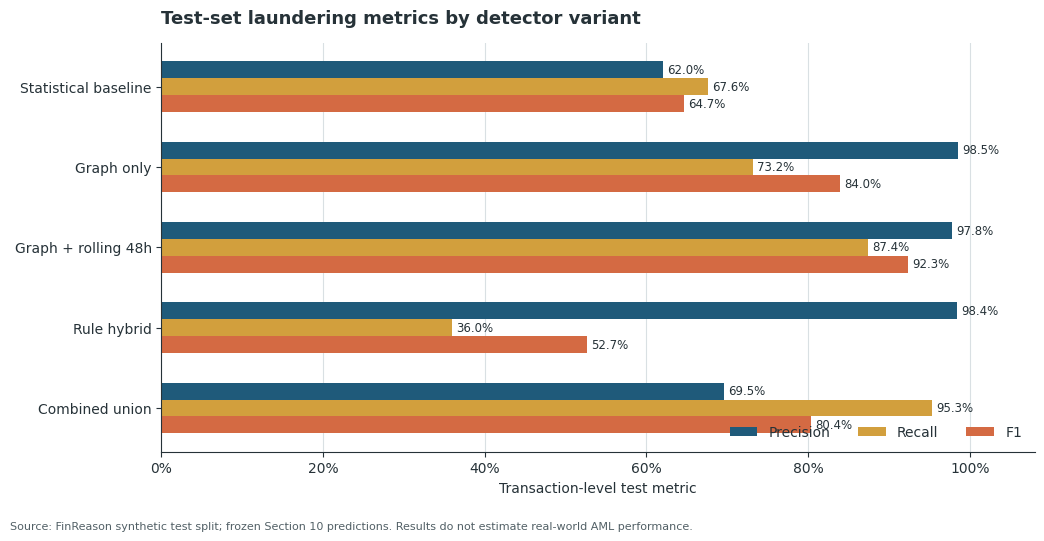

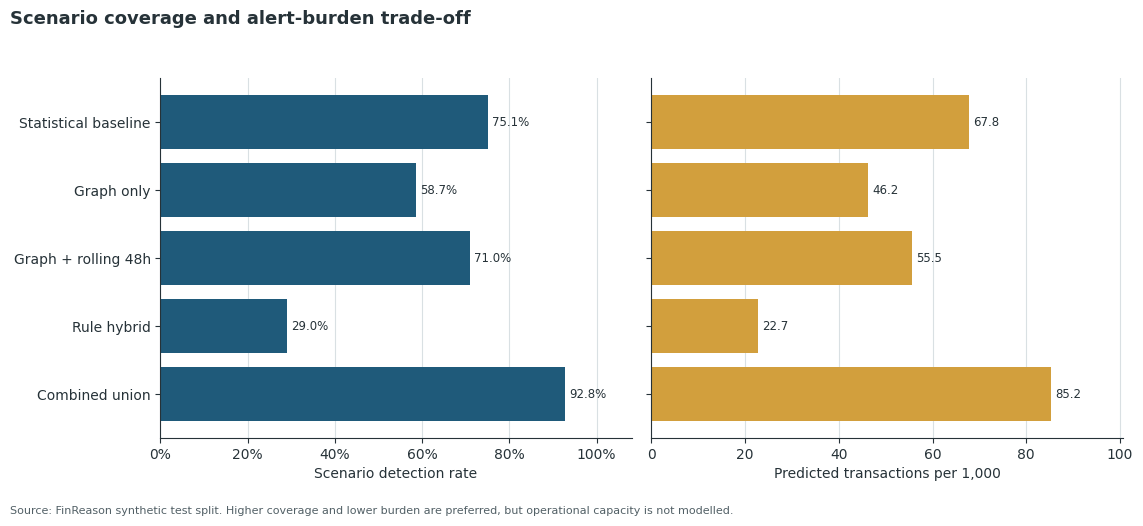

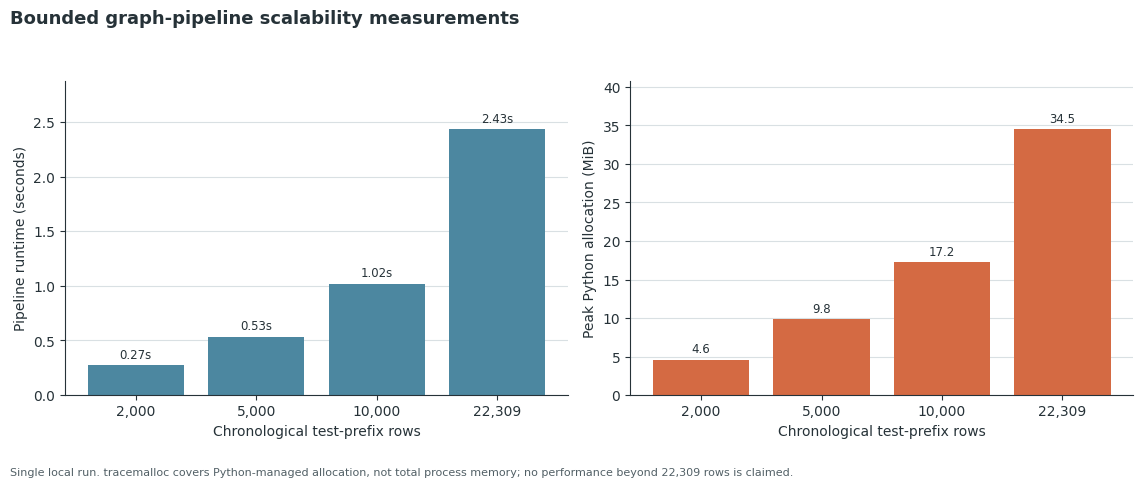

Exported and re-opened 6 figure files.


In [90]:
SECTION12_COLORS = {
    'navy': '#1F5A7A', 'blue': '#4C87A0', 'gold': '#D29F3D',
    'orange': '#D46A43', 'charcoal': '#263238', 'grid': '#D9E0E3',
}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': SECTION12_COLORS['charcoal'],
    'axes.labelcolor': SECTION12_COLORS['charcoal'],
    'text.color': SECTION12_COLORS['charcoal'], 'font.size': 10,
    'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.labelsize': 10, 'xtick.color': SECTION12_COLORS['charcoal'],
    'ytick.color': SECTION12_COLORS['charcoal'],
})

section12_figure_paths = []
scorecard_plot = section12_scorecard_df.set_index('variant').loc[SECTION12_VARIANT_ORDER]
variant_labels = [SECTION12_VARIANT_LABELS[name] for name in SECTION12_VARIANT_ORDER]

# Figure 1: comparable rate metrics on one axis.
metric_specs = [
    ('precision', 'Precision', SECTION12_COLORS['navy']),
    ('recall', 'Recall', SECTION12_COLORS['gold']),
    ('f1', 'F1', SECTION12_COLORS['orange']),
]
y = np.arange(len(SECTION12_VARIANT_ORDER))
bar_height = 0.21
fig, ax = plt.subplots(figsize=(10.5, 5.4))
for index, (column, label, color) in enumerate(metric_specs):
    values = scorecard_plot[column].to_numpy(dtype=float)
    positions = y + (index - 1) * bar_height
    bars = ax.barh(positions, values, height=bar_height, label=label, color=color)
    ax.bar_label(bars, labels=[f'{value:.1%}' for value in values],
                 padding=3, fontsize=8.5)
ax.set_yticks(y, variant_labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('Transaction-level test metric')
ax.set_title('Test-set laundering metrics by detector variant', loc='left', pad=14)
ax.grid(axis='x', color=SECTION12_COLORS['grid'], linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3, loc='lower right')
fig.text(0.01, 0.01,
         'Source: FinReason synthetic test split; frozen Section 10 predictions. '
         'Results do not estimate real-world AML performance.', fontsize=8, color='#526066')
fig.tight_layout(rect=(0, 0.045, 1, 1))
for suffix in ('png', 'svg'):
    path = PATHS['figures'] / f'section12_test_laundering_metrics.{suffix}'
    fig.savefig(path, dpi=180 if suffix == 'png' else None, bbox_inches='tight')
    section12_figure_paths.append(path)
plt.show()

# Figure 2: separate panels keep coverage and workload readable without a dual axis.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2), sharey=True)
scenario_values = scorecard_plot['scenario_detection_rate'].to_numpy(dtype=float)
burden_values = scorecard_plot['alert_burden_per_1000'].to_numpy(dtype=float)
scenario_bars = axes[0].barh(y, scenario_values, color=SECTION12_COLORS['navy'])
axes[0].bar_label(scenario_bars, labels=[f'{value:.1%}' for value in scenario_values],
                  padding=3, fontsize=8.5)
axes[0].set_xlim(0, 1.08)
axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_xlabel('Scenario detection rate')
axes[0].set_yticks(y, variant_labels)
axes[0].invert_yaxis()
burden_limit = max(burden_values) * 1.18
burden_bars = axes[1].barh(y, burden_values, color=SECTION12_COLORS['gold'])
axes[1].bar_label(burden_bars, labels=[f'{value:.1f}' for value in burden_values],
                  padding=3, fontsize=8.5)
axes[1].set_xlim(0, burden_limit)
axes[1].set_xlabel('Predicted transactions per 1,000')
for axis in axes:
    axis.grid(axis='x', color=SECTION12_COLORS['grid'], linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[['top', 'right']].set_visible(False)
fig.suptitle('Scenario coverage and alert-burden trade-off', x=0.01, ha='left',
             fontsize=13, fontweight='bold')
fig.text(0.01, 0.01,
         'Source: FinReason synthetic test split. Higher coverage and lower burden are preferred, '
         'but operational capacity is not modelled.', fontsize=8, color='#526066')
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
for suffix in ('png', 'svg'):
    path = PATHS['figures'] / f'section12_operational_tradeoffs.{suffix}'
    fig.savefig(path, dpi=180 if suffix == 'png' else None, bbox_inches='tight')
    section12_figure_paths.append(path)
plt.show()

# Figure 3: four discrete, measured prefixes—not an extrapolated continuous trend.
scale_plot = section11_scalability_df.sort_values('sample_rows').copy()
scale_labels = [f'{int(value):,}' for value in scale_plot['sample_rows']]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
runtime_bars = axes[0].bar(scale_labels, scale_plot['pipeline_seconds'],
                           color=SECTION12_COLORS['blue'])
axes[0].bar_label(runtime_bars,
                  labels=[f'{value:.2f}s' for value in scale_plot['pipeline_seconds']],
                  padding=3, fontsize=8.5)
axes[0].set_ylim(0, scale_plot['pipeline_seconds'].max() * 1.18)
axes[0].set_ylabel('Pipeline runtime (seconds)')
memory_bars = axes[1].bar(scale_labels, scale_plot['peak_python_allocation_mib'],
                          color=SECTION12_COLORS['orange'])
axes[1].bar_label(memory_bars,
                  labels=[f'{value:.1f}' for value in scale_plot['peak_python_allocation_mib']],
                  padding=3, fontsize=8.5)
axes[1].set_ylim(0, scale_plot['peak_python_allocation_mib'].max() * 1.18)
axes[1].set_ylabel('Peak Python allocation (MiB)')
for axis in axes:
    axis.set_xlabel('Chronological test-prefix rows')
    axis.grid(axis='y', color=SECTION12_COLORS['grid'], linewidth=0.8)
    axis.set_axisbelow(True)
    axis.spines[['top', 'right']].set_visible(False)
fig.suptitle('Bounded graph-pipeline scalability measurements', x=0.01, ha='left',
             fontsize=13, fontweight='bold')
fig.text(0.01, 0.01,
         'Single local run. tracemalloc covers Python-managed allocation, not total process memory; '
         'no performance beyond 22,309 rows is claimed.', fontsize=8, color='#526066')
fig.tight_layout(rect=(0, 0.055, 1, 0.93))
for suffix in ('png', 'svg'):
    path = PATHS['figures'] / f'section12_scalability_benchmarks.{suffix}'
    fig.savefig(path, dpi=180 if suffix == 'png' else None, bbox_inches='tight')
    section12_figure_paths.append(path)
plt.show()

for figure_path in section12_figure_paths:
    assert figure_path.exists() and figure_path.stat().st_size > 0
for png_path in [path for path in section12_figure_paths if path.suffix == '.png']:
    image_array = plt.imread(png_path)
    assert image_array.ndim >= 2 and min(image_array.shape[:2]) >= 500
print(f'Exported and re-opened {len(section12_figure_paths)} figure files.')

### 12.3 Preserve four representative demonstration cases

In [91]:
def section12_transaction_ids(value):
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []
    values = value.split('|') if isinstance(value, str) else list(value)
    return [str(item) for item in values if str(item).strip()]


section12_truth_lookup = finreason_evaluation_truth_df.set_index(
    finreason_evaluation_truth_df['transaction_id'].astype(str)
)['is_laundering'].astype(int).to_dict()
section12_membership = scenario_evaluation_membership_df.copy()
section12_membership['transaction_id'] = section12_membership['transaction_id'].astype(str)
section12_membership['scenario_id'] = section12_membership['scenario_id'].astype(str)
section12_tx_to_scenarios = section12_membership.groupby('transaction_id')['scenario_id'].agg(
    lambda values: tuple(sorted(set(values)))
).to_dict()
section12_scenario_lookup = scenario_evaluation_truth_df.assign(
    scenario_id=scenario_evaluation_truth_df['scenario_id'].astype(str)
).set_index('scenario_id').to_dict(orient='index')

def section12_annotate_evidence(frame):
    annotated = frame.copy()
    annotated['_transaction_id_list'] = annotated['transaction_ids'].map(
        section12_transaction_ids
    )
    annotated['_positive_transaction_count'] = annotated['_transaction_id_list'].map(
        lambda values: sum(section12_truth_lookup.get(value, 0) for value in values)
    )
    annotated['_scenario_ids'] = annotated['_transaction_id_list'].map(
        lambda values: tuple(sorted({
            scenario_id for value in values
            for scenario_id in section12_tx_to_scenarios.get(value, ())
        }))
    )
    return annotated


test_evidence = section12_annotate_evidence(
    heldout_evidence_df.loc[heldout_evidence_df['split'].eq('test')]
)
graph_tp_candidates = test_evidence.loc[
    test_evidence['detector_family'].eq('GRAPH')
    & test_evidence['_positive_transaction_count'].gt(0)
].sort_values(['_positive_transaction_count', 'alert_id'], ascending=[False, True])
rule_tp_candidates = test_evidence.loc[
    test_evidence['detector_family'].eq('RULE')
    & test_evidence['_positive_transaction_count'].gt(0)
].assign(
    _priority=lambda frame: frame['alert_type'].map({
        'CRITICAL_CASE': 0, 'MULTI_INDICATOR_CASE': 1,
    }).fillna(2)
).sort_values(['_priority', '_positive_transaction_count', 'alert_id'],
              ascending=[True, False, True])
statistical_fp_candidates = test_evidence.loc[
    test_evidence['detector_family'].isin(
        {'STATISTICAL_AMOUNT', 'STATISTICAL_ROLLING'}
    )
    & test_evidence['_positive_transaction_count'].eq(0)
].assign(
    _evidence_size=lambda frame: frame['_transaction_id_list'].map(len)
).sort_values(['_evidence_size', 'alert_id'], ascending=[False, True])

assert not graph_tp_candidates.empty
assert not rule_tp_candidates.empty
assert not statistical_fp_candidates.empty
graph_tp = graph_tp_candidates.iloc[0]
rule_tp = rule_tp_candidates.iloc[0]
statistical_fp = statistical_fp_candidates.iloc[0]

graph_fn_typology = section11_error_typology_df.loc[
    section11_error_typology_df['split'].eq('test')
    & section11_error_typology_df['variant'].eq('GRAPH_ONLY')
    & section11_error_typology_df['error_type'].eq('FALSE_NEGATIVE')
].sort_values(['scenario_count', 'scenario_type'], ascending=[False, True])
assert not graph_fn_typology.empty
graph_fn_row = graph_fn_typology.iloc[0]
graph_fn_scenario_id = str(graph_fn_row['example_scenario_id'])
graph_fn_transaction_ids = sorted(section12_membership.loc[
    section12_membership['scenario_id'].eq(graph_fn_scenario_id), 'transaction_id'
].tolist())
assert graph_fn_transaction_ids

def section12_primary_scenario(evidence_row):
    candidates = list(evidence_row['_scenario_ids'])
    positive = [
        scenario_id for scenario_id in candidates
        if int(section12_scenario_lookup.get(scenario_id, {}).get('is_laundering', 0)) == 1
    ]
    return (positive or candidates or [None])[0]


graph_tp_scenario = section12_primary_scenario(graph_tp)
rule_tp_scenario = section12_primary_scenario(rule_tp)
statistical_fp_scenario = section12_primary_scenario(statistical_fp)
demo_records = [
    {
        'case_id': 'D01_GRAPH_TRUE_POSITIVE', 'case_role': 'successful structural detection',
        'variant': 'GRAPH_ONLY', 'outcome': 'TRUE_POSITIVE',
        'alert_or_scenario_id': graph_tp['alert_id'],
        'scenario_id': graph_tp_scenario,
        'scenario_type': section12_scenario_lookup.get(graph_tp_scenario, {}).get(
            'scenario_type', 'UNMAPPED'
        ),
        'transaction_count': len(graph_tp['_transaction_id_list']),
        'summary': graph_tp['explanation'],
    },
    {
        'case_id': 'D02_RULE_TRUE_POSITIVE', 'case_role': 'recursive rule explanation',
        'variant': 'RULE_HYBRID', 'outcome': 'TRUE_POSITIVE',
        'alert_or_scenario_id': rule_tp['alert_id'],
        'scenario_id': rule_tp_scenario,
        'scenario_type': section12_scenario_lookup.get(rule_tp_scenario, {}).get(
            'scenario_type', 'UNMAPPED'
        ),
        'transaction_count': len(rule_tp['_transaction_id_list']),
        'summary': rule_tp['explanation'],
    },
    {
        'case_id': 'D03_STATISTICAL_FALSE_POSITIVE',
        'case_role': 'workload and specificity limitation',
        'variant': 'STATISTICAL_BASELINE', 'outcome': 'FALSE_POSITIVE',
        'alert_or_scenario_id': statistical_fp['alert_id'],
        'scenario_id': statistical_fp_scenario,
        'scenario_type': section12_scenario_lookup.get(statistical_fp_scenario, {}).get(
            'scenario_type', 'NORMAL_OR_UNMAPPED'
        ),
        'transaction_count': len(statistical_fp['_transaction_id_list']),
        'summary': statistical_fp['explanation'],
    },
    {
        'case_id': 'D04_GRAPH_FALSE_NEGATIVE',
        'case_role': 'known structural coverage limitation',
        'variant': 'GRAPH_ONLY', 'outcome': 'FALSE_NEGATIVE',
        'alert_or_scenario_id': graph_fn_scenario_id,
        'scenario_id': graph_fn_scenario_id,
        'scenario_type': graph_fn_row['scenario_type'],
        'transaction_count': len(graph_fn_transaction_ids),
        'summary': (
            f"Graph-only missed this planted {graph_fn_row['scenario_type']} test scenario; "
            'it is retained to demonstrate the boundary of the configured graph motifs.'
        ),
    },
]
section12_demo_cases_df = pd.DataFrame(demo_records)

rule_fact_id = str(rule_tp['alert_id']).removeprefix('TEST-')
rule_knowledge_base = heldout_hybrid_runs['test']['knowledge_base']
assert rule_fact_id in rule_knowledge_base.facts
rule_provenance = rule_knowledge_base.provenance_chain(rule_fact_id)
rule_explanations = [
    explanation.to_dict()
    for explanation in rule_knowledge_base.explanations.values()
    if explanation.conclusion_fact_id in {
        fact['fact_id'] for fact in rule_provenance['facts']
    }
]
assert rule_provenance['facts'] and rule_explanations

section12_demo_bundle = {
    'selection_policy': (
        'Deterministic examples from frozen test evidence: strongest evidenced graph TP; '
        'highest-priority evidenced rule TP; largest statistical FP evidence; most frequent '
        'graph-only false-negative typology.'
    ),
    'legal_determination': False,
    'cases': {
        'D01_GRAPH_TRUE_POSITIVE': {
            'evidence': graph_tp.drop(labels=[
                '_transaction_id_list', '_positive_transaction_count', '_scenario_ids'
            ]).to_dict(),
            'transaction_ids': graph_tp['_transaction_id_list'],
        },
        'D02_RULE_TRUE_POSITIVE': {
            'evidence': rule_tp.drop(labels=[
                '_transaction_id_list', '_positive_transaction_count', '_scenario_ids',
                '_priority'
            ], errors='ignore').to_dict(),
            'transaction_ids': rule_tp['_transaction_id_list'],
            'provenance_chain': rule_provenance,
            'explanations': rule_explanations,
        },
        'D03_STATISTICAL_FALSE_POSITIVE': {
            'evidence': statistical_fp.drop(labels=[
                '_transaction_id_list', '_positive_transaction_count', '_scenario_ids',
                '_evidence_size'
            ], errors='ignore').to_dict(),
            'transaction_ids': statistical_fp['_transaction_id_list'],
        },
        'D04_GRAPH_FALSE_NEGATIVE': {
            'scenario': section12_scenario_lookup[graph_fn_scenario_id],
            'transaction_ids': graph_fn_transaction_ids,
        },
    },
}
assert section12_demo_cases_df['case_id'].is_unique
assert set(section12_demo_cases_df['outcome']) == {
    'TRUE_POSITIVE', 'FALSE_POSITIVE', 'FALSE_NEGATIVE'
}
display(section12_demo_cases_df)

,case_id,case_role,variant,outcome,alert_or_scenario_id,scenario_id,scenario_type,transaction_count,summary
0,D01_GRAPH_TRUE_POSITIVE,successful structural detection,GRAPH_ONLY,TRUE_POSITIVE,TEST-BFS-000076,SCN-00670,HIGH_FREQUENCY,17,fan-out detected: FR:ACC-003000 connected to 8...
1,D02_RULE_TRUE_POSITIVE,recursive rule explanation,RULE_HYBRID,TRUE_POSITIVE,TEST-FACT-0E283D96AEC85EDE,SCN-00900,STRUCTURING_FANOUT,8,Critical case escalation fired because the rev...
2,D03_STATISTICAL_FALSE_POSITIVE,workload and specificity limitation,STATISTICAL_BASELINE,FALSE_POSITIVE,LZAMT-001663,None,NORMAL_OR_UNMAPPED,1,"Amount 221,343.89 USD has a training-only uppe..."
3,D04_GRAPH_FALSE_NEGATIVE,known structural coverage limitation,GRAPH_ONLY,FALSE_NEGATIVE,SCN-00003,SCN-00003,STRUCTURING,7,Graph-only missed this planted STRUCTURING tes...


### 12.4 State evidence-backed conclusions and mandatory caveats

In [92]:
section12_rows = section12_scorecard_df.set_index('variant')
graph_result = section12_rows.loc['GRAPH_ONLY']
hybrid_result = section12_rows.loc['GRAPH_ROLLING_HYBRID']
combined_result = section12_rows.loc['COMBINED_UNION']
rule_result = section12_rows.loc['RULE_HYBRID']
baseline_result = section12_rows.loc['STATISTICAL_BASELINE']
largest_scale_result = section11_scalability_df.sort_values('sample_rows').iloc[-1]

section12_claims_df = pd.DataFrame([
    {
        'claim_id': 'C01',
        'verified_finding': (
            f"Graph + rolling 48h achieved test laundering precision "
            f"{hybrid_result['precision']:.4f}, recall {hybrid_result['recall']:.4f} "
            f"and F1 {hybrid_result['f1']:.4f}."
        ),
        'evidence': 'section12_final_scorecard.csv; section12_test_laundering_metrics.png',
        'scope_and_caveat': (
            'FinReason synthetic test split only; validation results are reported alongside '
            'test and no production ranking is claimed.'
        ),
    },
    {
        'claim_id': 'C02',
        'verified_finding': (
            f"Adding rolling frequency changed graph recall from {graph_result['recall']:.4f} "
            f"to {hybrid_result['recall']:.4f}, with precision changing from "
            f"{graph_result['precision']:.4f} to {hybrid_result['precision']:.4f}."
        ),
        'evidence': 'section12_final_scorecard.csv; section11_ablation.csv',
        'scope_and_caveat': (
            f"Alert burden changed from {graph_result['alert_burden_per_1000']:.1f} to "
            f"{hybrid_result['alert_burden_per_1000']:.1f} per 1,000 transactions."
        ),
    },
    {
        'claim_id': 'C03',
        'verified_finding': (
            f"Rule-hybrid evidence was fully traceable and achieved {rule_result['precision']:.4f} "
            'precision while retaining recursive fact/rule provenance.'
        ),
        'evidence': 'section12_demo_cases.json; section10_audit_completeness.csv',
        'scope_and_caveat': 'Rules are review indicators with experimental thresholds, not legal conclusions.',
    },
    {
        'claim_id': 'C04',
        'verified_finding': (
            f"All {executed_test_count} automated tests, {len(integration_checks)} integration "
            f"checks and {len(determinism_checks)} determinism checks passed."
        ),
        'evidence': 'section11_testing_report.json; section11_unittest.log',
        'scope_and_caveat': 'Passing repository tests does not substitute for independent model validation.',
    },
    {
        'claim_id': 'C05',
        'verified_finding': (
            f"The complete {int(largest_scale_result['sample_rows']):,}-row test graph ran in "
            f"{largest_scale_result['pipeline_seconds']:.3f}s with "
            f"{largest_scale_result['peak_python_allocation_mib']:.2f} MiB peak Python allocation."
        ),
        'evidence': 'section11_scalability.csv; section12_scalability_benchmarks.png',
        'scope_and_caveat': 'Single local run; no multi-million-edge or total-process-memory claim.',
    },
    {
        'claim_id': 'C06',
        'verified_finding': (
            f"The rolling detector used a {ROLLING_WINDOW_HOURS:g}-hour horizon while peaking "
            f"at {rolling_frequency_model.last_score_metadata['peak_active_events']} active "
            'events across the scored stream.'
        ),
        'evidence': 'section9_baseline_report.json; section9_rolling_calibration.csv',
        'scope_and_caveat': 'Bounded synthetic run; state size depends on real transaction velocity.',
    },
])

section12_limitations_df = pd.DataFrame([
    {'limitation_id': 'L01', 'area': 'Data validity',
     'limitation': 'Headline results use planted synthetic labels and behaviours.',
     'required_follow_up': 'Validate on institution-approved, temporally separated real cases.'},
    {'limitation_id': 'L02', 'area': 'External validity',
     'limitation': 'PaySim fraud is not treated as laundering; IBM is kept as separate AML context.',
     'required_follow_up': 'Design source-specific adapters and evaluation protocols before comparison.'},
    {'limitation_id': 'L03', 'area': 'Thresholds',
     'limitation': 'Parameters were selected on the synthetic training split.',
     'required_follow_up': 'Recalibrate under documented change control on an independent development set.'},
    {'limitation_id': 'L04', 'area': 'Operations',
     'limitation': 'Review capacity, investigation cost and alert prioritisation are not simulated.',
     'required_follow_up': 'Run a capacity-aware shadow evaluation with investigators.'},
    {'limitation_id': 'L05', 'area': 'Performance',
     'limitation': 'Graph scaling is bounded; rolling-state peaks depend on transaction velocity.',
     'required_follow_up': 'Benchmark partitioned streams and total-process memory on target infrastructure.'},
    {'limitation_id': 'L06', 'area': 'Governance',
     'limitation': 'No fairness, drift, privacy-impact or independent compliance validation is claimed.',
     'required_follow_up': 'Complete governance review before any operational pilot.'},
])
assert section12_claims_df['claim_id'].is_unique
assert section12_limitations_df['limitation_id'].is_unique
display(section12_claims_df)
display(section12_limitations_df)

,claim_id,verified_finding,evidence,scope_and_caveat
0,C01,Graph + rolling 48h achieved test laundering p...,section12_final_scorecard.csv; section12_test_...,FinReason synthetic test split only; validatio...
1,C02,Adding rolling frequency changed graph recall ...,section12_final_scorecard.csv; section11_ablat...,"Alert burden changed from 46.2 to 55.5 per 1,0..."
2,C03,Rule-hybrid evidence was fully traceable and a...,section12_demo_cases.json; section10_audit_com...,Rules are review indicators with experimental ...
3,C04,"All 66 automated tests, 11 integration checks ...",section11_testing_report.json; section11_unitt...,Passing repository tests does not substitute f...
4,C05,"The complete 22,309-row test graph ran in 2.43...",section11_scalability.csv; section12_scalabili...,Single local run; no multi-million-edge or tot...
5,C06,The rolling detector used a 48-hour horizon wh...,section9_baseline_report.json; section9_rollin...,Bounded synthetic run; state size depends on r...


,limitation_id,area,limitation,required_follow_up
0,L01,Data validity,Headline results use planted synthetic labels ...,"Validate on institution-approved, temporally s..."
1,L02,External validity,PaySim fraud is not treated as laundering; IBM...,Design source-specific adapters and evaluation...
2,L03,Thresholds,Parameters were selected on the synthetic trai...,Recalibrate under documented change control on...
3,L04,Operations,"Review capacity, investigation cost and alert ...",Run a capacity-aware shadow evaluation with in...
4,L05,Performance,Graph scaling is bounded; rolling-state peaks ...,Benchmark partitioned streams and total-proces...
5,L06,Governance,"No fairness, drift, privacy-impact or independ...",Complete governance review before any operatio...


### 12.5 Save the final evidence 

In [93]:
section12_scorecard_path = PATHS['tables'] / 'section12_final_scorecard.csv'
section12_claims_path = PATHS['tables'] / 'section12_claims_and_caveats.csv'
section12_limitations_path = PATHS['tables'] / 'section12_limitations.csv'
section12_demo_cases_path = PATHS['tables'] / 'section12_demo_cases.csv'
section12_demo_bundle_path = PATHS['audit_trails'] / 'section12_demo_cases.json'
section12_report_path = PATHS['audit_trails'] / 'section12_final_report.json'
section12_manifest_path = PATHS['audit_trails'] / 'section12_artifact_manifest.csv'

section12_scorecard_df.drop(columns=['operational_role'], errors='ignore').to_csv(
    section12_scorecard_path, index=False
)
section12_claims_df.to_csv(section12_claims_path, index=False)
section12_limitations_df.to_csv(section12_limitations_path, index=False)
section12_demo_cases_df.to_csv(section12_demo_cases_path, index=False)
section12_demo_bundle_path.write_text(
    json.dumps(
        section12_demo_bundle, indent=2,
        default=lambda value: value.item() if isinstance(value, np.generic) else str(value),
    ), encoding='utf-8'
)

section12_runbook = '\n'.join([
    '# FinReason video demonstration runbook',
    '', '## Scope statement', '',
    'The demonstration uses the FinReason synthetic test split. PaySim fraud and IBM AML are ',
    'separate context datasets. Alerts are indicators for human review, not legal determinations.',
    '', '## Suggested sequence', '',
    f'1. **Reproducibility:** show the Section 11 result: {executed_test_count} automated tests ',
    f'   passed, alongside the frozen Section 10 ledger hash '
    f'`{section10_prediction_ledger_sha256[:16]}…`.',
    '2. **Graph success:** open `D01_GRAPH_TRUE_POSITIVE` in `section12_demo_cases.json`; ',
    '   follow its source transaction IDs and time-respecting structural explanation.',
    '3. **Rule explanation:** open `D02_RULE_TRUE_POSITIVE`; show the recursive fact chain, ',
    '   fired rule IDs, source-record IDs and the explicit human-review statement.',
    '4. **False-positive burden:** show `D03_STATISTICAL_FALSE_POSITIVE`, then the operational ',
    '   trade-off figure. Explain that anomaly breadth increases review workload.',
    '5. **Known miss:** show `D04_GRAPH_FALSE_NEGATIVE`. Explain which planted scenario type ',
    '   was missed and why the configured graph motifs are not complete coverage.',
    '6. **Measured comparison:** show the test metrics and scalability figures; quote only ',
    '   values in `section12_final_scorecard.csv` and `section11_scalability.csv`.',
    '7. **Close with limitations:** show `section12_limitations.csv`; do not claim production ',
    '   readiness or real-world prevalence/performance.',
    '', '## Files to keep together', '',
    '- `section12_final_scorecard.csv`',
    '- `section12_claims_and_caveats.csv`',
    '- `section12_demo_cases.json`',
    '- the three Section 12 PNG figures',
    '- `section12_artifact_manifest.csv`',
    '',
])

section12_artifact_specs = [
    ('table', section12_scorecard_path, 'Exact held-out test scorecard'),
    ('table', section12_claims_path, 'Bounded findings with evidence and caveats'),
    ('table', section12_limitations_path, 'Mandatory interpretation limitations'),
    ('table', section12_demo_cases_path, 'Four-case demonstration index'),
    ('audit', section12_demo_bundle_path, 'Detailed evidence and rule provenance'),
    *[('figure', path, 'Report-ready result figure') for path in section12_figure_paths],
    ('upstream_audit', section9_report_path, 'Section 9 rolling-state and calibration source'),
    ('upstream_table', section10_tradeoffs_path, 'Section 10 metric source'),
    ('upstream_table', section11_scalability_path, 'Section 11 scale source'),
    ('upstream_audit', section11_report_path, 'Section 11 verification source'),
    ('final_audit', section12_report_path, 'Section 12 summary and checks'),
]

section12_notebook_path = PROJECT_ROOT / 'FinReason_Implementation.ipynb'
notebook_payload = json.loads(section12_notebook_path.read_text(encoding='utf-8'))
notebook_markdown = [
    ''.join(cell.get('source', [])) if isinstance(cell.get('source', []), list)
    else cell.get('source', '')
    for cell in notebook_payload['cells'] if cell.get('cell_type') == 'markdown'
]
section12_validation_checks = {
    'all_twelve_section_headings_present': all(
        any(text.startswith(f'# Section {number} ') or text.startswith(f'# Section {number} —')
            for text in notebook_markdown)
        for number in range(1, 13)
    ),
    'required_upstream_artifacts_present': not missing_section12_inputs,
    'source_boundaries_remain_separate': source_evaluation_boundaries_df[
        'pooled_into_headline'
    ].eq(False).all(),
    'scorecard_matches_frozen_variants': (
        section12_scorecard_df['variant'].tolist() == SECTION12_VARIANT_ORDER
    ),
    'audit_completeness_is_total': section12_scorecard_df[
        'audit_completeness_rate'
    ].eq(1).all(),
    'four_demo_cases_cover_success_and_failure': (
        len(section12_demo_cases_df) == 4
        and {'TRUE_POSITIVE', 'FALSE_POSITIVE', 'FALSE_NEGATIVE'}
        <= set(section12_demo_cases_df['outcome'])
    ),
    'figures_exported_and_readable': all(
        path.exists() and path.stat().st_size > 0 for path in section12_figure_paths
    ),
    'section11_validation_passed': all(section11_validation_checks.values()),
    'automated_tests_passed': unit_test_status == 'PASS',
}
section12_validation_checks = {
    key: bool(value) for key, value in section12_validation_checks.items()
}
assert all(section12_validation_checks.values()), section12_validation_checks

section12_summary = {
    'section': 12, 'version': SECTION_12_VERSION, 'status': 'COMPLETE',
    'headline_source': 'finreason_synthetic', 'headline_split': 'test',
    'headline_label': 'is_laundering',
    'best_test_f1_variant': section12_scorecard_df.sort_values(
        'f1', ascending=False
    ).iloc[0]['variant'],
    'best_test_f1': float(section12_scorecard_df['f1'].max()),
    'demo_case_count': len(section12_demo_cases_df),
    'figure_file_count': len(section12_figure_paths),
    'manifest_entry_count': len(section12_artifact_specs),
    'share_status': 'SHARE_WITH_CAVEATS',
    'production_ready': False,
    'legal_determination': False,
    'validation_checks': section12_validation_checks,
    'limitations': section12_limitations_df['limitation'].tolist(),
}
section12_report_path.write_text(
    json.dumps(section12_summary, indent=2), encoding='utf-8'
)

manifest_records = []
for artifact_type, artifact_path, purpose in section12_artifact_specs:
    artifact_path = Path(artifact_path)
    assert artifact_path.exists() and artifact_path.stat().st_size > 0, artifact_path
    manifest_records.append({
        'artifact_type': artifact_type,
        'path': str(artifact_path.relative_to(PROJECT_ROOT)),
        'purpose': purpose,
        'bytes': artifact_path.stat().st_size,
        'sha256': hashlib.sha256(artifact_path.read_bytes()).hexdigest(),
    })
section12_artifact_manifest_df = pd.DataFrame(manifest_records)
assert section12_artifact_manifest_df['path'].is_unique
assert section12_artifact_manifest_df['sha256'].str.fullmatch(r'[0-9a-f]{64}').all()
section12_artifact_manifest_df.to_csv(section12_manifest_path, index=False)
assert section12_manifest_path.exists() and section12_manifest_path.stat().st_size > 0

display(section12_artifact_manifest_df)
print(json.dumps({
    **section12_summary,
    'artifact_manifest': str(section12_manifest_path.resolve())
}, indent=2))

,artifact_type,path,purpose,bytes,sha256
0,table,workspace/outputs/tables/section12_final_score...,Exact held-out test scorecard,1399,90b7276d2d08762d332cbe7664ae265bd7ff45122596a0...
1,table,workspace/outputs/tables/section12_claims_and_...,Bounded findings with evidence and caveats,1540,3b9689b8d50338f1d8ec435784c97f808b77971b082c06...
2,table,workspace/outputs/tables/section12_limitations...,Mandatory interpretation limitations,1017,fbdcf1aa8b6eb91a676cde72fcdf15a5787c40375aed31...
3,table,workspace/outputs/tables/section12_demo_cases.csv,Four-case demonstration index,1159,d032309ef3dda98ad6ae816ba5e73c207f3bec8aa235cc...
4,audit,workspace/outputs/audit_trails/section12_demo_...,Detailed evidence and rule provenance,17398,4ae5cf4d11d51b0c7a69ed9854b2190ffd2a80ca851e02...
5,figure,workspace/outputs/figures/section12_test_laund...,Report-ready result figure,98795,861541e0ef0fafcf1b4214328d982c87e403fdcaedfa12...
6,figure,workspace/outputs/figures/section12_test_laund...,Report-ready result figure,69691,35276db9aed875221b3659b47c657db14f0f2d662ab255...
7,figure,workspace/outputs/figures/section12_operationa...,Report-ready result figure,86165,627f70988ebb0d3942bba5205c8ef29c9bdb99885fe719...
8,figure,workspace/outputs/figures/section12_operationa...,Report-ready result figure,69554,01b1afe779cdaa6f2e96efc1bc48e50e9fa52a12a9b7a9...
9,figure,workspace/outputs/figures/section12_scalabilit...,Report-ready result figure,90088,f3ddb4721e237e522d9f8b343fcd223ec1e2b6d69df991...


{
  "section": 12,
  "version": "conclusions-demonstration-v1",
  "status": "COMPLETE",
  "headline_source": "finreason_synthetic",
  "headline_split": "test",
  "headline_label": "is_laundering",
  "best_test_f1_variant": "GRAPH_ROLLING_HYBRID",
  "best_test_f1": 0.9230769230769231,
  "demo_case_count": 4,
  "figure_file_count": 6,
  "manifest_entry_count": 16,
  "share_status": "SHARE_WITH_CAVEATS",
  "production_ready": false,
  "legal_determination": false,
  "validation_checks": {
    "all_twelve_section_headings_present": true,
    "required_upstream_artifacts_present": true,
    "source_boundaries_remain_separate": true,
    "scorecard_matches_frozen_variants": true,
    "audit_completeness_is_total": true,
    "four_demo_cases_cover_success_and_failure": true,
    "figures_exported_and_readable": true,
    "section11_validation_passed": true,
    "automated_tests_passed": true
  },
  "limitations": [
    "Headline results use planted synthetic labels and behaviours.",
    "PayS